# 헤어살롱 본점 — 예약데이터 분석 (재현 검증본)

분석 기간 **2025-01-01 ~ 2026-08-23**. 원천은 `data/processed/*.parquet` — 원본 엑셀은 다시 파싱하지 않는다.

---

## 반드시 지킨 규칙 4가지

1. **시간대·요일 분석은 `use_dt`(이용일시) 기준.** `done_dt`(이용완료일시)는 시술 종료가 아니라 정산 배치 시각이라
   오전에 몰려 있다. **⑥ 운영 패턴에서만** "정산 시각"으로서 의도적으로 사용한다.
2. **`reservations` 와 `hands_all` 을 concat 하지 않는다.** 핸즈의 네이버행은 예약 테이블과 같은 예약이고,
   조인 결과는 이미 `reservations` 에 병합돼 있다. ⑫에서만 `hands_all` 의 **매장직접(비네이버) 행**을 따로 본다.
3. **고객 식별은 `cust_key`(성 1글자 + 전화번호 뒤 4자리) 하나로 통일.** 다른 키를 만들지 않는다.
4. **금액은 `paid`(실결제금액, 예약 단위) 기준.** `listed`(옵션 라인 합계)는 ⑧ 맥락에서만 참조한다.

---

## 이 노트북에서 내린 정의 판단

다른 경로의 결과와 대조할 때 **차이의 원인이 될 수 있는 지점**만 모았다.

| # | 쟁점 | 이 노트북의 정의 |
|---|---|---|
| 공통 | 시술 대분류 매핑 | `data/processed/menu_category.csv` **단일 기준** (사용자 지시). 카테고리 9종. 프롬프트의 키워드 규칙과의 차이는 §0-3에 대조표로 남김 |
| 공통 | 대표 시술 | 우선순위 `탈색 > 펌 > 염색 > 컷 > 클리닉 > 스타일링 > 기타 > 확인필요`. `비시술`(선불권 3행)은 분석 제외 |
| ③ | 시술 구성비 단위 | **메뉴 라인 단위** (한 예약에 탈색+염색이 있으면 둘 다 카운트) |
| ③ | "금액 0원 무료 클리닉" | `category=='클리닉' and line_price==0` 인 라인을 제외 후 재정규화 |
| ② | 취소사유 분류 | 공백 제거 후 순서대로 매칭: 날짜변경 → 시간변경 → 다시예약 → 기타. 사유 미기재는 **별도 행**으로 표기 |
| ② | 순이탈 | 취소건 중 ±45일 내 완료 방문이 **없는** 건 ÷ 전체 예약 |
| ⑤ | "첫방문 50%할인 채널" | 이 값은 `channel`(유입경로)이 아니라 **`designer` 컬럼**에 들어 있다 (413건). designer 문자열로 판정 |
| ⑥ | 영업시간 | `10 <= hour <= 20`. 밖 = `hour < 10 or hour > 20` |
| ⑥ | 심야 | `hour in {22,23,0,1,2}` (02시 포함) |
| ⑥ | 자동확정 | `conf_dt - req_dt <= 60초`. 임계값 민감도 표를 함께 출력 |
| ⑧ | 평균 방문 횟수 | **고객 단위** — cust_key를 "요청사항 1건 이상 작성" / "한 번도 미작성"으로 나눠 평균 완료 방문 수 |
| ⑧ | 무료 아쿠아클리닉 | `menu_category.csv` 의 `is_free==1` 메뉴 5종 통합. `아쿠아클리닉` 정확일치 값도 병기 |
| ⑨ | 기간 구분 | `ym`(= `use_dt` 의 연월) 기준. A = 2025-01~2025-10, B = 2025-11~2026-08 |
| ⑨ | shift-share | 3항 분해(rate / mix / interaction). 계산식은 ⑨ 섹션에 명시 |
| ⑪ | 가동 시간 | **라인 기준 합산**(한 예약의 탈색+염색은 3.5h+70m)을 주 지표로, 대표시술 기준을 보조로 병기 |
| ⑪ | 시술 구성비 | 라인 기준·대표시술 기준 **둘 다** 출력 |

In [1]:
# ── 0. 환경 설정 ──────────────────────────────────────────────────────────────
import sys, os, re, platform, warnings, subprocess
from pathlib import Path

import pandas as pd, numpy as np
import matplotlib, matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 200)

# ── 표 정렬 교정 ──────────────────────────────────────────────────────────────
# pandas 기본 HTML 표는 헤더 행에만 text-align:right 를 넣고 데이터 셀(td)은
# 왼쪽 정렬로 둔다. 컬럼명이 짧은 영문일 땐 티가 안 나지만, 한글 컬럼명처럼
# 길어지면 헤더 글자는 칸의 오른쪽 끝, 숫자는 왼쪽 끝에 붙어서
# "컬럼이 한 칸 밀려 오른쪽 기준으로 매칭된" 것처럼 보인다.
# 뷰어(JupyterLab / VS Code / nbviewer)마다 기본 CSS가 달라 증상 정도도 다르다.
#
# 그래서 외부 CSS에 기대지 않고 셀마다 인라인 style 을 직접 박아
# 헤더와 데이터의 정렬을 컬럼 단위로 일치시킨다.
#   숫자 컬럼 -> 헤더·값 모두 오른쪽 정렬
#   문자 컬럼 -> 헤더·값 모두 왼쪽 정렬
#   인덱스(행 라벨) -> 왼쪽 정렬
# 값 자체는 건드리지 않는다. 표시 정렬만 바꾼다.
from IPython import get_ipython

_PAD = "padding:3px 10px; white-space:nowrap;"


def _numlike(col):
    """숫자 dtype이거나, 문자열이지만 '1,810.00' 처럼 숫자꼴이면 오른쪽 정렬 대상."""
    if pd.api.types.is_numeric_dtype(col):
        return True
    v = col.dropna().astype(str)
    if len(v) == 0:
        return False
    return bool(v.str.fullmatch(r"[\d,.\-+%]+").mean() > 0.7)


def _aligned_html(obj):
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj
    aligns = ["right" if _numlike(df[c]) else "left" for c in df.columns]
    html = df.to_html(na_rep="")
    head, sep, body = html.partition("<tbody>")
    if not sep:
        return html

    head = head.replace('<tr style="text-align: right;">', "<tr>")

    def _head_row(m):
        k = [0]

        def sub(_):
            j = k[0]; k[0] += 1
            a = "left" if j == 0 else (aligns[j - 1] if j - 1 < len(aligns) else "left")
            return f'<th style="text-align:{a}; {_PAD} background:#f2f2f2;">'
        return re.sub(r"<th>", sub, m.group(0))

    def _body_row(m):
        row = re.sub(r"<th>", f'<th style="text-align:left; {_PAD}">', m.group(0))
        k = [0]

        def sub(_):
            j = k[0]; k[0] += 1
            return f'<td style="text-align:{aligns[j] if j < len(aligns) else "right"}; {_PAD}">'
        return re.sub(r"<td>", sub, row)

    head = re.sub(r"<tr>.*?</tr>", _head_row, head, flags=re.S)
    body = re.sub(r"<tr>.*?</tr>", _body_row, body, flags=re.S)
    return head + sep + body


_ip = get_ipython()
if _ip is not None:
    _f = _ip.display_formatter.formatters["text/html"]
    _f.for_type(pd.DataFrame, _aligned_html)
    _f.for_type(pd.Series, _aligned_html)

## 0-1. 한글 폰트

폰트를 먼저 잡지 않으면 이후 **모든 그래프의 한글이 네모(tofu)로 깨진다.**
OS를 감지해 설치된 한글 폰트를 찾고, 없으면 나눔고딕을 설치한 뒤
matplotlib 폰트 캐시를 새로 만든다. `axes.unicode_minus = False` 도 함께 끈다.

In [2]:
# ── 0-1. 한글 폰트 설정 ───────────────────────────────────────────────────────
CANDIDATES = {
    "Windows": ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "Noto Sans KR", "Gulim", "Batang"],
    "Darwin":  ["AppleGothic", "Apple SD Gothic Neo", "NanumGothic", "Noto Sans KR"],
    "Linux":   ["NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR", "Noto Sans KR", "UnDotum"],
}

def _installed():
    return {f.name for f in fm.fontManager.ttflist}

def _rebuild_font_cache():
    """matplotlib 폰트 캐시 재생성 (버전별 API 차이를 흡수)"""
    try:
        fm._load_fontmanager(try_read_cache=False)   # mpl >= 3.5
        return True
    except Exception:
        pass
    try:
        fm._rebuild()                                 # 구버전
        return True
    except Exception:
        return False

def _try_install_nanum():
    """나눔고딕이 없을 때 설치 시도. 실패해도 예외를 밖으로 던지지 않는다."""
    system = platform.system()
    try:
        if system == "Linux":
            subprocess.run(["apt-get", "install", "-y", "fonts-nanum"], check=False,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        # OS 무관: pip 패키지에 동봉된 ttf 를 직접 등록
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"],
                       check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300)
        import koreanize_matplotlib  # noqa: F401  (import 만으로 폰트가 등록된다)
    except Exception as e:
        print("  나눔고딕 자동 설치 실패:", type(e).__name__, e)
    _rebuild_font_cache()

_avail = _installed()
_want  = CANDIDATES.get(platform.system(), CANDIDATES["Linux"])
KFONT  = next((f for f in _want if f in _avail), None)

if KFONT is None:
    print("설치된 한글 폰트를 찾지 못했다 → 나눔고딕 설치 시도")
    _try_install_nanum()
    _avail = _installed()
    KFONT  = next((f for f in _want if f in _avail), None)

if KFONT is None:
    raise RuntimeError(
        "한글 폰트를 확보하지 못했다. 수동 설치 후 커널을 재시작할 것.\n"
        "  Linux : apt-get install -y fonts-nanum\n"
        "  기타   : pip install koreanize-matplotlib"
    )

sns.set_theme(style="whitegrid", font=KFONT, rc={"axes.unicode_minus": False})
# seaborn 이 rcParams 를 통째로 덮어쓰므로 폰트 설정은 반드시 그 뒤에 다시 적용한다
plt.rcParams["font.family"]        = KFONT
plt.rcParams["axes.unicode_minus"] = False       # 음수 부호가 네모로 깨지는 것 방지
plt.rcParams["figure.dpi"]         = 110
plt.rcParams["savefig.bbox"]       = "tight"
plt.rcParams["axes.grid"]          = True
plt.rcParams["grid.alpha"]         = 0.3

### 한글 폰트 설정 — 렌더링 점검 그래프는 개발 환경 확인용이라 공개본에서 뺐다

In [3]:
# 한글 폰트 렌더링 점검 그래프 — 개발 환경 확인용이라 공개본에서 뺐다 (폰트 설정은 위 셀)

## 0-2. 데이터 로딩

이후 모든 셀은 여기서 만든 객체만 참조한다. 원본 엑셀은 건드리지 않는다.

| 객체 | 그레인 | 설명 |
|---|---|---|
| `R` | 예약번호 1행 | `reservations.parquet` — 예약 마스터 |
| `L` | (예약번호, 메뉴) | `menu_lines.parquet` — 옵션 라인 |
| `H` | 핸즈 예약 1행 | `hands_all.parquet` — ⑫ 에서 매장직접 행만 사용 |
| `CATMAP` | 메뉴 1행 | `menu_category.csv` — 시술 대분류 단일 기준 |

In [4]:
# ── 0-2. 데이터 로딩 (이후 셀은 이 객체들만 참조) ─────────────────────────────
PROC = Path(os.environ.get("SALON_OUT", "../data/processed"))
if not PROC.exists():
    PROC = Path("data/processed")           # 노트북을 프로젝트 루트에서 열었을 때
assert PROC.exists(), f"processed 폴더를 찾지 못했다: {PROC.resolve()}"

R      = pd.read_parquet(PROC / "reservations.parquet")
L      = pd.read_parquet(PROC / "menu_lines.parquet")
H      = pd.read_parquet(PROC / "hands_all.parquet")
CATMAP = pd.read_csv(PROC / "menu_category.csv", encoding="utf-8-sig")

# ── 화면 표시용 메뉴 이름 ─────────────────────────────────────────────────────
# 외국어 메뉴(네이버 자동번역 표기)는 menu_category.csv 의 menu_ko(대응 한국어 메뉴) + 언어 꼬리표로 보인다.
# 계산·정렬·집계·필터는 원래 메뉴명으로 하고, 표·차트·print 에 내기 직전에만 mdisp() 로 바꾼다.
# 언어 꼬리표는 표기에 쓰인 문자로 정한다 — 한글이 있으면 한국어, 가나가 있으면 일본어, 한자만 있으면 중국어,
# 알파벳이면 영어. (메뉴 언어별 분석은 중국어·일본어를 한 그룹으로 본다 — 꼬리표는 표시용이다.)
def _menu_lang(s):
    if re.search(r"[가-힣]", s):            return "한국어"
    if re.search("[぀-ゟ゠-ヿ]", s):        return "일본어"
    if re.search("[一-鿿]", s):             return "중국어"
    if re.search(r"[A-Za-z]", s):           return "영어"
    return "기타"

_mdt = CATMAP[["menu", "menu_ko"]].assign(lang=CATMAP.menu.map(_menu_lang))
_mdt["disp"] = [m if lg == "한국어" else f"{k} ({lg})" for m, k, lg in zip(_mdt.menu, _mdt.menu_ko, _mdt.lang)]
assert _mdt.disp.is_unique, "표시용 메뉴 이름이 겹친다 — menu_category.csv 의 menu_ko 를 확인할 것"
MENU_DISP = dict(zip(_mdt.menu, _mdt.disp))

def mdisp(m):
    """메뉴명 → 화면 표시 이름. 목록 밖 값은 그대로 돌려준다."""
    return MENU_DISP.get(m, m)

print(f"reservations  {R.shape[0]:>6,}행 x {R.shape[1]}컬럼   use_dt {R.use_dt.min():%Y-%m-%d} ~ {R.use_dt.max():%Y-%m-%d}")
print(f"menu_lines    {L.shape[0]:>6,}행 x {L.shape[1]}컬럼   메뉴 {L.menu.nunique()}종 / 예약 {L.예약번호.nunique():,}건")
print(f"hands_all     {H.shape[0]:>6,}행 x {H.shape[1]}컬럼   네이버유래 {H.is_naver.sum():,} / 매장직접 {(~H.is_naver).sum():,}")
print(f"menu_category {CATMAP.shape[0]:>6,}행")
print()
print("status 분포:", R.status.value_counts().to_dict())

# 대조표 누적기
RESULTS = []
def rec(item, value, basis):
    """마지막 대조표에 한 줄 기록"""
    RESULTS.append({"항목": item, "값": value, "산출 근거": basis})
    return value

def tbl(df, caption=None):
    if caption:
        display(Markdown(f"**{caption}**"))
    display(df)

def pct(x, nd=2):
    return f"{x*100:.{nd}f}%"

def won(x):
    return f"{x:,.0f}"

reservations   4,281행 x 29컬럼   use_dt 2025-01-01 ~ 2026-08-23
menu_lines     7,165행 x 3컬럼   메뉴 94종 / 예약 4,281건
hands_all      3,643행 x 4컬럼   네이버유래 3,207 / 매장직접 436
menu_category     94행

status 분포: {'이용완료': 2732, '취소': 1542, '확정': 6, '노쇼': 1}


## 0-3. 시술 대분류 매핑

**기준: `data/processed/menu_category.csv` 단일 기준** (프로젝트 규약 8, 사용자 확인).
스크립트마다 정규식을 새로 짜면 결과가 미묘하게 달라지므로 CSV 하나만 쓴다.

CSV 카테고리는 9종이다 — 프롬프트가 제시한 5종(탈색/펌·매직/염색/컷/클리닉) 외에
`스타일링`, `기타`, `확인필요`, `비시술` 이 더 있다.

**대표 시술** — 한 예약에 여러 시술이 있으면 우선순위로 1개를 고른다:

```
탈색 > 펌 > 염색 > 컷 > 클리닉 > 스타일링 > 기타 > 확인필요
```

앞 5개는 프롬프트가 준 순서 그대로이고, CSV에만 있는 3개를 그 뒤에 붙였다.
`비시술`(선불권 3행)은 시술이 아니므로 **모든 분석에서 제외**한다 (프로젝트 규약 8).

아래 셀에서 확인하는 것:
1. 매핑 규칙 표 (카테고리 x 메뉴)
2. `menu_lines` 에 있는데 CSV에 없는 메뉴 = **진짜 매핑 누락**
3. 5대 시술 분류 밖(스타일링/기타/확인필요/비시술)으로 빠지는 메뉴 전체 목록
4. (참고) 프롬프트의 키워드 규칙과 CSV가 **다르게 판정하는 메뉴** — 대조 시 차이의 원인이 될 수 있어 남긴다

외국어 메뉴(네이버 자동번역 표기)는 표·차트·print 에 **대응 한국어 메뉴명 + 언어 꼬리표**로 보인다 — `한국어 메뉴명 (중국어)` · `한국어 메뉴명 (일본어)` · `한국어 메뉴명 (영어)`. 꼬리표는 표기에 쓰인 문자로 정한다 — 가나가 있으면 일본어, 한자만 있으면 중국어, 알파벳이면 영어 (메뉴 언어별 분석은 중국어·일본어를 한 그룹으로 본다 — 꼬리표는 표시용이다). 대응은 `menu_category.csv` 의 `menu_ko`, 표시 함수는 데이터 로딩 셀의 `mdisp()`. **계산·정렬·집계는 원래 메뉴명으로 한다.**

In [5]:
# ── 0-3a. 매핑 규칙 표 ────────────────────────────────────────────────────────
PRIORITY  = ["탈색", "펌", "염색", "컷", "클리닉", "스타일링", "기타", "확인필요"]
CORE5     = ["탈색", "펌", "염색", "컷", "클리닉"]          # 프롬프트의 5대 시술
EXCLUDE   = ["비시술"]                                      # 선불권 — 분석 제외

_lines_per_menu = L.groupby("menu").size().rename("라인수")
_rule = (CATMAP.set_index("menu")
               .join(_lines_per_menu)
               .assign(라인수=lambda d: d["라인수"].fillna(0).astype(int))
               .reset_index()
               .sort_values(["category", "라인수"], ascending=[True, False]))

_summary = (_rule.groupby("category")
                 .agg(메뉴종수=("menu", "size"), 라인수=("라인수", "sum"),
                      메뉴예시=("menu", lambda s: " / ".join(mdisp(m) for m in list(s)[:4])))
                 .reindex(PRIORITY + EXCLUDE))
_summary["대표시술_우선순위"] = [PRIORITY.index(c) + 1 if c in PRIORITY else np.nan
                                 for c in _summary.index]
_summary["5대시술"] = ["O" if c in CORE5 else "-" for c in _summary.index]
tbl(_summary[["메뉴종수", "라인수", "대표시술_우선순위", "5대시술", "메뉴예시"]],
    "매핑 규칙 요약 — menu_category.csv 카테고리 9종")

**매핑 규칙 요약 — menu_category.csv 카테고리 9종**

,메뉴종수,라인수,대표시술_우선순위,5대시술,메뉴예시
category,,,,,
탈색,36,2746,1.0,O,뿌리탈색이벤트 / 무한탈색이벤트 / 수험생탈색이벤트 / 블랙빼기
펌,16,256,2.0,O,"일반펌 / 매직,볼륨매직 / 다운펌+컷 / 열펌"
염색,13,938,3.0,O,"알파,베타뿌리염색 / 베타뿌리염색 / 감마,델타염색 / 감마염색"
컷,10,453,4.0,O,여성컷 / 남자컷 / 앞머리컷 / 디자인컷
클리닉,12,2643,5.0,O,아쿠아클리닉 / 아쿠아클리닉 (중국어) / 아쿠아클리닉 (영어) / 히노끼 두피 크리닉
스타일링,3,37,6.0,-,연예인드라이 / 샴푸+연예인드라이 / 포니테일
기타,1,1,7.0,-,"붙임머리 리터치(자샵, 타샵)"
확인필요,2,88,8.0,-,제타 / 솔루션
비시술,1,3,,-,선불권


In [6]:
# ── 0-3b. 매핑 누락 진단 ──────────────────────────────────────────────────────
_missing = sorted(set(L.menu) - set(CATMAP.menu))
print(f"[1] menu_lines 에 있는데 CSV에 없는 메뉴 (= 진짜 매핑 누락): {len(_missing)}종")
if _missing:
    for m_ in _missing:
        print("   ", m_)
else:
    print("    없음 — menu_lines 의 94종 전부가 CSV에 매핑돼 있다.")

_out5 = _rule[~_rule.category.isin(CORE5)][["menu", "category", "라인수", "is_free", "is_addon"]]
print(f"\n[2] 5대 시술(탈색/펌/염색/컷/클리닉) 밖으로 빠지는 메뉴: "
      f"{len(_out5)}종 · {int(_out5.라인수.sum())}라인 "
      f"({_out5.라인수.sum() / len(L) * 100:.2f}% of {len(L):,} 라인)")
tbl(_out5.sort_values(["category", "라인수"], ascending=[True, False]).reset_index(drop=True)
        .assign(menu=lambda d: d.menu.map(mdisp)),
    "5대 시술 분류 밖 메뉴 전체 목록")

[1] menu_lines 에 있는데 CSV에 없는 메뉴 (= 진짜 매핑 누락): 0종
    없음 — menu_lines 의 94종 전부가 CSV에 매핑돼 있다.

[2] 5대 시술(탈색/펌/염색/컷/클리닉) 밖으로 빠지는 메뉴: 7종 · 129라인 (1.80% of 7,165 라인)


**5대 시술 분류 밖 메뉴 전체 목록**

,menu,category,라인수,is_free,is_addon
0,"붙임머리 리터치(자샵, 타샵)",기타,1,0,0
1,선불권,비시술,3,0,0
2,연예인드라이,스타일링,21,0,0
3,샴푸+연예인드라이,스타일링,14,0,0
4,포니테일,스타일링,2,0,0
5,제타,확인필요,86,0,0
6,솔루션,확인필요,2,0,0


In [7]:
# ── 0-3c. (참고) 프롬프트 키워드 규칙 vs menu_category.csv 판정 차이 ──────────
# 대조 상대가 키워드 규칙을 썼을 경우 어디서 갈리는지 미리 남겨 둔다. 분석에는 쓰지 않는다.
def _kw_rule(s):
    if re.search(r"탈색|블랙빼기|페이크블랙", s): return "탈색"
    if re.search(r"펌|매직", s):                  return "펌"
    if re.search(r"염색|컬러", s):                return "염색"
    if re.search(r"컷", s):                       return "컷"
    if re.search(r"클리닉|트리트먼트", s):        return "클리닉"
    return "(미분류)"

_cmp = _rule[["menu", "category", "라인수"]].copy()
_cmp["키워드규칙"] = _cmp.menu.map(_kw_rule)
_diff = _cmp[_cmp.category != _cmp["키워드규칙"]].sort_values("라인수", ascending=False)
print(f"두 규칙이 다르게 판정하는 메뉴: {len(_diff)}종 · {int(_diff.라인수.sum())}라인 "
      f"({_diff.라인수.sum() / len(L) * 100:.2f}% of 전체 라인)")
tbl(_diff.rename(columns={"category": "CSV(채택)"})[["menu", "CSV(채택)", "키워드규칙", "라인수"]]
        .reset_index(drop=True).assign(menu=lambda d: d.menu.map(mdisp)),
    "참고 — 판정이 갈리는 메뉴 (본 노트북은 CSV 채택)")

두 규칙이 다르게 판정하는 메뉴: 40종 · 263라인 (3.67% of 전체 라인)


**참고 — 판정이 갈리는 메뉴 (본 노트북은 CSV 채택)**

,menu,CSV(채택),키워드규칙,라인수
0,제타,확인필요,(미분류),86
1,아쿠아클리닉 (중국어),클리닉,(미분류),23
2,연예인드라이,스타일링,(미분류),21
3,페이크블랙,염색,탈색,17
4,샴푸+연예인드라이,스타일링,(미분류),14
5,아쿠아클리닉 (영어),클리닉,(미분류),12
6,무한탈색이벤트 (중국어),탈색,(미분류),11
7,히노끼 두피 크리닉,클리닉,(미분류),10
8,아쿠아,클리닉,(미분류),7
9,뿌리탈색이벤트 (일본어),탈색,(미분류),5


## 0-4. 파생 테이블

* `LX` — 메뉴 라인 + 카테고리 + 예약 속성(use_dt, status, designer, …). `비시술` 제외.
* `R["rep_cat"]` — 대표 시술.
* `DONE` — 상태가 `이용완료` 인 예약.

### 시술 소요시간 (⑪ 가동률 계산용 **가정값**)

| 대분류 | 가정 소요시간 |
|---|---|
| 탈색 | 3.5시간 |
| 펌/매직 | 2.5시간 |
| 염색 | 70분 (1.1667시간) |
| 컷 | 40분 (0.6667시간) |
| 클리닉·스타일링·기타·확인필요 | 0시간 (프롬프트에 값이 없어 0으로 둠) |

**이 값들은 실측이 아니라 추정치다.** ⑪의 가동률은 전적으로 이 가정에 의존하며,
가정이 바뀌면 숫자도 바뀐다.

In [8]:
# ── 0-4. 파생 테이블 ──────────────────────────────────────────────────────────
DUR_H = {"탈색": 3.5, "펌": 2.5, "염색": 70/60, "컷": 40/60,
         "클리닉": 0.0, "스타일링": 0.0, "기타": 0.0, "확인필요": 0.0}

_cat_of  = CATMAP.set_index("menu")["category"].to_dict()
_free_of = CATMAP.set_index("menu")["is_free"].to_dict()

LX = L.copy()
LX["category"] = LX.menu.map(_cat_of)
LX["is_free"]  = LX.menu.map(_free_of).astype(int)
assert LX.category.notna().all(), "카테고리 매핑 실패 라인 존재"
LX = LX[~LX.category.isin(EXCLUDE)].copy()            # 비시술(선불권) 제외
LX["dur_h"] = LX.category.map(DUR_H)

# 대표 시술
_p = {c: i for i, c in enumerate(PRIORITY)}
_rep = (LX.assign(_o=LX.category.map(_p))
          .sort_values(["예약번호", "_o"])
          .drop_duplicates("예약번호")
          .set_index("예약번호")["category"])
R["rep_cat"] = R.예약번호.map(_rep)

# 예약 속성을 라인에 부착
_attr = R.set_index("예약번호")[["use_dt", "req_dt", "status", "designer", "channel",
                                 "cust_key", "ym", "dow", "hour", "paid", "lead_h"]]
LX = LX.join(_attr, on="예약번호")

DONE = R[R.status == "이용완료"].copy()
CANC = R[R.status == "취소"].copy()

DOW_KO = ["월", "화", "수", "목", "금", "토", "일"]
R["dow_ko"]    = R.dow.map(lambda i: DOW_KO[i])
DONE["dow_ko"] = DONE.dow.map(lambda i: DOW_KO[i])
LX["dow_ko"]   = LX.dow.map(lambda i: DOW_KO[i])

print(f"LX (비시술 제외 라인)  {len(LX):,}행   / 원본 menu_lines {len(L):,}행")
print(f"대표시술 부여된 예약    {R.rep_cat.notna().sum():,} / {len(R):,}건 "
      f"(미부여 {R.rep_cat.isna().sum():,}건 = 라인이 비시술뿐이거나 라인 자체가 없는 예약)")
print(f"DONE 이용완료          {len(DONE):,}건")
print(f"CANC 취소              {len(CANC):,}건")
print()
tbl(R.rep_cat.value_counts(dropna=False).rename("예약 건수").to_frame(), "대표 시술 분포 (전체 예약)")

LX (비시술 제외 라인)  7,162행   / 원본 menu_lines 7,165행
대표시술 부여된 예약    4,281 / 4,281건 (미부여 0건 = 라인이 비시술뿐이거나 라인 자체가 없는 예약)
DONE 이용완료          2,732건
CANC 취소              1,542건



**대표 시술 분포 (전체 예약)**

,예약 건수
rep_cat,
탈색,2712
염색,908
컷,288
펌,248
클리닉,70
확인필요,32
스타일링,22
기타,1


In [9]:
# ── 0-4b. 관측 소요시간 (예약 시작 → 완료처리) ────────────────────────────────
# 원천: reservations 의 done_dt - use_dt 중 **당일 처리 & gap>0** 인 건.
# 생성: make_service_duration.py  →  data/manual/service_duration_v2.csv
#
# 원본 분석 문서 §6-1 의 "done_dt 를 시간대 분석에 쓰지 말 것" 은 그대로 유효하다.
# 전체의 60.5%가 익일 오전 9~10시 일괄 처리이기 때문이다.
# 다만 **당일 처리된 건에 한해서는** done_dt - use_dt 가 소요시간의 유효한 추정치다.
#   (1) 대상 945건에 초 단위 동일 타임스탬프 그룹 0개 → 마감 일괄정산 서명 없음
#   (2) 시작 시각대별 중앙 종료시각이 16.7시 → 19.9시로 퍼짐 → 마감 고정 아님
#   (3) 병행이 불가능한 표본(디자이너-일 완료 1건, n=205)에서 값이 재현됨
#   (4) 사장님 인터뷰(뿌리탈색 4~5h / 전체탈색 8h)와 정합. 가정 A(3.5h)는 불일치
#
# ⚠️ 이 값을 라인별로 합산해 가동률 분모에 넣지 말 것. 병행 구간이 중복 계산된다(⑪-B2).
# ⚠️ 중앙값만 쓴다. 평균은 최소 0.11h·최대 11.44h 의 꼬리에 끌려간다.
# ⚠️ 관측 가능한 것은 완료의 34.6% 뿐이고, 늦게 끝난 건이 빠지므로 **하한에 가깝다.**
SDM_PATH = Path(os.environ.get("SALON_MANUAL", "../data/manual")) / "service_duration_v2.csv"
if not SDM_PATH.exists():
    SDM_PATH = Path("data/manual/service_duration_v2.csv")      # 루트에서 열었을 때
assert SDM_PATH.exists(), (f"관측 소요시간 CSV 를 찾지 못했다: {SDM_PATH.resolve()}\n"
                           f"  프로젝트 루트에서 python make_service_duration.py 를 먼저 실행할 것")
SDM = pd.read_csv(SDM_PATH, encoding="utf-8-sig")

OBS_MIN_N = 10                                   # 메뉴 레벨은 n>=10 만 쓴다
_sdm_m = SDM[(SDM.level == "메뉴") & (SDM.n >= OBS_MIN_N)].set_index("menu")
_sdm_c = SDM[SDM.level == "카테고리"].set_index("category")

DUR_OBS_MENU     = _sdm_m["중앙값_h"].to_dict()
DUR_OBS_MENU_P25 = _sdm_m["p25_h"].to_dict()
DUR_OBS_MENU_P75 = _sdm_m["p75_h"].to_dict()
DUR_OBS_CAT      = _sdm_c["중앙값_h"].to_dict()
DUR_OBS_CAT_P25  = _sdm_c["p25_h"].to_dict()
DUR_OBS_CAT_P75  = _sdm_c["p75_h"].to_dict()
OBS_N_CAT        = _sdm_c["n"].to_dict()
OBS_SOLO_N_CAT   = _sdm_c["겹침없음_n"].to_dict()
OBS_SOLO_CAT     = _sdm_c["겹침없음_중앙값_h"].to_dict()
OBS_N_TOTAL      = int(_sdm_c["n"].sum())        # 관측 표본 = 카테고리 레벨 n 합

# ── 예약 단위 부여 ────────────────────────────────────────────────────────────
#   유료 메뉴가 1종이면 그 메뉴값 → 아니면 대표시술 카테고리값 → 둘 다 없으면 NaN.
#   0 으로 채우지 않는다. 0 은 "시간이 안 든다"는 뜻이 되어 집계를 왜곡한다.
_paid  = LX[LX.is_free == 0]
_only1 = _paid.groupby("예약번호").menu.agg(["nunique", "first"])
_only1 = _only1[_only1["nunique"] == 1]["first"]

DONE["dur_obs"]     = DONE.예약번호.map(_only1).map(DUR_OBS_MENU)
DONE["dur_obs_src"] = pd.Series("미매칭", index=DONE.index, dtype="object")
DONE.loc[DONE.dur_obs.notna(), "dur_obs_src"] = "메뉴"
_fb = DONE.dur_obs.isna()
DONE.loc[_fb, "dur_obs"] = DONE.loc[_fb, "rep_cat"].map(DUR_OBS_CAT)
DONE.loc[_fb & DONE.dur_obs.notna(), "dur_obs_src"] = "카테고리"

_cov = (DONE.groupby("dur_obs_src")
             .agg(건수=("예약번호", "size"), 부여값평균h=("dur_obs", "mean"))
             .reindex(["메뉴", "카테고리", "미매칭"]))
_cov["건수"] = _cov["건수"].fillna(0).astype(int)
_cov["비중(%)"] = _cov.건수 / len(DONE) * 100
OBS_COV = _cov["건수"].to_dict()
tbl(_cov[["건수", "비중(%)", "부여값평균h"]].round(2),
    "0-4b 관측 소요시간 매칭 커버리지 (이용완료 기준) — 부여값평균h 는 부여된 *중앙값*들의 평균")

_unm  = DONE[DONE.dur_obs_src == "미매칭"]
_rate = len(_unm) / len(DONE) * 100
print(f"관측 소요시간 CSV  {SDM_PATH.name}  ({len(SDM)}행 · 메뉴 {int((SDM.level=='메뉴').sum())} / 카테고리 {int((SDM.level=='카테고리').sum())})")
print(f"  메뉴 레벨 사용 {len(_sdm_m)}종 (n>={OBS_MIN_N}) · 관측 표본 {OBS_N_TOTAL:,}건 = 완료 {len(DONE):,}건의 {OBS_N_TOTAL/len(DONE)*100:.1f}%")
print(f"부여 완료 {len(DONE)-len(_unm):,}/{len(DONE):,}건 ({100-_rate:.2f}%) · 미매칭 {len(_unm):,}건 ({_rate:.2f}%)")
if _rate > 5:
    print(f"⚠️ 미매칭 {_rate:.2f}% > 5% — 관측값이 없는 메뉴 목록:")
    _bad = (LX[LX.예약번호.isin(_unm.예약번호) & (LX.is_free == 0)]
              .groupby("menu").size().sort_values(ascending=False))
    for m_, n_ in _bad.items():
        print(f"     {mdisp(m_):<34s} {n_}라인")
else:
    print(f"   미매칭 {_rate:.2f}% ≤ 5% — 경고 없음"
          + (f" (rep_cat {sorted(set(_unm.rep_cat.dropna()))} 에 관측 표본이 없어서)" if len(_unm) else ""))


**0-4b 관측 소요시간 매칭 커버리지 (이용완료 기준) — 부여값평균h 는 부여된 *중앙값*들의 평균**

,건수,비중(%),부여값평균h
dur_obs_src,,,
메뉴,2007,73.46,4.49
카테고리,724,26.50,3.15
미매칭,1,0.04,


관측 소요시간 CSV  service_duration_v2.csv  (56행 · 메뉴 49 / 카테고리 7)
  메뉴 레벨 사용 13종 (n>=10) · 관측 표본 945건 = 완료 2,732건의 34.6%
부여 완료 2,731/2,732건 (99.96%) · 미매칭 1건 (0.04%)
   미매칭 0.04% ≤ 5% — 경고 없음 (rep_cat ['기타'] 에 관측 표본이 없어서)


---
# ① 객단가 분포

**무엇을 봤나** — 이용완료 건의 `paid`(실결제금액)를 2만원 구간으로 잘라 어디에 몰리고 어디가 비는지,
그리고 대표 시술별로 금액대가 어떻게 갈리는지.

* 모집단: `status == "이용완료"` 예약 (예약 단위, 라인 단위 아님)
* 금액: `paid`. `listed` 아님
* 구간: `[0, 20000), [20000, 40000), …` 2만원 등간격

In [10]:
# -- (1) 객단가 히스토그램 구간표 --
BIN_W = 20_000
_edges = np.arange(0, DONE.paid.max() + BIN_W, BIN_W)
_cut   = pd.cut(DONE.paid, bins=_edges, right=False)

_hist = (_cut.value_counts(sort=False).rename("건수").to_frame()
         .assign(비중=lambda d: d.건수 / len(DONE) * 100,
                 누적비중=lambda d: d.건수.cumsum() / len(DONE) * 100,
                 매출=lambda d: DONE.groupby(_cut, observed=False).paid.sum()))
_hist.index = [f"{int(i.left/10000)}~{int(i.right/10000)}만" for i in _hist.index]
_hist.index.name = "paid 구간"
tbl(_hist.round(2), f"완료 {len(DONE):,}건의 paid 2만원 구간 분포")

print(f"완료 총매출 {DONE.paid.sum():,}원 · 평균 {DONE.paid.mean():,.0f}원 · "
      f"중앙값 {DONE.paid.median():,.0f}원 · 최소 {DONE.paid.min():,} · 최대 {DONE.paid.max():,}")
rec("완료 총매출", won(DONE.paid.sum()) + "원", "reservations status==이용완료 의 paid 합")
rec("객단가 중앙값", won(DONE.paid.median()) + "원", "reservations status==이용완료 의 paid 중앙값")
rec("객단가 평균",   won(DONE.paid.mean())   + "원", "reservations status==이용완료 의 paid 평균")

**완료 2,732건의 paid 2만원 구간 분포**

,건수,비중,누적비중,매출
paid 구간,,,,
0~2만,19,0.70,0.70,142500
2~4만,632,23.13,23.83,22397000
4~6만,115,4.21,28.04,6263150
6~8만,81,2.96,31.00,5579000
8~10만,146,5.34,36.35,12904000
10~12만,580,21.23,57.58,58457000
12~14만,32,1.17,58.75,4111000
14~16만,727,26.61,85.36,108895000
16~18만,58,2.12,87.48,10109000


완료 총매출 308,975,650원 · 평균 113,095원 · 중앙값 100,000원 · 최소 500 · 최대 400,000


'113,095원'

In [11]:
# -- (1) 대표시술별 객단가 요약 --
_g = DONE.dropna(subset=["rep_cat"]).groupby("rep_cat")["paid"]
_svc = pd.DataFrame({
    "건수":    _g.size(),
    "하위25%": _g.quantile(.25),
    "중앙값":  _g.median(),
    "상위25%": _g.quantile(.75),
    "평균":    _g.mean(),
    "매출합":  _g.sum(),
})
_svc = _svc.reindex([c for c in PRIORITY if c in _svc.index])
_svc["건수비중"] = _svc.건수 / _svc.건수.sum() * 100
tbl(_svc.round(1), "(1) 대표 시술별 객단가 — 완료 건 · 예약 단위")

_na = int(DONE.rep_cat.isna().sum())
print(f"대표시술 미부여 완료 건: {_na}건 (위 표에서 제외)")
for c in _svc.index:
    rec(f"객단가 중앙값 · {c}", won(_svc.loc[c, "중앙값"]) + "원",
        f"완료 건 중 rep_cat={c} 의 paid 중앙값")

**(1) 대표 시술별 객단가 — 완료 건 · 예약 단위**

,건수,하위25%,중앙값,상위25%,평균,매출합,건수비중
rep_cat,,,,,,,
탈색,1607,100000.0,150000.0,150000.0,146136.0,234840500,58.8
펌,171,87000.0,145000.0,174000.0,135991.2,23254500,6.3
염색,647,39000.0,39000.0,77000.0,61718.9,39932150,23.7
컷,224,29000.0,29000.0,29000.0,29872.8,6691500,8.2
클리닉,41,35000.0,39000.0,58000.0,62926.8,2580000,1.5
스타일링,18,29000.0,32000.0,35000.0,32833.3,591000,0.7
기타,1,150000.0,150000.0,150000.0,150000.0,150000,0.0
확인필요,23,39000.0,39000.0,39000.0,40695.7,936000,0.8


대표시술 미부여 완료 건: 0건 (위 표에서 제외)


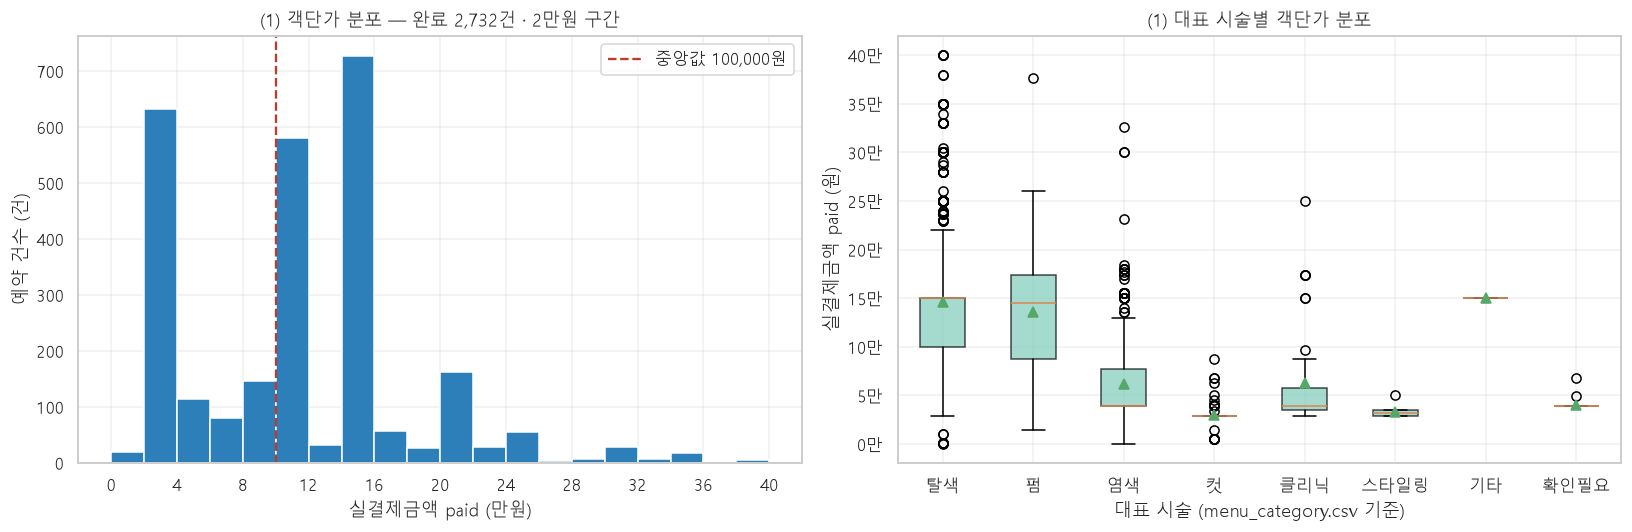

In [12]:
# -- (1) 그래프: 히스토그램 + 시술별 박스플롯 --
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(DONE.paid, bins=_edges, color="#2c7fb8", edgecolor="white")
axes[0].set_title(f"(1) 객단가 분포 — 완료 {len(DONE):,}건 · 2만원 구간")
axes[0].set_xlabel("실결제금액 paid (만원)")
axes[0].set_ylabel("예약 건수 (건)")
_ticks = np.arange(0, DONE.paid.max() + BIN_W, 40_000)
axes[0].set_xticks(_ticks)
axes[0].set_xticklabels([f"{int(x/10000)}" for x in _ticks])
axes[0].axvline(DONE.paid.median(), color="#c0392b", ls="--", lw=1.5,
                label=f"중앙값 {DONE.paid.median():,.0f}원")
axes[0].legend()

_order = [c for c in PRIORITY if c in set(DONE.rep_cat.dropna())]
_data  = [DONE.loc[DONE.rep_cat == c, "paid"].values for c in _order]
bp = axes[1].boxplot(_data, tick_labels=_order, showmeans=True, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#7fcdbb"); patch.set_alpha(.7)
axes[1].set_title("(1) 대표 시술별 객단가 분포")
axes[1].set_xlabel("대표 시술 (menu_category.csv 기준)")
axes[1].set_ylabel("실결제금액 paid (원)")
axes[1].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
plt.tight_layout(); plt.show()

---
# ② 취소와 리드타임

**무엇을 봤나** — 예약을 얼마나 미리 잡았는지(리드타임)가 취소를 얼마나 설명하는지,
취소가 진짜 이탈인지, 언제 취소를 넣는지, 심야에 넣은 예약은 다른지.

* 리드타임 `lead_h = (use_dt − req_dt) / 1시간`. `reservations` 에 이미 계산돼 있다.
* 구간: `<6h / 6~24h / 1~3일 / 3~7일 / 1~2주 / 2주+`
  경계는 **왼쪽 닫힘·오른쪽 열림**(`[6,24)` 식). 데이터에 음수 리드타임은 0건.
* 취소 = `status == "취소"`. `노쇼` 1건, `확정` 6건은 취소로 세지 않는다.

In [13]:
# -- (2)-1 리드타임 구간별 취소율 --
LEAD_EDGES  = [-np.inf, 6, 24, 72, 168, 336, np.inf]
LEAD_LABELS = ["6시간 미만", "6~24시간", "1~3일", "3~7일", "1~2주", "2주 이상"]
R["lead_bin"]    = pd.cut(R.lead_h,    bins=LEAD_EDGES, labels=LEAD_LABELS, right=False)
DONE["lead_bin"] = pd.cut(DONE.lead_h, bins=LEAD_EDGES, labels=LEAD_LABELS, right=False)
CANC["lead_bin"] = pd.cut(CANC.lead_h, bins=LEAD_EDGES, labels=LEAD_LABELS, right=False)

_lb = (R.groupby("lead_bin", observed=False)
         .agg(예약건수=("예약번호", "size"),
              취소건수=("status", lambda s: int((s == "취소").sum())),
              완료건수=("status", lambda s: int((s == "이용완료").sum()))))
_lb["취소율(%)"]   = _lb.취소건수 / _lb.예약건수 * 100
_lb["예약비중(%)"] = _lb.예약건수 / len(R) * 100
_lb["완료객단가중앙값"] = DONE.groupby("lead_bin", observed=False).paid.median()
tbl(_lb.round(2), "(2)-1 리드타임 구간별 취소율 — 전체 예약 기준")

_surface = (R.status == "취소").mean()
print(f"표면 취소율 = 취소 {int((R.status=='취소').sum()):,} / 전체 {len(R):,} = {_surface*100:.2f}%")
rec("전체 예약 건수", f"{len(R):,}건",    "reservations 전체 행")
rec("완료 건수",      f"{len(DONE):,}건", "reservations status==이용완료")
rec("취소 건수",      f"{len(CANC):,}건", "reservations status==취소")
rec("표면 취소율",    pct(_surface),      "취소 건수 / 전체 예약 건수")
for lab in LEAD_LABELS:
    rec(f"리드타임 취소율 · {lab}", f"{_lb.loc[lab, '취소율(%)']:.2f}%",
        f"전체 예약 중 lead_h [{lab}] 구간의 취소/예약")

**(2)-1 리드타임 구간별 취소율 — 전체 예약 기준**

,예약건수,취소건수,완료건수,취소율(%),예약비중(%),완료객단가중앙값
lead_bin,,,,,,
6시간 미만,901,134,766,14.87,21.05,87000.0
6~24시간,889,242,646,27.22,20.77,100000.0
1~3일,939,339,597,36.10,21.93,100000.0
3~7일,751,335,415,44.61,17.54,145000.0
1~2주,464,258,205,55.60,10.84,100000.0
2주 이상,337,234,103,69.44,7.87,150000.0


표면 취소율 = 취소 1,542 / 전체 4,281 = 36.02%


In [14]:
# -- (2)-2 취소 후 실제 방문 (+-45일) --
# 정의: 취소된 예약의 cust_key 가, 그 취소 예약의 use_dt 로부터 +-45일 이내에
#       이용완료 예약을 하나라도 갖고 있으면 실제 방문으로 본다.
WINDOW_D = 45
_done_by_cust = {k: np.sort(v.values) for k, v in DONE.groupby("cust_key")["use_dt"]}

def _revisited(cust_key, use_dt):
    arr = _done_by_cust.get(cust_key)
    if arr is None:
        return False
    lo = np.datetime64(use_dt - pd.Timedelta(days=WINDOW_D))
    hi = np.datetime64(use_dt + pd.Timedelta(days=WINDOW_D))
    return np.searchsorted(arr, hi, side="right") > np.searchsorted(arr, lo, side="left")

CANC["revisit_45d"] = [_revisited(k, d) for k, d in zip(CANC.cust_key, CANC.use_dt)]
_rv  = CANC.revisit_45d.mean()
_net = (~CANC.revisit_45d).sum() / len(R)

_t = pd.DataFrame({
    "구분": ["취소 후 +-45일 내 완료 방문 있음", "없음 (순이탈)"],
    "건수": [int(CANC.revisit_45d.sum()), int((~CANC.revisit_45d).sum())],
})
_t["취소 대비 비중(%)"] = _t.건수 / len(CANC) * 100
_t["전체 예약 대비(%)"] = _t.건수 / len(R) * 100
tbl(_t.round(2), f"(2)-2 취소 {len(CANC):,}건의 사후 방문 여부 — +-{WINDOW_D}일 창")
print(f"취소 후 45일 내 방문 비율 = {_rv*100:.2f}%")
print(f"순이탈률 = 취소 & 45일 내 미방문 {int((~CANC.revisit_45d).sum()):,}건 / 전체 예약 {len(R):,}건 "
      f"= {_net*100:.2f}%")
rec("취소 후 45일 내 방문 비율", pct(_rv),  "취소건 중 동일 cust_key 가 +-45일 내 이용완료 보유")
rec("순이탈률",                 pct(_net), "취소 & +-45일 내 완료 없음 / 전체 예약")

_lb2 = (CANC.groupby("lead_bin", observed=False)
            .agg(취소건수=("예약번호", "size"), 재방문건수=("revisit_45d", "sum")))
_lb2["45일내 방문율(%)"] = _lb2.재방문건수 / _lb2.취소건수 * 100
tbl(_lb2.round(2), "(2)-2b 리드타임 구간별 — 취소 후 45일 내 방문율")

**(2)-2 취소 1,542건의 사후 방문 여부 — +-45일 창**

,구분,건수,취소 대비 비중(%),전체 예약 대비(%)
0,취소 후 +-45일 내 완료 방문 있음,1047,67.9,24.46
1,없음 (순이탈),495,32.1,11.56


취소 후 45일 내 방문 비율 = 67.90%
순이탈률 = 취소 & 45일 내 미방문 495건 / 전체 예약 4,281건 = 11.56%


**(2)-2b 리드타임 구간별 — 취소 후 45일 내 방문율**

,취소건수,재방문건수,45일내 방문율(%)
lead_bin,,,
6시간 미만,134,96,71.64
6~24시간,242,156,64.46
1~3일,339,237,69.91
3~7일,335,241,71.94
1~2주,258,179,69.38
2주 이상,234,138,58.97


In [15]:
# -- (2)-3 취소사유 분류 --
# 공백 제거 후 아래 순서로 첫 매칭. 사유 미기재는 별도 행으로 뺀다.
def _cancel_reason(s):
    if not isinstance(s, str) or not s.strip():
        return "(사유 미기재)"
    t = re.sub(r"\s+", "", s)
    if re.search(r"(날짜|일정|요일)(변경|변동|수정|바꿈)", t):
        return "날짜변경"
    if re.search(r"시간(변경|변동|수정|바꿈)", t):
        return "시간변경"
    if re.search(r"(재예약|다시예약|예약변경|예약을다시)", t):
        return "다시예약"
    return "기타"

CANC["cancel_reason"] = CANC.취소사유.map(_cancel_reason)
_order_cr = ["날짜변경", "시간변경", "다시예약", "기타", "(사유 미기재)"]
_cr = (CANC.cancel_reason.value_counts().reindex(_order_cr)
           .fillna(0).astype(int).rename("건수").to_frame())
_cr["비중(%)"] = _cr.건수 / len(CANC) * 100
_cr["45일내 방문율(%)"] = CANC.groupby("cancel_reason").revisit_45d.mean().reindex(_order_cr) * 100
tbl(_cr.round(2), f"(2)-3 취소사유 분류 — 취소 {len(CANC):,}건")
print("주의: 기타에는 매장 안내문 정형 텍스트(안녕하세요~ 계열)와 무의미 입력(., ㅇ 등)이 섞여 있다.")
for k in _order_cr:
    rec(f"취소사유 · {k}", f"{int(_cr.loc[k, '건수']):,}건 ({_cr.loc[k, '비중(%)']:.2f}%)",
        "취소건 취소사유 텍스트 정규식 분류")

**(2)-3 취소사유 분류 — 취소 1,542건**

,건수,비중(%),45일내 방문율(%)
cancel_reason,,,
날짜변경,282,18.29,71.99
시간변경,186,12.06,85.48
다시예약,86,5.58,79.07
기타,326,21.14,59.51
(사유 미기재),662,42.93,63.90


주의: 기타에는 매장 안내문 정형 텍스트(안녕하세요~ 계열)와 무의미 입력(., ㅇ 등)이 섞여 있다.


In [16]:
# -- (2)-4 취소 시점 대비 방문 예정 시각 --
_c = CANC.dropna(subset=["cancel_dt"]).copy()
_c["gap_h"] = (_c.use_dt - _c.cancel_dt).dt.total_seconds() / 3600

def _gap_bin(g):
    if g < 0:
        return "방문 시각이 지난 뒤"
    if g <= 2:
        return "2시간 이내"
    if g <= 6:
        return "2~6시간 전"
    return "6시간 이상 전"

_c["gap_bin"] = _c.gap_h.map(_gap_bin)
GAP_ORDER = ["방문 시각이 지난 뒤", "2시간 이내", "2~6시간 전", "6시간 이상 전"]
_gb = _c.gap_bin.value_counts().reindex(GAP_ORDER).fillna(0).astype(int).rename("건수").to_frame()
_gb["비중(%)"] = _gb.건수 / len(_c) * 100
tbl(_gb.round(2), f"(2)-4 취소 시점에서 방문 예정 시각까지 남은 시간 — cancel_dt 있는 {len(_c):,}건")

_irr = int(_gb.loc[["방문 시각이 지난 뒤", "2시간 이내"], "건수"].sum())
_months = (R.ym.max() - R.ym.min()).n + 1
print(f"자리 회복이 사실상 불가능한 취소(지난 뒤 + 2시간 이내) = {_irr:,}건, "
      f"{_months}개월 기준 월 {_irr/_months:.1f}건")
rec("자리회복 불가 취소(지난뒤+2h이내)", f"{_irr:,}건",
    "취소건 중 use_dt - cancel_dt <= 2시간")

**(2)-4 취소 시점에서 방문 예정 시각까지 남은 시간 — cancel_dt 있는 1,542건**

,건수,비중(%)
gap_bin,,
방문 시각이 지난 뒤,133,8.63
2시간 이내,182,11.80
2~6시간 전,123,7.98
6시간 이상 전,1104,71.60


자리 회복이 사실상 불가능한 취소(지난 뒤 + 2시간 이내) = 315건, 20개월 기준 월 15.8건


'315건'

In [17]:
# -- (2)-5 예약을 넣은 시각(req_h)별 취소율/객단가 --
def _reqbin(h):
    if h <= 5:  return "0~5시(심야)"
    if h <= 9:  return "6~9시"
    if h <= 13: return "10~13시"
    if h <= 17: return "14~17시"
    if h <= 21: return "18~21시"
    return "22~23시"

R["req_bin"]    = R.req_h.map(_reqbin)
DONE["req_bin"] = DONE.req_h.map(_reqbin)
REQ_ORDER = ["0~5시(심야)", "6~9시", "10~13시", "14~17시", "18~21시", "22~23시"]

_rb = (R.groupby("req_bin")
         .agg(예약건수=("예약번호", "size"),
              취소건수=("status", lambda s: int((s == "취소").sum())))
         .reindex(REQ_ORDER))
_rb["취소율(%)"]           = _rb.취소건수 / _rb.예약건수 * 100
_rb["완료 객단가 중앙값"]  = DONE.groupby("req_bin").paid.median().reindex(REQ_ORDER)
_rb["완료 객단가 평균"]    = DONE.groupby("req_bin").paid.mean().reindex(REQ_ORDER)
tbl(_rb.round(1), "(2)-5 예약 신청 시각대별 취소율 · 객단가")

_night = R.req_h <= 5
_cmp2 = pd.DataFrame({
    "구분": ["0~5시 신청", "그 외 시간 신청"],
    "예약건수": [int(_night.sum()), int((~_night).sum())],
    "취소율(%)": [(R[_night].status == "취소").mean() * 100,
                  (R[~_night].status == "취소").mean() * 100],
    "완료 객단가 중앙값": [DONE[DONE.req_h <= 5].paid.median(), DONE[DONE.req_h > 5].paid.median()],
    "완료 객단가 평균":   [DONE[DONE.req_h <= 5].paid.mean(),   DONE[DONE.req_h > 5].paid.mean()],
})
tbl(_cmp2.round(1), "(2)-5b 심야(0~5시) 신청 vs 나머지")
rec("심야(0~5시) 신청 예약 건수", f"{int(_night.sum()):,}건", "reservations req_h <= 5")
rec("심야(0~5시) 신청 취소율", pct((R[_night].status == "취소").mean()), "req_h<=5 예약의 취소/전체")
rec("심야(0~5시) 신청 완료 객단가 평균", won(DONE[DONE.req_h <= 5].paid.mean()) + "원",
    "완료 & req_h<=5 의 paid 평균")

**(2)-5 예약 신청 시각대별 취소율 · 객단가**

,예약건수,취소건수,취소율(%),완료 객단가 중앙값,완료 객단가 평균
req_bin,,,,,
0~5시(심야),534,244,45.7,150000.0,130138.4
6~9시,327,119,36.4,100000.0,103290.6
10~13시,1037,324,31.2,100000.0,103379.9
14~17시,1100,356,32.4,100000.0,109996.6
18~21시,876,330,37.7,100000.0,122023.0
22~23시,407,169,41.5,100000.0,119333.3


**(2)-5b 심야(0~5시) 신청 vs 나머지**

,구분,예약건수,취소율(%),완료 객단가 중앙값,완료 객단가 평균
0,0~5시 신청,534,45.7,150000.0,130138.4
1,그 외 시간 신청,3747,34.6,100000.0,111078.9


'130,138원'

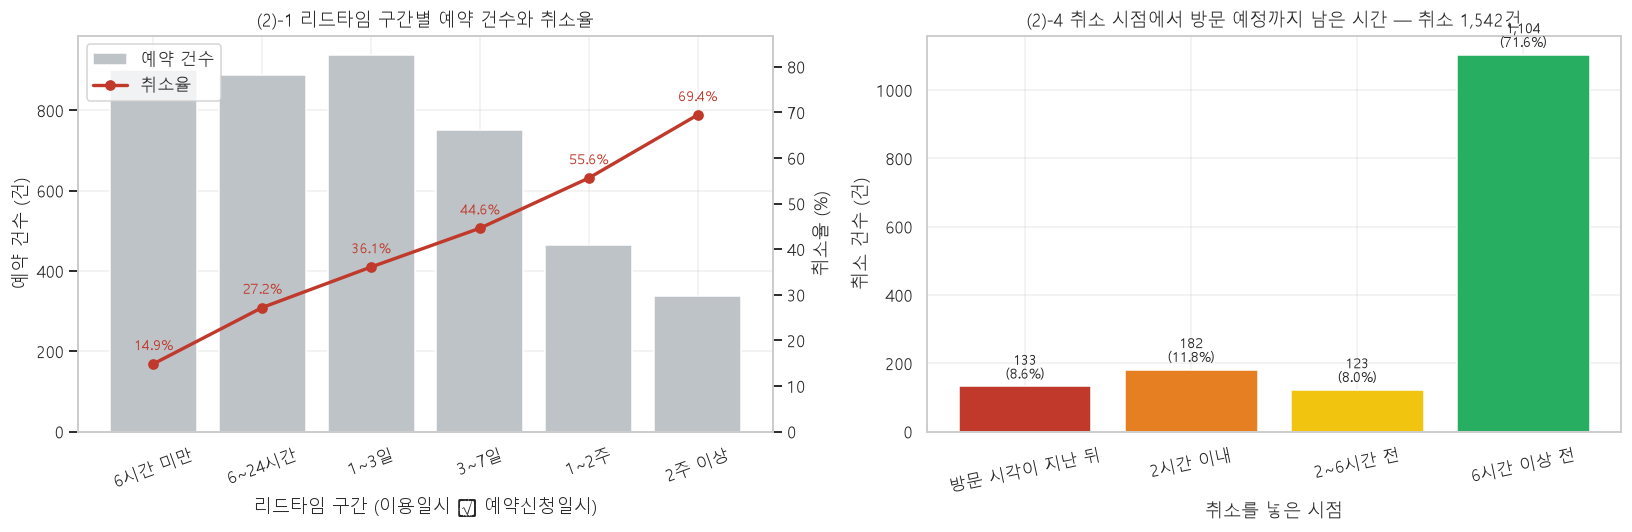

In [18]:
# -- (2) 그래프: 리드타임 이중축 + 취소 시점 분포 --
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
ax.bar(range(len(_lb)), _lb.예약건수, color="#bdc3c7", label="예약 건수")
ax.set_ylabel("예약 건수 (건)")
ax.set_xlabel("리드타임 구간 (이용일시 − 예약신청일시)")
ax.set_xticks(range(len(_lb)))
ax.set_xticklabels(list(_lb.index), rotation=20)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(range(len(_lb)), _lb["취소율(%)"], color="#c0392b", marker="o", lw=2.2, label="취소율")
for i, v in enumerate(_lb["취소율(%)"]):
    ax2.annotate(f"{v:.1f}%", (i, v), textcoords="offset points", xytext=(0, 9),
                 ha="center", color="#c0392b", fontsize=9)
ax2.set_ylabel("취소율 (%)")
ax2.set_ylim(0, float(_lb["취소율(%)"].max()) * 1.25)
ax.set_title("(2)-1 리드타임 구간별 예약 건수와 취소율")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

axes[1].bar(list(_gb.index), _gb.건수, color=["#c0392b", "#e67e22", "#f1c40f", "#27ae60"])
for i, v in enumerate(_gb.건수):
    axes[1].annotate(f"{v:,}\n({_gb['비중(%)'].iloc[i]:.1f}%)", (i, v),
                     textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9)
axes[1].set_title(f"(2)-4 취소 시점에서 방문 예정까지 남은 시간 — 취소 {len(_c):,}건")
axes[1].set_xlabel("취소를 넣은 시점")
axes[1].set_ylabel("취소 건수 (건)")
axes[1].tick_params(axis="x", rotation=12)
plt.tight_layout(); plt.show()

---
# ③ 요일 × 시간

**무엇을 봤나** — 완료 건이 요일·시간에 어떻게 깔려 있는지, 시간대마다 시술 믹스가 바뀌는지,
시간대별 객단가 분포가 다른지.

**정의**
* 전부 `use_dt`(이용일시) 기준. `done_dt` 는 쓰지 않는다.
* 교차표는 프롬프트대로 **10~19시**만. `use_dt` 의 시(hour) 분포는 10~20시이고 20시는 3건뿐이라
  교차표 밖으로 빠진다(아래 셀에서 건수 확인).
* **시술 구성비는 메뉴 라인 단위**(사용자 확인). 한 예약에 탈색+염색이 있으면 둘 다 센다.
* **"금액 0원인 무료 클리닉" 제외** = `category == "클리닉" and line_price == 0` 인 라인을 뺀 뒤
  남은 라인으로 100%를 다시 맞춘다(재정규화).
* 시간대 버킷: `10~12` = hour 10,11,12 / `13~15` = 13,14,15 / `16~18` = 16,17,18 / `19~20` = 19,20

In [19]:
# -- (3)-1 요일 x 시간 교차표 (완료 건) --
HOURS = list(range(10, 20))
_ct = (DONE[DONE.hour.isin(HOURS)]
       .pivot_table(index="dow_ko", columns="hour", values="예약번호",
                    aggfunc="size", fill_value=0)
       .reindex(index=DOW_KO, columns=HOURS, fill_value=0))
_ct["합계"] = _ct.sum(axis=1)
_ct.loc["합계"] = _ct.sum(axis=0)
tbl(_ct, "(3)-1 요일 x 시(10~19) 완료 건수 교차표 — use_dt 기준")
print(f"완료 {len(DONE):,}건 중 hour 10~19 에 든 건수 {int(DONE.hour.isin(HOURS).sum()):,}건, "
      f"밖 {int((~DONE.hour.isin(HOURS)).sum()):,}건 "
      f"(hour 분포: {DONE.hour.value_counts().sort_index().to_dict()})")

**(3)-1 요일 x 시(10~19) 완료 건수 교차표 — use_dt 기준**

hour,10,11,12,13,14,15,16,17,18,19,합계
dow_ko,,,,,,,,,,,
월,35,61,62,55,50,42,26,38,29,18,416
화,33,55,45,37,39,32,16,25,24,14,320
수,32,53,40,40,43,47,28,29,24,13,349
목,44,58,53,49,68,35,30,29,27,11,404
금,57,84,85,70,45,55,31,39,46,20,532
토,46,63,61,51,46,39,30,21,20,5,382
일,48,47,42,35,34,45,30,17,23,5,326
합계,295,421,388,337,325,295,191,198,193,86,2729


완료 2,732건 중 hour 10~19 에 든 건수 2,729건, 밖 3건 (hour 분포: {10: 295, 11: 421, 12: 388, 13: 337, 14: 325, 15: 295, 16: 191, 17: 198, 18: 193, 19: 86, 20: 3})


In [20]:
# -- (3)-2 시간대별 시술 구성비 (라인 기준, 무료 클리닉 제외 후 재정규화) --
def _slot(h):
    if 10 <= h <= 12: return "10~12시"
    if 13 <= h <= 15: return "13~15시"
    if 16 <= h <= 18: return "16~18시"
    if 19 <= h <= 20: return "19~20시"
    return "기타"

SLOT_ORDER = ["10~12시", "13~15시", "16~18시", "19~20시"]
LX["slot"]   = LX.hour.map(_slot)
DONE["slot"] = DONE.hour.map(_slot)

_ldone = LX[LX.status == "이용완료"].copy()
_free_mask = (_ldone.category == "클리닉") & (_ldone.line_price == 0)
print(f"완료 예약의 시술 라인 {len(_ldone):,}개 중 "
      f"금액 0원 무료 클리닉 {int(_free_mask.sum()):,}개 제외 -> {int((~_free_mask).sum()):,}개로 구성비 계산")
_lmix = _ldone[~_free_mask]

_mix = (pd.crosstab(_lmix.slot, _lmix.category)
          .reindex(index=SLOT_ORDER)
          .fillna(0).astype(int))
_mix = _mix[[c for c in PRIORITY if c in _mix.columns]]
_mixpct = _mix.div(_mix.sum(axis=1), axis=0) * 100
_mixpct["라인수"] = _mix.sum(axis=1)
tbl(_mix, "(3)-2a 시간대 x 시술 라인 수 (무료 클리닉 제외)")
tbl(_mixpct.round(2), "(3)-2b 시간대별 시술 구성비 (%) — 라인 기준, 재정규화")
for s in SLOT_ORDER:
    for c in ["탈색", "염색"]:
        if c in _mixpct.columns:
            rec(f"시술 구성비 · {s} · {c}", f"{_mixpct.loc[s, c]:.2f}%",
                "완료 예약의 메뉴 라인 중 무료클리닉 제외 후 시간대 내 비중")

완료 예약의 시술 라인 4,531개 중 금액 0원 무료 클리닉 1,621개 제외 -> 2,910개로 구성비 계산


**(3)-2a 시간대 x 시술 라인 수 (무료 클리닉 제외)**

category,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요
slot,,,,,,,,
10~12시,776,76,193,109,5,6,1,9
13~15시,595,65,204,120,10,7,0,13
16~18시,229,34,232,92,6,11,0,26
19~20시,24,3,39,15,0,6,0,4


**(3)-2b 시간대별 시술 구성비 (%) — 라인 기준, 재정규화**

category,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,라인수
slot,,,,,,,,,
10~12시,66.04,6.47,16.43,9.28,0.43,0.51,0.09,0.77,1175
13~15시,58.68,6.41,20.12,11.83,0.99,0.69,0.00,1.28,1014
16~18시,36.35,5.40,36.83,14.60,0.95,1.75,0.00,4.13,630
19~20시,26.37,3.30,42.86,16.48,0.00,6.59,0.00,4.40,91


In [21]:
# -- (3)-3 시간대별 paid 분위수 --
_q = (DONE[DONE.slot != "기타"].groupby("slot").paid
        .describe(percentiles=[.05, .25, .5, .75, .95])
        .reindex(SLOT_ORDER)[["count", "5%", "25%", "50%", "75%", "95%", "mean"]])
_q.columns = ["완료건수", "5분위", "25분위", "중앙값", "75분위", "95분위", "평균"]
tbl(_q.round(0), "(3)-3 시간대별 완료 객단가 분위수 (원)")

**(3)-3 시간대별 완료 객단가 분위수 (원)**

,완료건수,5분위,25분위,중앙값,75분위,95분위,평균
slot,,,,,,,
10~12시,1104.0,29000.0,88000.0,145000.0,150000.0,250000.0,126693.0
13~15시,957.0,29000.0,58000.0,100000.0,150000.0,220000.0,114324.0
16~18시,582.0,29000.0,39000.0,87000.0,145000.0,200000.0,91595.0
19~20시,89.0,29000.0,39000.0,39000.0,100000.0,200000.0,71809.0


In [22]:
# -- (3)-4 요일별 예약/완료/취소 --
_dw = (R.groupby("dow_ko")
         .agg(예약=("예약번호", "size"),
              완료=("status", lambda s: int((s == "이용완료").sum())),
              취소=("status", lambda s: int((s == "취소").sum())))
         .reindex(DOW_KO))
_dw["취소율(%)"] = _dw.취소 / _dw.예약 * 100
_dw["완료 객단가 중앙값"] = DONE.groupby("dow_ko").paid.median().reindex(DOW_KO)
tbl(_dw.round(2), "(3)-4 요일별 예약 · 완료 · 취소율 — use_dt 기준")

**(3)-4 요일별 예약 · 완료 · 취소율 — use_dt 기준**

,예약,완료,취소,취소율(%),완료 객단가 중앙값
dow_ko,,,,,
월,661,416,245,37.07,100000.0
화,509,320,189,37.13,100000.0
수,557,350,207,37.16,100000.0
목,609,405,204,33.50,100000.0
금,792,532,260,32.83,100000.0
토,630,383,247,39.21,100000.0
일,523,326,190,36.33,100000.0


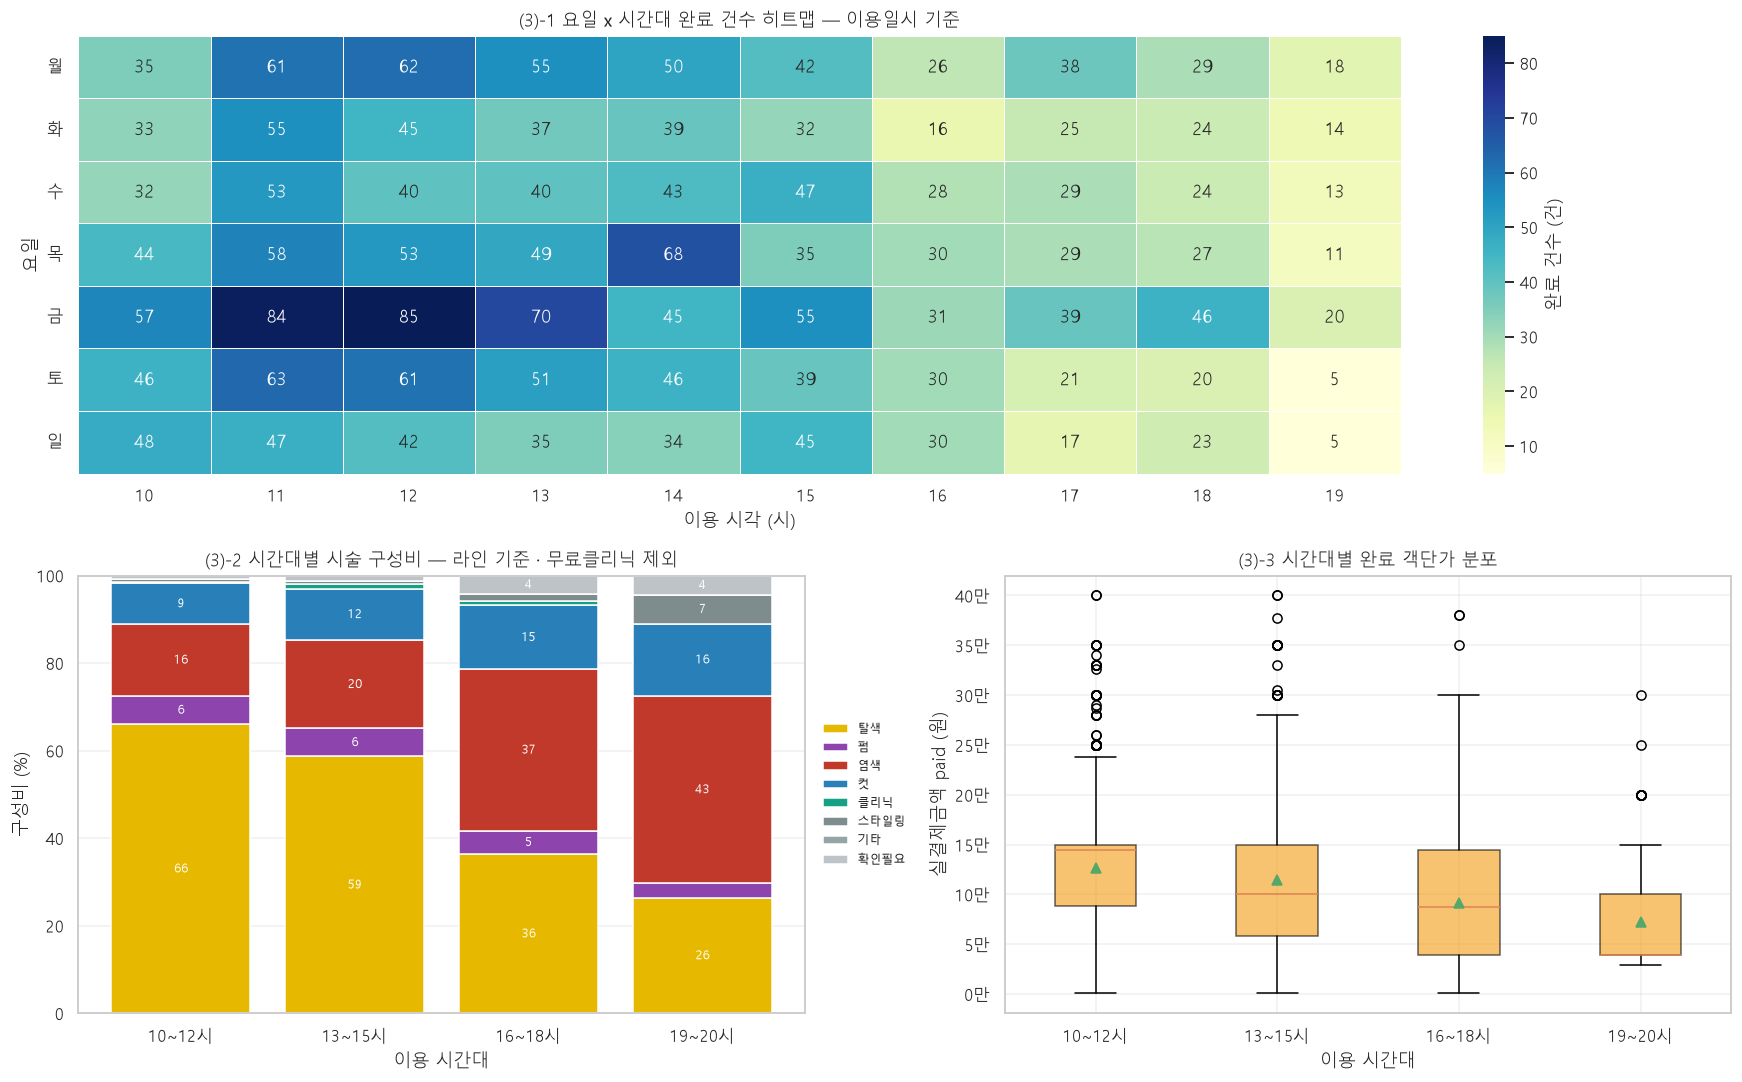

In [23]:
# -- (3) 그래프: 히트맵 / 100% 누적막대 / 박스플롯 --
fig = plt.figure(figsize=(16, 10))

ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)
_hm = _ct.drop(index="합계", columns="합계")
sns.heatmap(_hm, annot=True, fmt="d", cmap="YlGnBu", ax=ax1,
            cbar_kws={"label": "완료 건수 (건)"}, linewidths=.5, linecolor="white")
ax1.set_title("(3)-1 요일 x 시간대 완료 건수 히트맵 — 이용일시 기준")
ax1.set_xlabel("이용 시각 (시)"); ax1.set_ylabel("요일")
ax1.set_yticklabels(ax1.get_yticklabels(), rotation=0)

ax2 = plt.subplot2grid((2, 2), (1, 0))
_stack = _mixpct.drop(columns="라인수")
_bottom = np.zeros(len(_stack))
_colors = {"탈색": "#e6b800", "펌": "#8e44ad", "염색": "#c0392b",
           "컷": "#2980b9", "클리닉": "#16a085", "스타일링": "#7f8c8d",
           "기타": "#95a5a6", "확인필요": "#bdc3c7"}
for c in _stack.columns:
    ax2.bar(_stack.index, _stack[c], bottom=_bottom, label=c, color=_colors.get(c, None))
    for i, v in enumerate(_stack[c]):
        if v >= 4:
            ax2.text(i, _bottom[i] + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white")
    _bottom += _stack[c].values
ax2.set_title("(3)-2 시간대별 시술 구성비 — 라인 기준 · 무료클리닉 제외")
ax2.set_xlabel("이용 시간대"); ax2.set_ylabel("구성비 (%)"); ax2.set_ylim(0, 100)
ax2.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)

ax3 = plt.subplot2grid((2, 2), (1, 1))
_bdata = [DONE.loc[DONE.slot == s, "paid"].values for s in SLOT_ORDER]
bp = ax3.boxplot(_bdata, tick_labels=SLOT_ORDER, showmeans=True, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#f39c12"); patch.set_alpha(.6)
ax3.set_title("(3)-3 시간대별 완료 객단가 분포")
ax3.set_xlabel("이용 시간대"); ax3.set_ylabel("실결제금액 paid (원)")
ax3.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))

plt.tight_layout(); plt.show()

---
# ④ 시술 전이

**무엇을 봤나** — 한 고객이 다음에 뭘 하러 오는지. 탈색 손님이 염색으로 넘어가는가.

**정의**
* 모집단: **이용완료** 건만. 대표시술(`rep_cat`)이 있는 건만.
* `cust_key` 별로 `use_dt` 오름차순 정렬 후 **인접한 방문 쌍**을 전부 센다.
  (방문 3회면 쌍 2개. 첫 방문 → 마지막 방문 같은 건너뛴 쌍은 세지 않는다.)
* 2회 이상 방문한 고객만 자연히 포함된다(1회 방문자는 쌍이 안 생김).
* 행 = 직전 시술, 열 = 다음 시술. 비율은 **행 기준**(직전 시술이 A일 때 다음이 B일 확률).

In [24]:
# -- (4) 전이 쌍 생성 --
_v = (DONE.dropna(subset=["rep_cat"])
          .sort_values(["cust_key", "use_dt"])
          [["cust_key", "use_dt", "rep_cat", "designer", "paid"]]
          .reset_index(drop=True))
_v["prev_cat"]      = _v.groupby("cust_key").rep_cat.shift(1)
_v["prev_designer"] = _v.groupby("cust_key").designer.shift(1)
_v["prev_dt"]       = _v.groupby("cust_key").use_dt.shift(1)
PAIRS = _v.dropna(subset=["prev_cat"]).copy()

print(f"완료 건 {len(DONE):,} 중 대표시술 보유 {len(_v):,}건")
print(f"전이 쌍 {len(PAIRS):,}개 · 이 쌍에 기여한 고객 {PAIRS.cust_key.nunique():,}명 "
      f"(= 대표시술 보유 완료 방문이 2회 이상인 고객)")
rec("전이 쌍 개수", f"{len(PAIRS):,}쌍", "완료 건 cust_key별 use_dt 인접 쌍 (rep_cat 보유)")

_cats = [c for c in PRIORITY if c in set(PAIRS.prev_cat) | set(PAIRS.rep_cat)]
_M = (pd.crosstab(PAIRS.prev_cat, PAIRS.rep_cat)
        .reindex(index=_cats, columns=_cats).fillna(0).astype(int))
_M["합계"] = _M.sum(axis=1)
tbl(_M, "(4)-1 시술 전이 행렬 — 건수 (행: 직전 시술, 열: 다음 시술)")

_Mp = _M.drop(columns="합계")
_Mp = _Mp.div(_Mp.sum(axis=1), axis=0) * 100
tbl(_Mp.round(2), "(4)-2 시술 전이 행렬 — 행 기준 비율 (%)")

_rep_rate = pd.DataFrame({
    "전이 쌍 수": _M["합계"],
    "같은 시술 반복(건)": [int(_M.loc[c, c]) for c in _cats],
})
_rep_rate["같은 시술 반복률(%)"] = _rep_rate["같은 시술 반복(건)"] / _rep_rate["전이 쌍 수"] * 100
_rep_rate["다른 시술로 이동(%)"] = 100 - _rep_rate["같은 시술 반복률(%)"]
tbl(_rep_rate.round(2), "(4)-3 시술별 반복 vs 이동")
for c in _cats:
    rec(f"시술 반복률 · {c}->{c}", f"{_rep_rate.loc[c, '같은 시술 반복률(%)']:.2f}%",
        "완료 인접 방문쌍 행 기준 비율")
if "탈색" in _Mp.index and "염색" in _Mp.columns:
    rec("탈색 -> 염색 전이율", f"{_Mp.loc['탈색', '염색']:.2f}%", "완료 인접 방문쌍 행 기준 비율")

완료 건 2,732 중 대표시술 보유 2,732건
전이 쌍 1,175개 · 이 쌍에 기여한 고객 411명 (= 대표시술 보유 완료 방문이 2회 이상인 고객)


**(4)-1 시술 전이 행렬 — 건수 (행: 직전 시술, 열: 다음 시술)**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,확인필요,합계
prev_cat,,,,,,,,
탈색,403,5,40,2,1,0,0,451
펌,2,38,38,10,0,0,1,89
염색,10,37,392,17,11,0,3,470
컷,1,17,15,93,0,0,0,126
클리닉,1,0,8,2,6,0,1,18
스타일링,0,0,0,0,1,1,0,2
확인필요,0,1,5,2,2,0,9,19


**(4)-2 시술 전이 행렬 — 행 기준 비율 (%)**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,확인필요
prev_cat,,,,,,,
탈색,89.36,1.11,8.87,0.44,0.22,0.0,0.00
펌,2.25,42.70,42.70,11.24,0.00,0.0,1.12
염색,2.13,7.87,83.40,3.62,2.34,0.0,0.64
컷,0.79,13.49,11.90,73.81,0.00,0.0,0.00
클리닉,5.56,0.00,44.44,11.11,33.33,0.0,5.56
스타일링,0.00,0.00,0.00,0.00,50.00,50.0,0.00
확인필요,0.00,5.26,26.32,10.53,10.53,0.0,47.37


**(4)-3 시술별 반복 vs 이동**

,전이 쌍 수,같은 시술 반복(건),같은 시술 반복률(%),다른 시술로 이동(%)
prev_cat,,,,
탈색,451,403,89.36,10.64
펌,89,38,42.70,57.30
염색,470,392,83.40,16.60
컷,126,93,73.81,26.19
클리닉,18,6,33.33,66.67
스타일링,2,1,50.00,50.00
확인필요,19,9,47.37,52.63


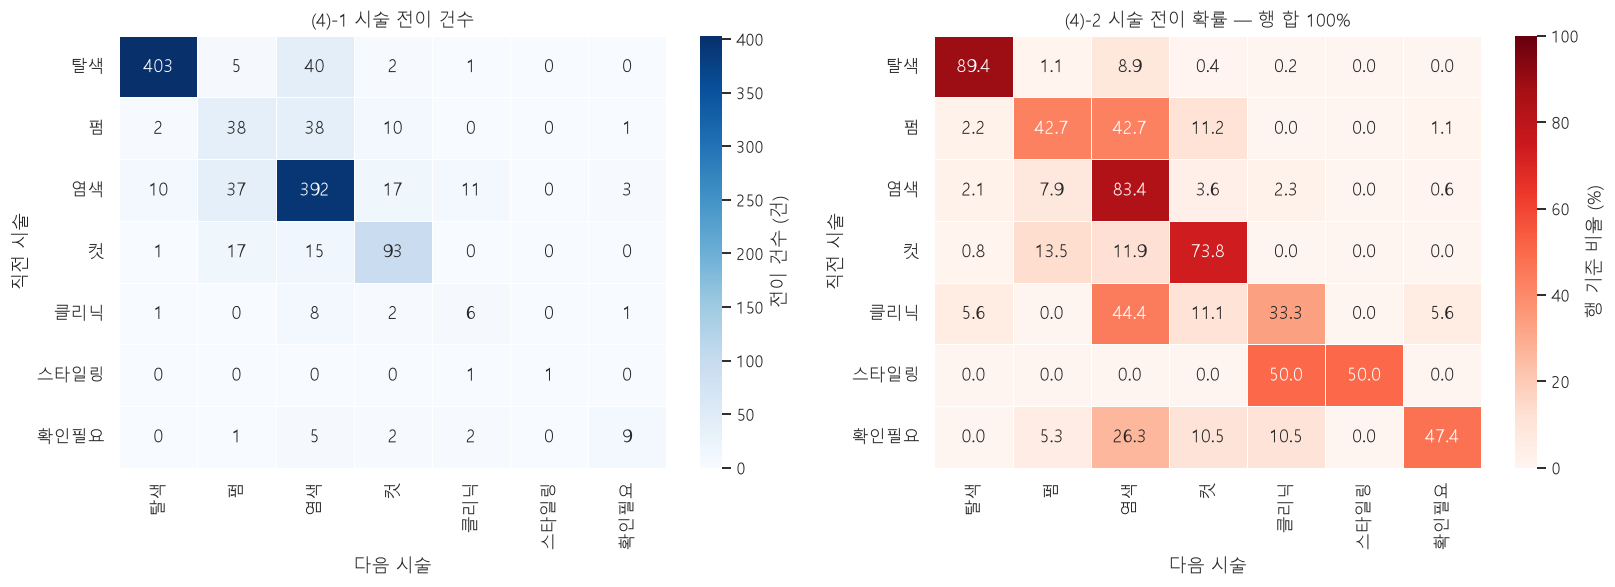

In [25]:
# -- (4) 그래프: 전이 행렬 히트맵 --
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(_M.drop(columns="합계"), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            linewidths=.5, linecolor="white", cbar_kws={"label": "전이 건수 (건)"})
axes[0].set_title("(4)-1 시술 전이 건수")
axes[0].set_xlabel("다음 시술"); axes[0].set_ylabel("직전 시술")

sns.heatmap(_Mp, annot=True, fmt=".1f", cmap="Reds", ax=axes[1],
            linewidths=.5, linecolor="white", cbar_kws={"label": "행 기준 비율 (%)"},
            vmin=0, vmax=100)
axes[1].set_title("(4)-2 시술 전이 확률 — 행 합 100%")
axes[1].set_xlabel("다음 시술"); axes[1].set_ylabel("직전 시술")
plt.tight_layout(); plt.show()

---
# ⑤ 첫 방문 특성과 재방문

**무엇을 봤나** — 첫 방문에 얼마를 쓴 손님이 다시 오는가, 어느 요일 첫 방문이 붙는가,
매출이 몇 명에게 몰려 있는가, 첫방문 50% 할인 채널이 취소를 더 내는가.

**정의**
* 고객 = `cust_key`. **이용완료 건만** 사용한다(취소는 방문이 아니다).
* 각 고객의 첫 방문 = 완료 건 중 `use_dt` 가 가장 이른 것.
* 재방문율 = 완료 방문 횟수가 **2회 이상**인 고객 비율.
* 누적 지출 = 그 고객의 완료 건 `paid` 합.
* 파레토는 고객별 누적 지출 내림차순 정렬 후 상위 n% **인원**이 차지하는 매출 비중.
* **"첫방문 50%할인" 은 `channel`(유입경로)이 아니라 `designer` 컬럼 값**이다.
  (`designer == "첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약"`, 413건)
  그래서 designer 문자열로 판정한다.

In [26]:
# -- (5)-0 고객 단위 집계 --
# groupby.agg 의 "first" 는 결측을 건너뛴다. rep_cat 이 NaN 인 첫 방문이 있으면
# 뒤 방문의 시술을 끌어와 버리므로, 첫 방문 "행" 자체를 명시적으로 뽑는다.
_first_row = (DONE.sort_values("use_dt").drop_duplicates("cust_key", keep="first")
                  .set_index("cust_key")[["use_dt", "paid", "dow_ko", "rep_cat", "designer"]]
                  .rename(columns={"use_dt": "첫방문일", "paid": "첫방문paid",
                                   "dow_ko": "첫방문요일", "rep_cat": "첫방문시술",
                                   "designer": "첫디자이너"}))
_cust_agg = DONE.groupby("cust_key").agg(방문횟수=("예약번호", "size"),
                                         누적지출=("paid", "sum"))
CUST = _first_row.join(_cust_agg)
CUST["재방문"] = CUST.방문횟수 >= 2
print(f"완료 기준 고유 고객 {len(CUST):,}명 / 전체 예약 기준 고유 고객 {R.cust_key.nunique():,}명")
print(f"1회만 방문 {int((CUST.방문횟수 == 1).sum()):,}명 ({(CUST.방문횟수 == 1).mean()*100:.2f}%) · "
      f"2회 이상 {int(CUST.재방문.sum()):,}명 ({CUST.재방문.mean()*100:.2f}%)")
rec("고유 고객 수 (완료 기준)", f"{len(CUST):,}명", "완료 건의 cust_key nunique")
rec("고유 고객 수 (전체 예약 기준)", f"{R.cust_key.nunique():,}명", "reservations 전체 cust_key nunique")
rec("전체 재방문율(2회+)", pct(CUST.재방문.mean()), "완료 기준 고객 중 완료 방문 2회 이상")
rec("전체 평균 방문 횟수", f"{CUST.방문횟수.mean():.4f}회", "완료 기준 고객별 완료 건수 평균")

완료 기준 고유 고객 1,557명 / 전체 예약 기준 고유 고객 1,895명
1회만 방문 1,146명 (73.60%) · 2회 이상 411명 (26.40%)


'1.7547회'

In [27]:
# -- (5)-1 첫 방문 금액대별 재방문 --
PAID_EDGES  = [0, 50_000, 90_000, 120_000, 160_000, np.inf]
PAID_LABELS = ["5만 미만", "5~9만", "9~12만", "12~16만", "16만 이상"]
CUST["첫방문금액대"] = pd.cut(CUST.첫방문paid, bins=PAID_EDGES, labels=PAID_LABELS, right=False)

_fb = (CUST.groupby("첫방문금액대", observed=False)
            .agg(인원=("방문횟수", "size"),
                 재방문율=("재방문", "mean"),
                 평균방문횟수=("방문횟수", "mean"),
                 누적지출평균=("누적지출", "mean"),
                 첫방문paid중앙값=("첫방문paid", "median")))
_fb["재방문율"] = _fb.재방문율 * 100
_fb["인원비중(%)"] = _fb.인원 / len(CUST) * 100
tbl(_fb.round(2), "(5)-1 첫 방문 금액대별 재방문 — 완료 기준 고객")
for lab in PAID_LABELS:
    rec(f"첫방문 금액대 재방문율 · {lab}", f"{_fb.loc[lab, '재방문율']:.2f}%",
        "완료 기준 고객, 첫 완료건 paid 구간별 2회+ 비율")

_fs = (CUST.dropna(subset=["첫방문시술"])
            .groupby("첫방문시술")
            .agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean"),
                 평균방문횟수=("방문횟수", "mean"), 누적지출평균=("누적지출", "mean")))
_fs["재방문율"] = _fs.재방문율 * 100
_fs = _fs.reindex([c for c in PRIORITY if c in _fs.index])
tbl(_fs.round(3), "(5)-1b 첫 시술별 재방문 — 완료 기준 고객")
for c in _fs.index:
    rec(f"첫방문 {c} 고객 평균 방문 횟수", f"{_fs.loc[c, '평균방문횟수']:.4f}회",
        "완료 기준 고객, 첫 완료건 rep_cat별 완료 방문수 평균")
    rec(f"첫방문 {c} 고객 재방문율", f"{_fs.loc[c, '재방문율']:.2f}%",
        "완료 기준 고객, 첫 완료건 rep_cat별 2회+ 비율")

**(5)-1 첫 방문 금액대별 재방문 — 완료 기준 고객**

,인원,재방문율,평균방문횟수,누적지출평균,첫방문paid중앙값,인원비중(%)
첫방문금액대,,,,,,
5만 미만,196,42.35,3.49,157369.90,29000.0,12.59
5~9만,121,32.23,2.50,190389.67,68000.0,7.77
9~12만,373,19.57,1.33,136520.11,100000.0,23.96
12~16만,588,24.83,1.42,206057.82,150000.0,37.76
16만 이상,279,25.09,1.48,297526.88,200000.0,17.92


**(5)-1b 첫 시술별 재방문 — 완료 기준 고객**

,인원,재방문율,평균방문횟수,누적지출평균
첫방문시술,,,,
탈색,1190,22.773,1.389,200951.681
펌,73,39.726,1.932,236376.712
염색,149,46.309,4.047,251705.705
컷,98,31.633,2.367,93790.816
클리닉,20,20.000,2.000,123950.000
스타일링,17,11.765,1.118,36470.588
기타,1,0.000,1.000,150000.000
확인필요,9,55.556,4.778,293666.667


In [28]:
# -- (5)-2 첫 방문 요일별 재방문율 --
_fd = (CUST.groupby("첫방문요일")
            .agg(인원=("방문횟수", "size"), 재방문율=("재방문", "mean"),
                 평균방문횟수=("방문횟수", "mean"))
            .reindex(DOW_KO))
_fd["재방문율"] = _fd.재방문율 * 100
tbl(_fd.round(2), "(5)-2 첫 방문 요일별 재방문율")

**(5)-2 첫 방문 요일별 재방문율**

,인원,재방문율,평균방문횟수
첫방문요일,,,
월,242,34.71,1.96
화,186,24.73,1.82
수,205,18.54,1.40
목,239,25.52,1.63
금,296,31.08,1.87
토,217,20.74,1.53
일,172,26.16,2.07


In [29]:
# -- (5)-3 고객 누적 매출 파레토 --
_sorted = CUST.누적지출.sort_values(ascending=False).values
_cum    = _sorted.cumsum() / _sorted.sum()
_n      = len(_sorted)
_par = []
for p in [0.05, 0.10, 0.20, 0.50]:
    k = int(np.ceil(_n * p))
    _par.append({"상위 인원 비율": f"{int(p*100)}%", "인원": k,
                 "매출 비중(%)": _cum[k-1] * 100,
                 "누적 매출(원)": _sorted[:k].sum()})
_par = pd.DataFrame(_par)
tbl(_par.round(2), f"(5)-3 고객 누적 매출 파레토 — 완료 기준 고객 {_n:,}명 · 총 {_sorted.sum():,}원")
for _, row in _par.iterrows():
    rec(f"상위 {row['상위 인원 비율']} 고객 매출 비중", f"{row['매출 비중(%)']:.2f}%",
        "완료 기준 고객별 paid 합 내림차순 누적")

**(5)-3 고객 누적 매출 파레토 — 완료 기준 고객 1,557명 · 총 308,975,650원**

,상위 인원 비율,인원,매출 비중(%),누적 매출(원)
0,5%,78,19.86,61376650
1,10%,156,30.52,94314150
2,20%,312,46.41,143383150
3,50%,779,74.33,229653150


In [30]:
# -- (5)-4 첫방문 50%할인 채널의 취소율 --
FIRST50 = "첫방문 50%할인"
R["is_first50"] = R.designer.str.contains(FIRST50, na=False)
_f5 = (R.groupby("is_first50")
         .agg(예약건수=("예약번호", "size"),
              취소건수=("status", lambda s: int((s == "취소").sum())),
              완료건수=("status", lambda s: int((s == "이용완료").sum()))))
_f5.index = ["일반 채널", "첫방문 50%할인"]
_f5["취소율(%)"] = _f5.취소건수 / _f5.예약건수 * 100
_f5["완료 객단가 중앙값"] = (R[R.status == "이용완료"].groupby("is_first50").paid.median()
                              .rename(index={False: "일반 채널", True: "첫방문 50%할인"}))
tbl(_f5.round(2), "(5)-4 첫방문 50%할인 vs 일반 채널 — designer 컬럼으로 판정")
rec("첫방문50%할인 취소율", f"{_f5.loc['첫방문 50%할인', '취소율(%)']:.2f}%",
    "designer 에 [첫방문 50%할인] 포함 예약의 취소/전체")
rec("일반 채널 취소율", f"{_f5.loc['일반 채널', '취소율(%)']:.2f}%",
    "designer 에 [첫방문 50%할인] 미포함 예약의 취소/전체")

**(5)-4 첫방문 50%할인 vs 일반 채널 — designer 컬럼으로 판정**

,예약건수,취소건수,완료건수,취소율(%),완료 객단가 중앙값
일반 채널,3868,1348,2514,34.85,100000.0
첫방문 50%할인,413,194,218,46.97,100000.0


'34.85%'

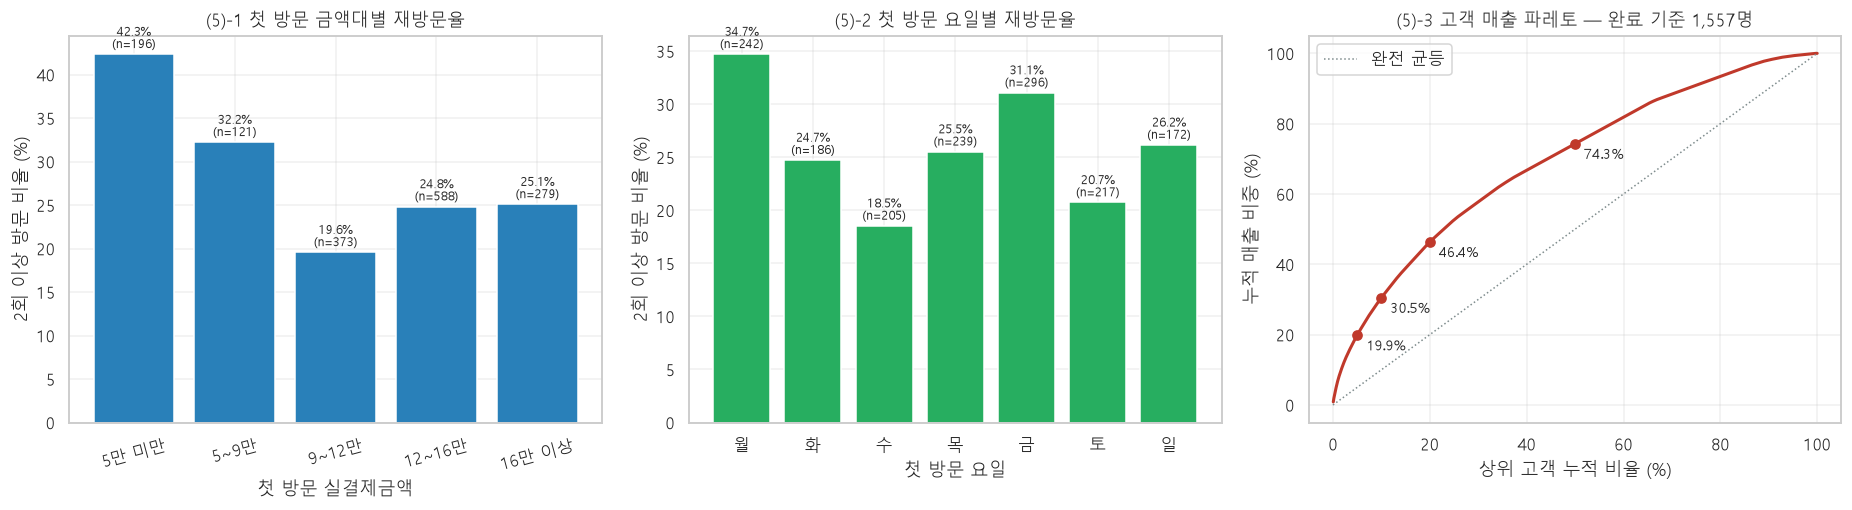

In [31]:
# -- (5) 그래프 --
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

axes[0].bar(PAID_LABELS, _fb.재방문율, color="#2980b9")
for i, v in enumerate(_fb.재방문율):
    axes[0].annotate(f"{v:.1f}%\n(n={int(_fb.인원.iloc[i])})", (i, v),
                     textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
axes[0].set_title("(5)-1 첫 방문 금액대별 재방문율")
axes[0].set_xlabel("첫 방문 실결제금액"); axes[0].set_ylabel("2회 이상 방문 비율 (%)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(DOW_KO, _fd.재방문율, color="#27ae60")
for i, v in enumerate(_fd.재방문율):
    axes[1].annotate(f"{v:.1f}%\n(n={int(_fd.인원.iloc[i])})", (i, v),
                     textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
axes[1].set_title("(5)-2 첫 방문 요일별 재방문율")
axes[1].set_xlabel("첫 방문 요일"); axes[1].set_ylabel("2회 이상 방문 비율 (%)")

_x = np.arange(1, _n + 1) / _n * 100
axes[2].plot(_x, _cum * 100, color="#c0392b", lw=2)
axes[2].plot([0, 100], [0, 100], ls=":", color="#7f8c8d", lw=1, label="완전 균등")
for p in [5, 10, 20, 50]:
    k = int(np.ceil(_n * p / 100))
    axes[2].scatter([p], [_cum[k-1]*100], color="#c0392b", zorder=5)
    axes[2].annotate(f"{_cum[k-1]*100:.1f}%", (p, _cum[k-1]*100),
                     textcoords="offset points", xytext=(6, -10), fontsize=9)
axes[2].set_title(f"(5)-3 고객 매출 파레토 — 완료 기준 {_n:,}명")
axes[2].set_xlabel("상위 고객 누적 비율 (%)"); axes[2].set_ylabel("누적 매출 비중 (%)")
axes[2].legend()
plt.tight_layout(); plt.show()

---
# ⑥ 운영 패턴 — **여기서만 `done_dt`(이용완료일시)를 쓴다**

**무엇을 봤나** — 손님이 언제 예약을 넣고 언제 취소하는지, 그리고 사장님이 언제 정산 처리를 하는지.

**정의**
* `req_dt`(예약신청일시) / `cancel_dt`(예약취소일시) / `done_dt`(이용완료일시)의 **시(hour)** 분포를 겹쳐 본다.
* `done_dt` 는 시술 종료가 아니라 **정산 배치 시각**이다. 이 섹션은 그 사실 자체를 확인하는 것이 목적이다.
  다른 어떤 섹션에서도 `done_dt` 를 쓰지 않는다.
* 영업시간 = `10 <= hour <= 20`. 영업시간 밖 = `hour < 10 or hour > 20`.
* 심야 = `hour in {22, 23, 0, 1, 2}` (22시~익일 02시, 02시 포함).
* 자동확정 = `conf_dt − req_dt <= 60초`. 임계값이 자의적이므로 민감도 표를 함께 낸다.

In [32]:
# -- (6)-1 세 시각의 24시간 분포 --
_h_req    = R.req_dt.dt.hour.value_counts().reindex(range(24), fill_value=0)
_h_cancel = R.cancel_dt.dropna().dt.hour.value_counts().reindex(range(24), fill_value=0)
_h_done   = R.done_dt.dropna().dt.hour.value_counts().reindex(range(24), fill_value=0)

_ops = pd.DataFrame({
    "예약신청(req_dt)": _h_req,
    "예약취소(cancel_dt)": _h_cancel,
    "완료처리(done_dt)": _h_done,
})
_ops.index.name = "시(hour)"
_ops["신청 비중(%)"] = _ops["예약신청(req_dt)"] / _ops["예약신청(req_dt)"].sum() * 100
_ops["취소 비중(%)"] = _ops["예약취소(cancel_dt)"] / _ops["예약취소(cancel_dt)"].sum() * 100
_ops["완료 비중(%)"] = _ops["완료처리(done_dt)"] / _ops["완료처리(done_dt)"].sum() * 100
tbl(_ops.round(2), "(6)-1 시각별 예약신청 · 취소 · 완료처리 건수와 비중")

**(6)-1 시각별 예약신청 · 취소 · 완료처리 건수와 비중**

,예약신청(req_dt),예약취소(cancel_dt),완료처리(done_dt),신청 비중(%),취소 비중(%),완료 비중(%)
시(hour),,,,,,
0,214,85,0,5.00,5.51,0.00
1,119,41,0,2.78,2.66,0.00
2,78,37,0,1.82,2.40,0.00
3,59,23,0,1.38,1.49,0.00
4,37,15,0,0.86,0.97,0.00
5,27,7,0,0.63,0.45,0.00
6,42,20,0,0.98,1.30,0.00
7,44,23,0,1.03,1.49,0.00
8,89,47,0,2.08,3.05,0.00


In [33]:
# -- (6)-2 영업시간 밖 / 심야 / 지연 정산 / 자동확정 --
BIZ_LO, BIZ_HI = 10, 20
NIGHT = {22, 23, 0, 1, 2}

_req_h    = R.req_dt.dt.hour
_off_biz  = (_req_h < BIZ_LO) | (_req_h > BIZ_HI)
_night_req = _req_h.isin(NIGHT)

_dd  = R.dropna(subset=["done_dt"])
_late = (_dd.done_dt.dt.normalize() > _dd.use_dt.dt.normalize())

_conf_gap = (R.conf_dt - R.req_dt).dt.total_seconds()
_auto = _conf_gap <= 60

_ops2 = pd.DataFrame([
    {"지표": f"영업시간({BIZ_LO}~{BIZ_HI}시) 밖에 들어온 예약",
     "해당": int(_off_biz.sum()), "모집단": len(R), "비율(%)": _off_biz.mean()*100,
     "정의": "req_dt.hour < 10 or > 20"},
    {"지표": "심야 22~02시에 들어온 예약",
     "해당": int(_night_req.sum()), "모집단": len(R), "비율(%)": _night_req.mean()*100,
     "정의": "req_dt.hour in {22,23,0,1,2}"},
    {"지표": "완료 처리가 이용일 '다음날 이후'",
     "해당": int(_late.sum()), "모집단": len(_dd), "비율(%)": _late.mean()*100,
     "정의": "done_dt.date > use_dt.date (done_dt 있는 건만)"},
    {"지표": "예약 자동확정 (신청→확정 60초 이내)",
     "해당": int(_auto.sum()), "모집단": len(R), "비율(%)": _auto.mean()*100,
     "정의": "conf_dt - req_dt <= 60s"},
])
tbl(_ops2.round(2), "(6)-2 운영 패턴 지표")
rec("영업시간 밖 예약 신청 비율", pct(_off_biz.mean()), "req_dt.hour <10 or >20 / 전체 예약")
rec("심야(22~02시) 예약 신청 비율", pct(_night_req.mean()), "req_dt.hour in {22,23,0,1,2} / 전체 예약")
rec("완료처리 익일 이후 비율", pct(_late.mean()), "done_dt.date > use_dt.date / done_dt 보유 건")
rec("예약 자동확정 비율(60초 기준)", pct(_auto.mean()),
    "conf_dt - req_dt <= 60초 / 전체 예약 ※원본에서 두 컬럼이 100% 동일 → 지표 판별력 없음")

_sens = []
for thr, lab in [(0, "0초 (동시각)"), (10, "10초 이내"), (60, "60초 이내"),
                 (300, "5분 이내"), (3600, "1시간 이내"), (86400, "24시간 이내")]:
    _sens.append({"임계값": lab, "건수": int((_conf_gap <= thr).sum()),
                  "비율(%)": (_conf_gap <= thr).mean() * 100})
tbl(pd.DataFrame(_sens).round(2), "(6)-2b 자동확정 임계값 민감도")
print("신청→확정 간격 요약(초):")
display(_conf_gap.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_frame("초"))

_identical = (R.conf_dt == R.req_dt).mean()
print()
print("=" * 90)
print(f"⚠ conf_dt 와 req_dt 가 완전히 동일한 예약: {int((R.conf_dt == R.req_dt).sum()):,}/{len(R):,} "
      f"= {_identical*100:.2f}%  (간격 최댓값 {_conf_gap.max():.0f}초)")
print("   원본 네이버 export 두 파일(4,353행 / 5,535행)에서 '예약신청일시' 와 '예약확정일시' 열이")
print("   100% 같은 값이다. 즉 확정일시 컬럼에 독립적인 정보가 없다.")
print("   따라서 '자동확정 비율 100%' 는 발견이 아니라 원본 컬럼 중복이며, 이 지표는 판별력이 없다.")
print("   확정 지연을 보려면 다른 소스가 필요하다.")
print("=" * 90)

**(6)-2 운영 패턴 지표**

,지표,해당,모집단,비율(%),정의
0,영업시간(10~20시) 밖에 들어온 예약,1470,4281,34.34,req_dt.hour < 10 or > 20
1,심야 22~02시에 들어온 예약,818,4281,19.11,"req_dt.hour in {22,23,0,1,2}"
2,완료 처리가 이용일 '다음날 이후',1744,2732,63.84,done_dt.date > use_dt.date (done_dt 있는 건만)
3,예약 자동확정 (신청→확정 60초 이내),4281,4281,100.00,conf_dt - req_dt <= 60s


**(6)-2b 자동확정 임계값 민감도**

,임계값,건수,비율(%)
0,0초 (동시각),4281,100.0
1,10초 이내,4281,100.0
2,60초 이내,4281,100.0
3,5분 이내,4281,100.0
4,1시간 이내,4281,100.0
5,24시간 이내,4281,100.0


신청→확정 간격 요약(초):


,초
count,4281.0
mean,0.0
std,0.0
min,0.0
50%,0.0
75%,0.0
90%,0.0
95%,0.0
99%,0.0
max,0.0



⚠ conf_dt 와 req_dt 가 완전히 동일한 예약: 4,281/4,281 = 100.00%  (간격 최댓값 0초)
   원본 네이버 export 두 파일(4,353행 / 5,535행)에서 '예약신청일시' 와 '예약확정일시' 열이
   100% 같은 값이다. 즉 확정일시 컬럼에 독립적인 정보가 없다.
   따라서 '자동확정 비율 100%' 는 발견이 아니라 원본 컬럼 중복이며, 이 지표는 판별력이 없다.
   확정 지연을 보려면 다른 소스가 필요하다.


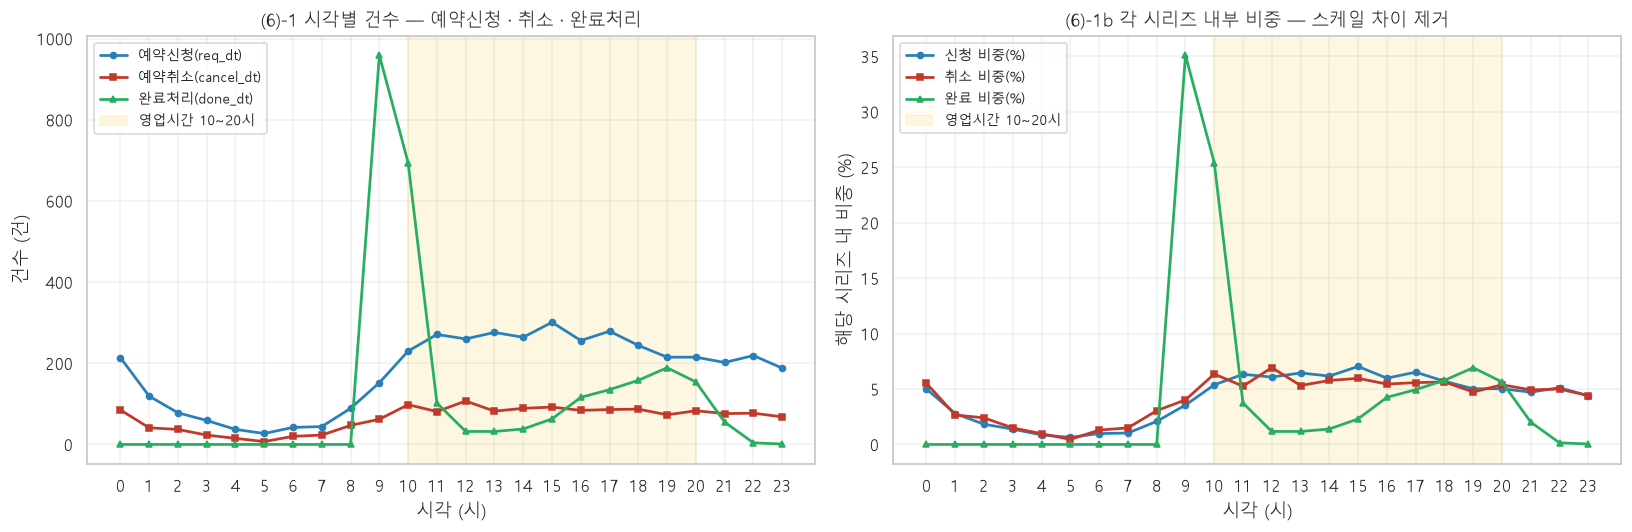

In [34]:
# -- (6) 그래프: 24시간 겹침 --
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for col, color, mk in [("예약신청(req_dt)", "#2980b9", "o"),
                       ("예약취소(cancel_dt)", "#c0392b", "s"),
                       ("완료처리(done_dt)", "#27ae60", "^")]:
    axes[0].plot(_ops.index, _ops[col], marker=mk, color=color, label=col, lw=1.8, ms=4)
axes[0].axvspan(BIZ_LO, BIZ_HI, color="#f1c40f", alpha=.12, label=f"영업시간 {BIZ_LO}~{BIZ_HI}시")
axes[0].set_title("(6)-1 시각별 건수 — 예약신청 · 취소 · 완료처리")
axes[0].set_xlabel("시각 (시)"); axes[0].set_ylabel("건수 (건)")
axes[0].set_xticks(range(0, 24)); axes[0].legend(fontsize=9)

for col, color, mk in [("신청 비중(%)", "#2980b9", "o"),
                       ("취소 비중(%)", "#c0392b", "s"),
                       ("완료 비중(%)", "#27ae60", "^")]:
    axes[1].plot(_ops.index, _ops[col], marker=mk, color=color, label=col, lw=1.8, ms=4)
axes[1].axvspan(BIZ_LO, BIZ_HI, color="#f1c40f", alpha=.12, label=f"영업시간 {BIZ_LO}~{BIZ_HI}시")
axes[1].set_title("(6)-1b 각 시리즈 내부 비중 — 스케일 차이 제거")
axes[1].set_xlabel("시각 (시)"); axes[1].set_ylabel("해당 시리즈 내 비중 (%)")
axes[1].set_xticks(range(0, 24)); axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

---
# ⑦ 스마트플레이스 — **자료 없음으로 생략**

원자료(3개월치 통계 이미지)가 이 프로젝트에 없다. 해당 섹션은 만들지 않는다.

---
# ⑧ 부가 발견

**무엇을 봤나** — 요청사항을 쓰는 손님이 다른가, 외국어 메뉴로 잡은 예약이 더 깨지는가,
무료 아쿠아클리닉을 계속 붙여 주고 있는가.

**정의**
* 요청사항 지표는 **단위가 섞여 있다.** 표에 단위를 명시했다.
  - 취소율 · 당일예약 비율 · 객단가 → **예약 단위** (`has_request`)
  - 평균 방문 횟수 → **고객 단위** (그 고객이 요청사항을 한 번이라도 썼는가)
* 당일예약 = `use_dt.date == req_dt.date`.
* 메뉴 언어 판별 순서: 한글(`가-힣`)이 하나라도 있으면 한국어 → 없고 한자/가나가 있으면 중국어·일본어
  → 없고 알파벳이 있으면 영어 → 그 외 기타. **예약이 아니라 메뉴 라인 단위** 집계다.
* 무료 아쿠아클리닉 = `menu_category.csv` 의 `is_free == 1` 메뉴 5종
  (`아쿠아클리닉`, `아쿠아`, 그리고 아쿠아클리닉의 자동번역 표기 — `아쿠아클리닉 (영어)` · `아쿠아클리닉 (일본어)` · `아쿠아클리닉 (중국어)`).
  `아쿠아클리닉` 정확일치 값도 함께 낸다.

In [35]:
# -- (8)-1 요청사항 작성 여부 --
R["same_day"] = R.use_dt.dt.normalize() == R.req_dt.dt.normalize()
DONE["same_day"] = DONE.use_dt.dt.normalize() == DONE.req_dt.dt.normalize()

_ever_req = R.groupby("cust_key").has_request.any()
CUST["요청사항작성"] = CUST.index.map(_ever_req)

_rq = pd.DataFrame({
    "예약 건수 [예약단위]": R.groupby("has_request").size(),
    "취소율(%) [예약단위]": R.groupby("has_request").status.apply(lambda s: (s == "취소").mean() * 100),
    "당일예약 비율(%) [예약단위]": R.groupby("has_request").same_day.mean() * 100,
    "완료 객단가 중앙값 [예약단위]": DONE.groupby("has_request").paid.median(),
    "완료 객단가 평균 [예약단위]": DONE.groupby("has_request").paid.mean(),
})
_rq.index = ["미작성", "작성"]

_cu = CUST.groupby("요청사항작성").agg(고객수=("방문횟수", "size"),
                                       평균방문횟수=("방문횟수", "mean"),
                                       누적지출평균=("누적지출", "mean"),
                                       재방문율=("재방문", "mean"))
_cu.index = ["미작성", "작성"]
_cu["재방문율"] = _cu.재방문율 * 100
_cu.columns = ["고객 수 [고객단위]", "평균 방문 횟수 [고객단위]",
               "누적지출 평균 [고객단위]", "재방문율(%) [고객단위]"]

tbl(_rq.round(2), "(8)-1a 요청사항 작성 여부별 — 예약 단위 지표")
tbl(_cu.round(4), "(8)-1b 요청사항 작성 여부별 — 고객 단위 지표 (cust_key 가 한 번이라도 작성했는가)")

# 참고: 같은 질문을 '예약 단위'로 재면 값이 크게 달라진다. 단위 차이가 대조에서 가장 흔한 오차 원인이므로 병기한다.
_nv = DONE.groupby("cust_key").size()
_ref = (R.assign(그고객의_방문횟수=R.cust_key.map(_nv))
          .dropna(subset=["그고객의_방문횟수"])
          .groupby("has_request")["그고객의_방문횟수"].agg(["size", "mean"]))
_ref.index = ["미작성", "작성"]
_ref.columns = ["예약 건수", "평균 방문 횟수 [예약단위 — 참고]"]
tbl(_ref.round(4), "(8)-1c (참고) 같은 지표를 예약 단위로 재면 — 본 노트북 채택값은 (8)-1b 쪽이다")
rec("요청사항 작성 고객 평균 방문 횟수", f"{_cu.loc['작성', '평균 방문 횟수 [고객단위]']:.4f}회",
    "완료기준 고객 중 요청사항 1건 이상 작성 그룹의 완료 방문수 평균")
rec("요청사항 미작성 고객 평균 방문 횟수", f"{_cu.loc['미작성', '평균 방문 횟수 [고객단위]']:.4f}회",
    "완료기준 고객 중 요청사항 0건 그룹의 완료 방문수 평균")
rec("요청사항 작성 예약 취소율", f"{_rq.loc['작성', '취소율(%) [예약단위]']:.2f}%", "has_request=True 예약")
rec("요청사항 미작성 예약 취소율", f"{_rq.loc['미작성', '취소율(%) [예약단위]']:.2f}%", "has_request=False 예약")

**(8)-1a 요청사항 작성 여부별 — 예약 단위 지표**

,예약 건수 [예약단위],취소율(%) [예약단위],당일예약 비율(%) [예약단위],완료 객단가 중앙값 [예약단위],완료 객단가 평균 [예약단위]
미작성,3854,36.30,27.45,100000.0,111629.91
작성,427,33.49,18.50,145000.0,125773.85


**(8)-1b 요청사항 작성 여부별 — 고객 단위 지표 (cust_key 가 한 번이라도 작성했는가)**

,고객 수 [고객단위],평균 방문 횟수 [고객단위],누적지출 평균 [고객단위],재방문율(%) [고객단위]
미작성,1312,1.5671,182678.3537,22.7896
작성,245,2.7592,282863.8776,45.7143


**(8)-1c (참고) 같은 지표를 예약 단위로 재면 — 본 노트북 채택값은 (8)-1b 쪽이다**

,예약 건수,평균 방문 횟수 [예약단위 — 참고]
미작성,3467,6.2553
작성,377,9.2202


'36.30%'

In [36]:
# -- (8)-2 메뉴 언어별 취소율 [라인 기준] --
_HANGUL = re.compile(r"[가-힣]")
_CJK    = re.compile("[\\u4e00-\\u9fff\\u3040-\\u309f\\u30a0-\\u30ff]")
_LATIN  = re.compile(r"[A-Za-z]")

def _lang(s):
    if _HANGUL.search(s): return "한국어"
    if _CJK.search(s):    return "중국어·일본어"
    if _LATIN.search(s):  return "영어"
    return "기타"

LX["lang"] = LX.menu.map(_lang)
LANG_ORDER = ["한국어", "중국어·일본어", "영어", "기타"]
_lg = (LX.groupby("lang")
         .agg(라인수=("menu", "size"),
              취소라인=("status", lambda s: int((s == "취소").sum())),
              완료라인=("status", lambda s: int((s == "이용완료").sum())),
              메뉴종수=("menu", "nunique"))
         .reindex(LANG_ORDER).dropna(how="all")
         .astype({"라인수": int, "취소라인": int, "완료라인": int, "메뉴종수": int}))
_lg["취소율(%)"]   = _lg.취소라인 / _lg.라인수 * 100
_lg["라인비중(%)"] = _lg.라인수 / len(LX) * 100
tbl(_lg.round(2), "(8)-2 메뉴 언어별 취소율 — ★라인 기준★ (예약 단위 아님)")
for k in _lg.index:
    rec(f"메뉴 언어별 취소율(라인) · {k}", f"{_lg.loc[k, '취소율(%)']:.2f}% (n={int(_lg.loc[k, '라인수']):,}라인)",
        "menu_lines(비시술 제외)에 예약 status 부착 후 언어별 집계")

**(8)-2 메뉴 언어별 취소율 — ★라인 기준★ (예약 단위 아님)**

,라인수,취소라인,완료라인,메뉴종수,취소율(%),라인비중(%)
lang,,,,,,
한국어,7069,2598,4459,68,36.75,98.70
중국어·일본어,65,14,51,17,21.54,0.91
영어,28,7,21,8,25.00,0.39


In [37]:
# -- (8)-3 무료 아쿠아클리닉 부착률 추이 --
_free_menus  = set(CATMAP.loc[CATMAP.is_free == 1, "menu"])
_done_ids    = set(DONE.예약번호)
_L_done      = L[L.예약번호.isin(_done_ids)]
_has_free    = _L_done[_L_done.menu.isin(_free_menus)].예약번호.unique()
_has_exact   = _L_done[_L_done.menu == "아쿠아클리닉"].예약번호.unique()

DONE["아쿠아_5종"]   = DONE.예약번호.isin(_has_free)
DONE["아쿠아_정확"] = DONE.예약번호.isin(_has_exact)

_att = (DONE.groupby("ym")
            .agg(완료건수=("예약번호", "size"),
                 부착_5종=("아쿠아_5종", "sum"),
                 부착_정확일치=("아쿠아_정확", "sum")))
_att["부착률_5종(%)"]       = _att.부착_5종 / _att.완료건수 * 100
_att["부착률_정확일치(%)"] = _att.부착_정확일치 / _att.완료건수 * 100
tbl(_att.round(2), "(8)-3 월별 무료 아쿠아클리닉 부착률 — 완료 예약 기준")

_overall = DONE.아쿠아_5종.mean()
print(f"전체 완료 기준 부착률(5종) {_overall*100:.2f}%  ({int(DONE.아쿠아_5종.sum()):,}/{len(DONE):,}건)")

# 이 메뉴는 2025-08 에 처음 등장한다. 그 이전 0% 는 '떼어냈다' 가 아니라 '메뉴가 없었다' 이므로
# 전체 기간 앞뒤 3개월을 비교하면 하락 추세가 아니라 도입 효과를 보게 된다. 도입 이후만 비교한다.
_launch = _att.index[_att["부착률_5종(%)"] > 0][0]
_post   = _att[_att.index >= _launch]
_ramped = _post[_post["부착률_5종(%)"] >= 50]        # 도입 정착 이후
_f3, _l3 = _ramped["부착률_5종(%)"].head(3).mean(), _ramped["부착률_5종(%)"].tail(3).mean()
print(f"메뉴 최초 등장 월: {_launch}  (그 이전 월의 0% 는 메뉴 미존재이지 이탈이 아니다)")
print(f"정착(50%+) 이후 구간 {_ramped.index.min()} ~ {_ramped.index.max()}: "
      f"앞 3개월 {_f3:.2f}%  ->  뒤 3개월 {_l3:.2f}%  (차이 {_l3-_f3:+.2f}%p)")
rec("무료 아쿠아클리닉 부착률 (전체 완료)", pct(_overall),
    "완료 예약 중 is_free 메뉴 5종 포함 비율 (2025-08 신설 이전 월 포함)")
rec("아쿠아 메뉴 최초 등장 월", str(_launch), "월별 부착률 > 0 인 첫 달")
rec("아쿠아 부착률 정착후 앞3개월 -> 뒤3개월",
    f"{_f3:.2f}% -> {_l3:.2f}% ({_l3-_f3:+.2f}%p)",
    "부착률 50% 이상 구간의 앞 3개월/뒤 3개월 평균")

**(8)-3 월별 무료 아쿠아클리닉 부착률 — 완료 예약 기준**

,완료건수,부착_5종,부착_정확일치,부착률_5종(%),부착률_정확일치(%)
ym,,,,,
2025-01,127,0,0,0.00,0.00
2025-02,149,0,0,0.00,0.00
2025-03,120,0,0,0.00,0.00
2025-04,103,0,0,0.00,0.00
2025-05,117,0,0,0.00,0.00
2025-06,108,1,0,0.93,0.00
2025-07,118,0,0,0.00,0.00
2025-08,138,34,34,24.64,24.64
2025-09,92,91,91,98.91,98.91


전체 완료 기준 부착률(5종) 59.30%  (1,620/2,732건)
메뉴 최초 등장 월: 2025-06  (그 이전 월의 0% 는 메뉴 미존재이지 이탈이 아니다)
정착(50%+) 이후 구간 2025-09 ~ 2026-08: 앞 3개월 97.69%  ->  뒤 3개월 86.09%  (차이 -11.59%p)


'97.69% -> 86.09% (-11.59%p)'

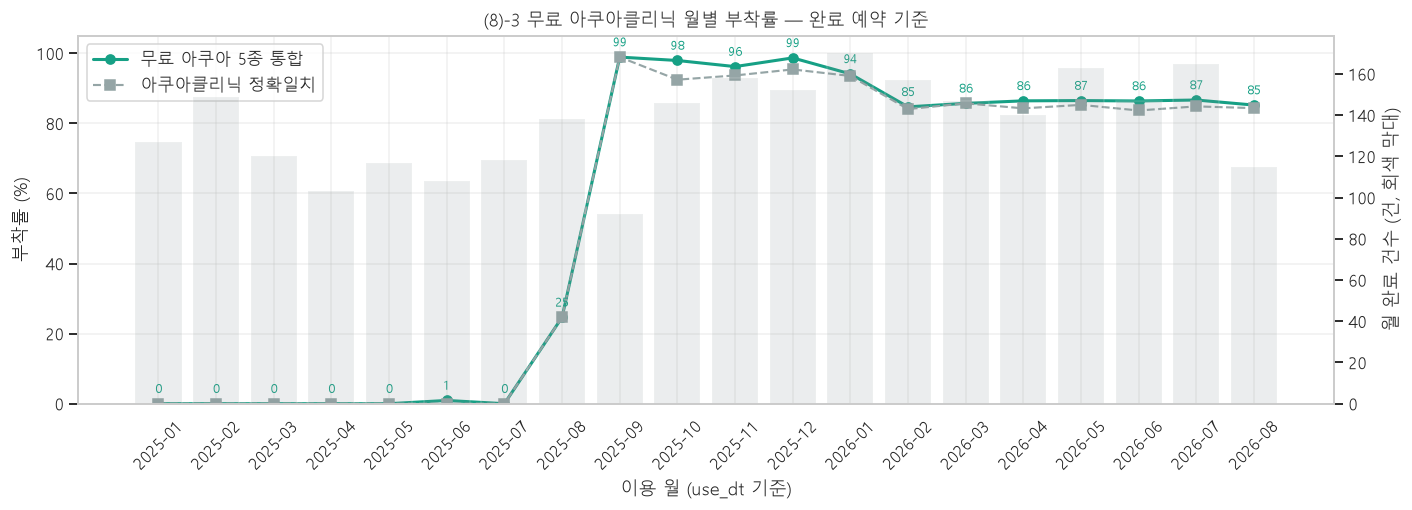

In [38]:
# -- (8) 그래프: 부착률 시계열 --
fig, ax = plt.subplots(figsize=(13, 4.8))
_x = _att.index.astype(str)
ax.plot(_x, _att["부착률_5종(%)"], marker="o", color="#16a085", lw=2, label="무료 아쿠아 5종 통합")
ax.plot(_x, _att["부착률_정확일치(%)"], marker="s", color="#95a5a6", lw=1.4, ls="--",
        label="아쿠아클리닉 정확일치")
for i, v in enumerate(_att["부착률_5종(%)"]):
    ax.annotate(f"{v:.0f}", (i, v), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=8, color="#16a085")
ax.set_title("(8)-3 무료 아쿠아클리닉 월별 부착률 — 완료 예약 기준")
ax.set_xlabel("이용 월 (use_dt 기준)"); ax.set_ylabel("부착률 (%)")
ax.set_ylim(0, 105); ax.tick_params(axis="x", rotation=45); ax.legend()
ax2 = ax.twinx(); ax2.grid(False)
ax2.bar(_x, _att.완료건수, alpha=.15, color="#7f8c8d")
ax2.set_ylabel("월 완료 건수 (건, 회색 막대)")
plt.tight_layout(); plt.show()

---
# ⑨ 취소율 변화 분해 (shift-share)

**무엇을 봤나** — 취소율이 올랐다면, 각 리드타임 구간이 실제로 나빠져서인가,
아니면 예약이 더 미리 들어오는 쪽으로 **구성이 이동**해서 생긴 착시인가.

**정의**
* 기간 구분은 `ym`(= `use_dt` 의 연월) 기준.
  - **A 기간** = 2025-01 ~ 2025-10
  - **B 기간** = 2025-11 ~ 2026-08
* 리드타임 구간은 ②와 동일.

### shift-share 계산식

전체 취소율은 구간별 취소율의 가중평균이다.

```
r = Σᵢ wᵢ · rᵢ        wᵢ = 구간 i 의 예약 비중,  rᵢ = 구간 i 의 취소율
```

두 기간의 차이를 세 항으로 정확히 분해한다(잔차 0).

```
Δr = r_B − r_A
   = Σᵢ ( w_iB·r_iB − w_iA·r_iA )

   = Σᵢ  w_iA · (r_iB − r_iA)              ← ① 취소율 효과 (rate effect)
   + Σᵢ (w_iB − w_iA) ·  r_iA              ← ② 구성 효과 (mix / shift effect)
   + Σᵢ (w_iB − w_iA) · (r_iB − r_iA)      ← ③ 교차항 (interaction)
```

①은 "구성이 그대로였다면 취소율 악화만으로 얼마나 올랐을까",
②는 "구간별 취소율이 그대로였다면 구성 이동만으로 얼마나 올랐을까",
③은 둘이 동시에 움직인 몫이다. 교차항을 절반씩 나눠 2항으로 배분한 값도 함께 낸다.

In [39]:
# -- (9)-1 두 기간 정의와 리드타임 구간별 취소율 --
P_A = (pd.Period("2025-01", "M"), pd.Period("2025-10", "M"))
P_B = (pd.Period("2025-11", "M"), pd.Period("2026-08", "M"))

def _period_of(ym):
    if P_A[0] <= ym <= P_A[1]: return "A (2025-01~2025-10)"
    if P_B[0] <= ym <= P_B[1]: return "B (2025-11~2026-08)"
    return "(범위 밖)"

R["period"]    = R.ym.map(_period_of)
DONE["period"] = DONE.ym.map(_period_of)
PA, PB = "A (2025-01~2025-10)", "B (2025-11~2026-08)"
print(R.period.value_counts().to_dict())

_sh = (R[R.period.isin([PA, PB])]
       .groupby(["period", "lead_bin"], observed=False)
       .agg(예약=("예약번호", "size"), 취소=("status", lambda s: int((s == "취소").sum()))))
_sh["취소율"] = _sh.취소 / _sh.예약
_sh["비중"]   = _sh.예약 / _sh.groupby("period").예약.transform("sum")

_wide = pd.DataFrame({
    "A 예약수":   _sh.loc[PA, "예약"],
    "A 비중 w":   _sh.loc[PA, "비중"],
    "A 취소율 r": _sh.loc[PA, "취소율"],
    "B 예약수":   _sh.loc[PB, "예약"],
    "B 비중 w":   _sh.loc[PB, "비중"],
    "B 취소율 r": _sh.loc[PB, "취소율"],
}).reindex(LEAD_LABELS)
_wide["취소율 변화(%p)"] = (_wide["B 취소율 r"] - _wide["A 취소율 r"]) * 100
_wide["비중 변화(%p)"]   = (_wide["B 비중 w"] - _wide["A 비중 w"]) * 100
tbl(_wide.assign(**{"A 비중 w": _wide["A 비중 w"]*100, "B 비중 w": _wide["B 비중 w"]*100,
                    "A 취소율 r": _wide["A 취소율 r"]*100, "B 취소율 r": _wide["B 취소율 r"]*100}).round(2),
    "(9)-1 기간 A vs B — 리드타임 구간별 예약 비중(%)과 취소율(%)")

{'B (2025-11~2026-08)': 2471, 'A (2025-01~2025-10)': 1810}


**(9)-1 기간 A vs B — 리드타임 구간별 예약 비중(%)과 취소율(%)**

,A 예약수,A 비중 w,A 취소율 r,B 예약수,B 비중 w,B 취소율 r,취소율 변화(%p),비중 변화(%p)
lead_bin,,,,,,,,
6시간 미만,444,24.53,13.74,457,18.49,15.97,2.24,-6.04
6~24시간,411,22.71,25.30,478,19.34,28.87,3.57,-3.36
1~3일,379,20.94,36.15,560,22.66,36.07,-0.08,1.72
3~7일,290,16.02,42.41,461,18.66,45.99,3.57,2.63
1~2주,163,9.01,52.76,301,12.18,57.14,4.38,3.18
2주 이상,123,6.80,65.04,214,8.66,71.96,6.92,1.86


In [40]:
# -- (9)-2 shift-share 분해 --
wA, rA = _wide["A 비중 w"].values, _wide["A 취소율 r"].values
wB, rB = _wide["B 비중 w"].values, _wide["B 취소율 r"].values

rate_eff  = float(np.sum(wA * (rB - rA)))
mix_eff   = float(np.sum((wB - wA) * rA))
inter_eff = float(np.sum((wB - wA) * (rB - rA)))
r_A, r_B  = float(np.sum(wA * rA)), float(np.sum(wB * rB))
delta     = r_B - r_A

_dec = pd.DataFrame([
    {"항": "A 기간 전체 취소율  r_A", "값(%p)": r_A*100, "식": "Σ w_iA·r_iA"},
    {"항": "B 기간 전체 취소율  r_B", "값(%p)": r_B*100, "식": "Σ w_iB·r_iB"},
    {"항": "총 변화  Δr = r_B − r_A", "값(%p)": delta*100, "식": "r_B − r_A"},
    {"항": "① 취소율 효과 (rate)",    "값(%p)": rate_eff*100,  "식": "Σ w_iA·(r_iB − r_iA)"},
    {"항": "② 구성 효과 (mix)",       "값(%p)": mix_eff*100,   "식": "Σ (w_iB − w_iA)·r_iA"},
    {"항": "③ 교차항 (interaction)",  "값(%p)": inter_eff*100, "식": "Σ (w_iB − w_iA)·(r_iB − r_iA)"},
    {"항": "①+②+③ 합 (검산)",        "값(%p)": (rate_eff+mix_eff+inter_eff)*100, "식": "= Δr 이어야 함"},
])
_dec["Δr 대비 몫(%)"] = _dec["값(%p)"] / (delta * 100) * 100
_dec.loc[_dec.항.str.startswith(("A 기간", "B 기간")), "Δr 대비 몫(%)"] = np.nan  # 수준 값에는 몫이 없다
tbl(_dec.round(4), "(9)-2 shift-share 3항 분해")
print(f"검산 잔차: {abs((rate_eff+mix_eff+inter_eff) - delta):.3e} (0이어야 정확 분해)")

_half = pd.DataFrame([
    {"항": "취소율 효과 (교차항 절반 배분)", "값(%p)": (rate_eff + inter_eff/2)*100},
    {"항": "구성 효과 (교차항 절반 배분)",   "값(%p)": (mix_eff  + inter_eff/2)*100},
])
_half["Δr 대비 몫(%)"] = _half["값(%p)"] / (delta*100) * 100
tbl(_half.round(4), "(9)-2b 교차항을 절반씩 배분한 2항 버전")

rec("취소율 A기간(2025-01~10)", pct(r_A), "shift-share 가중평균 = 해당 기간 취소/예약")
rec("취소율 B기간(2025-11~2026-08)", pct(r_B), "shift-share 가중평균")
rec("취소율 총 변화 Δr", f"{delta*100:+.2f}%p", "r_B − r_A")
rec("Δr 중 취소율 효과(rate)", f"{rate_eff*100:+.2f}%p ({rate_eff/delta*100:.1f}%)", "Σ w_iA(r_iB−r_iA)")
rec("Δr 중 구성 효과(mix)",   f"{mix_eff*100:+.2f}%p ({mix_eff/delta*100:.1f}%)", "Σ (w_iB−w_iA)r_iA")
rec("Δr 중 교차항",           f"{inter_eff*100:+.2f}%p ({inter_eff/delta*100:.1f}%)", "Σ (w_iB−w_iA)(r_iB−r_iA)")

**(9)-2 shift-share 3항 분해**

,항,값(%p),식,Δr 대비 몫(%)
0,A 기간 전체 취소율 r_A,32.6519,Σ w_iA·r_iA,
1,B 기간 전체 취소율 r_B,38.4864,Σ w_iB·r_iB,
2,총 변화 Δr = r_B − r_A,5.8345,r_B − r_A,100.0000
3,① 취소율 효과 (rate),2.7796,Σ w_iA·(r_iB − r_iA),47.6401
4,② 구성 효과 (mix),2.9487,Σ (w_iB − w_iA)·r_iA,50.5389
5,③ 교차항 (interaction),0.1062,Σ (w_iB − w_iA)·(r_iB − r_iA),1.8209
6,①+②+③ 합 (검산),5.8345,= Δr 이어야 함,100.0000


검산 잔차: 6.245e-17 (0이어야 정확 분해)


**(9)-2b 교차항을 절반씩 배분한 2항 버전**

,항,값(%p),Δr 대비 몫(%)
0,취소율 효과 (교차항 절반 배분),2.8327,48.5506
1,구성 효과 (교차항 절반 배분),3.0018,51.4494


'+0.11%p (1.8%)'

In [41]:
# -- (9)-3 같은 두 기간의 완료 건수 분포 / 당일예약 / 객단가 --
_dsub = DONE[DONE.period.isin([PA, PB])].copy()
_dsub["date"] = _dsub.use_dt.dt.normalize()
_daily = _dsub.groupby(["period", "date"]).size().rename("일완료건수").reset_index()
_dd = _daily.groupby("period").일완료건수.describe()[["count", "mean", "50%", "std", "max"]]
_dd.columns = ["영업일 수", "하루 평균 완료건수", "중앙값", "표준편차", "최대"]

_pp = pd.DataFrame({
    "예약 건수":        R[R.period.isin([PA, PB])].groupby("period").size(),
    "완료 건수":        DONE.groupby("period").size().reindex([PA, PB]),
    "취소율(%)":        R[R.period.isin([PA, PB])].groupby("period").status.apply(lambda s: (s == "취소").mean()*100),
    "당일예약 비중(%)": R[R.period.isin([PA, PB])].groupby("period").same_day.mean()*100,
    "완료 객단가 중앙값": DONE.groupby("period").paid.median().reindex([PA, PB]),
    "완료 객단가 평균":   DONE.groupby("period").paid.mean().reindex([PA, PB]),
    "완료 매출":         DONE.groupby("period").paid.sum().reindex([PA, PB]),
}).join(_dd)
tbl(_pp.round(2).T.map(lambda v: f"{v:,.2f}"), "(9)-3 기간 A vs B 요약 (행=지표, 열=기간)")
rec("당일예약 비중 A -> B",
    f"{_pp.loc[PA, '당일예약 비중(%)']:.2f}% -> {_pp.loc[PB, '당일예약 비중(%)']:.2f}%",
    "use_dt.date == req_dt.date 비율")
rec("완료 객단가 중앙값 A -> B",
    f"{won(_pp.loc[PA, '완료 객단가 중앙값'])} -> {won(_pp.loc[PB, '완료 객단가 중앙값'])}원",
    "기간별 완료 paid 중앙값")

**(9)-3 기간 A vs B 요약 (행=지표, 열=기간)**

period,A (2025-01~2025-10),B (2025-11~2026-08)
예약 건수,"1,810.00","2,471.00"
완료 건수,"1,218.00","1,514.00"
취소율(%),32.65,38.49
당일예약 비중(%),31.05,23.27
완료 객단가 중앙값,"100,000.00","100,000.00"
완료 객단가 평균,"101,946.35","122,064.07"
완료 매출,"124,170,650.00","184,805,000.00"
영업일 수,292.00,288.00
하루 평균 완료건수,4.17,5.26
중앙값,4.00,5.00


'100,000 -> 100,000원'

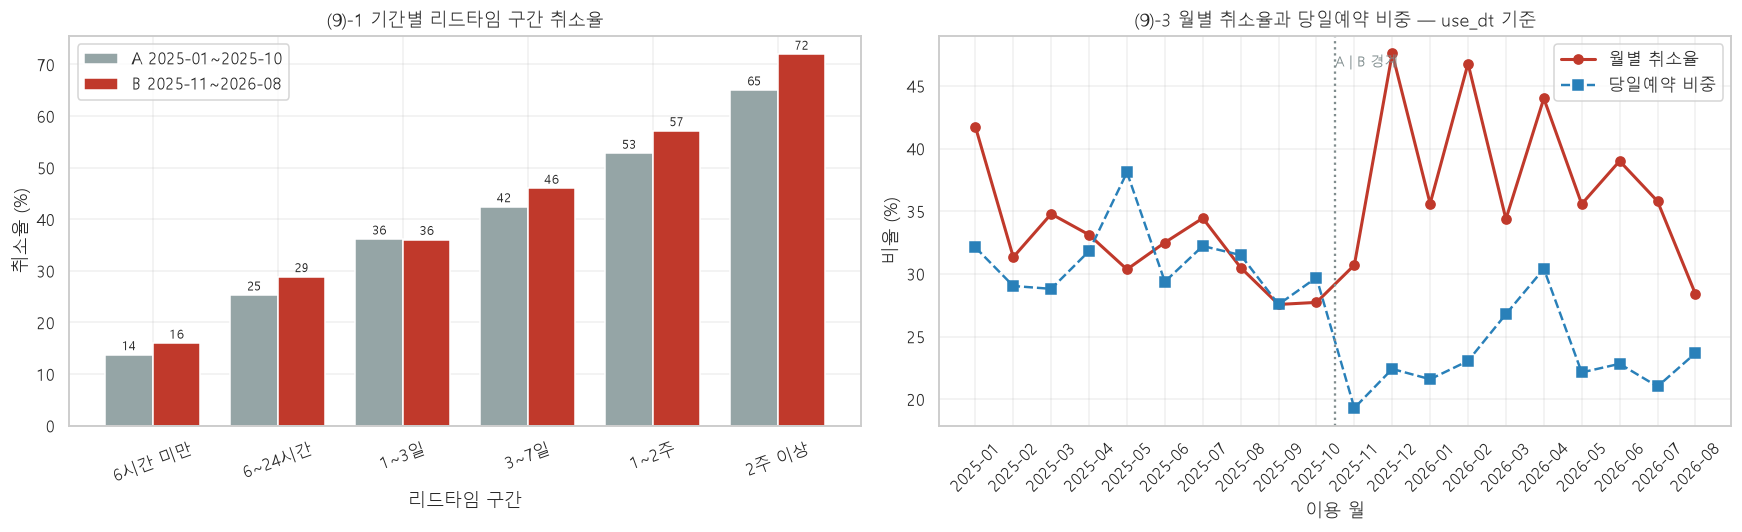

In [42]:
# -- (9) 그래프 --
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

_x = np.arange(len(LEAD_LABELS)); _w = 0.38
axes[0].bar(_x - _w/2, _wide["A 취소율 r"]*100, _w, label="A 2025-01~2025-10", color="#95a5a6")
axes[0].bar(_x + _w/2, _wide["B 취소율 r"]*100, _w, label="B 2025-11~2026-08", color="#c0392b")
for i in range(len(_x)):
    axes[0].annotate(f"{_wide['A 취소율 r'].iloc[i]*100:.0f}", (_x[i]-_w/2, _wide['A 취소율 r'].iloc[i]*100),
                     textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
    axes[0].annotate(f"{_wide['B 취소율 r'].iloc[i]*100:.0f}", (_x[i]+_w/2, _wide['B 취소율 r'].iloc[i]*100),
                     textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)
axes[0].set_xticks(_x); axes[0].set_xticklabels(LEAD_LABELS, rotation=20)
axes[0].set_title("(9)-1 기간별 리드타임 구간 취소율")
axes[0].set_xlabel("리드타임 구간"); axes[0].set_ylabel("취소율 (%)"); axes[0].legend()

_m = (R.groupby("ym")
        .agg(예약=("예약번호", "size"),
             취소=("status", lambda s: int((s == "취소").sum())),
             당일=("same_day", "mean")))
_m["취소율(%)"] = _m.취소 / _m.예약 * 100
_m["당일예약(%)"] = _m.당일 * 100
_xs = _m.index.astype(str)
axes[1].plot(_xs, _m["취소율(%)"], marker="o", color="#c0392b", lw=2, label="월별 취소율")
axes[1].plot(_xs, _m["당일예약(%)"], marker="s", color="#2980b9", lw=1.6, ls="--", label="당일예약 비중")
_cut_i = list(_xs).index("2025-11")
axes[1].axvline(_cut_i - 0.5, color="#7f8c8d", ls=":", lw=1.5)
axes[1].annotate("A | B 경계", (_cut_i - 0.5, axes[1].get_ylim()[1]*0.95), fontsize=9, color="#7f8c8d")
axes[1].set_title("(9)-3 월별 취소율과 당일예약 비중 — use_dt 기준")
axes[1].set_xlabel("이용 월"); axes[1].set_ylabel("비율 (%)")
axes[1].tick_params(axis="x", rotation=45); axes[1].legend()
plt.tight_layout(); plt.show()

---
# ⑩ 코호트 재방문

**무엇을 봤나** — 첫 방문 월별로 고객을 묶었을 때 몇 달 뒤에 얼마나 돌아오는지, 재방문 간격이 얼마인지.

**정의**
* 코호트 = 그 고객의 **첫 이용완료 방문의 월**(`use_dt` 기준).
* `M+k` 재방문율 = 코호트 인원 중 `첫방문월 + k` 월에 이용완료 방문이 **1건 이상** 있는 비율.
  같은 달 재방문(M+0)은 표에 넣지 않는다.
* 관측 종료가 2026-08 이므로 `첫방문월 + k > 2026-08` 인 셀은 **관측 불가(NaN)** 로 비운다.
  0%가 아니라 "아직 관측 못 함"이다.
* 재방문 간격 = 같은 고객의 **연속된 완료 방문 사이 일수**(④에서 만든 인접 쌍과 동일 정의).

**⚠️ 코호트 편향** — 네이버 데이터는 2025-01부터 시작하는데 살롱은 14.5년차다.
2025년 초 코호트의 "첫 방문"은 상당수가 실제로는 기존 단골의 재방문이다. 초기 코호트를 신규 유입으로 읽으면 안 된다.

In [43]:
# -- (10)-1 코호트 표 --
_visits = DONE[["cust_key", "use_dt", "ym"]].copy()
_first_ym = CUST.첫방문일.dt.to_period("M").rename("cohort")
_visits = _visits.join(_first_ym, on="cust_key")
_visits["k"] = ((_visits.ym.dt.year * 12 + _visits.ym.dt.month)
                - (_visits.cohort.dt.year * 12 + _visits.cohort.dt.month))

MAXK = 7
LAST_YM = R.ym.max()
_size = _first_ym.value_counts().sort_index().rename("코호트 인원")
_pv = (_visits[(_visits.k >= 1) & (_visits.k <= MAXK)]
       .drop_duplicates(["cust_key", "cohort", "k"])
       .pivot_table(index="cohort", columns="k", values="cust_key", aggfunc="size"))
_pv = _pv.reindex(index=_size.index, columns=range(1, MAXK + 1)).fillna(0)
_coh = _pv.div(_size, axis=0) * 100          # 재방문 0명인 달은 진짜 0%
_coh.columns = [f"M+{k}" for k in _coh.columns]
for c_ym in _coh.index:                      # 관측 기간을 넘어간 셀만 NaN 으로 비운다
    for k in range(1, MAXK + 1):
        if c_ym + k > LAST_YM:
            _coh.loc[c_ym, f"M+{k}"] = np.nan

_coh_out = pd.concat([_size, _coh.round(2)], axis=1)
tbl(_coh_out, f"(10)-1 첫 방문 월 코호트별 M+1~M+{MAXK} 재방문율 (%) — 빈 칸은 관측 불가")
print("주의: NaN 은 0% 가 아니라 관측 기간(~2026-08)을 넘어가 아직 볼 수 없는 셀이다.")
rec("코호트 M+1 평균 재방문율", f"{_coh['M+1'].mean():.2f}%", "코호트별 M+1 재방문율의 단순 평균")
rec("코호트 M+2 평균 재방문율", f"{_coh['M+2'].mean():.2f}%", "코호트별 M+2 재방문율의 단순 평균")

**(10)-1 첫 방문 월 코호트별 M+1~M+7 재방문율 (%) — 빈 칸은 관측 불가**

,코호트 인원,M+1,M+2,M+3,M+4,M+5,M+6,M+7
cohort,,,,,,,,
2025-01,115,16.52,26.09,17.39,22.61,14.78,15.65,18.26
2025-02,116,6.90,14.66,14.66,12.07,6.90,14.66,4.31
2025-03,67,5.97,7.46,10.45,7.46,10.45,8.96,4.48
2025-04,50,8.00,8.00,4.00,6.00,4.00,6.00,4.00
2025-05,53,16.98,5.66,3.77,7.55,5.66,1.89,1.89
2025-06,52,1.92,9.62,5.77,3.85,7.69,1.92,3.85
2025-07,64,4.69,4.69,6.25,6.25,3.12,3.12,3.12
2025-08,71,5.63,8.45,11.27,7.04,4.23,5.63,7.04
2025-09,36,2.78,8.33,2.78,2.78,0.00,5.56,0.00


주의: NaN 은 0% 가 아니라 관측 기간(~2026-08)을 넘어가 아직 볼 수 없는 셀이다.


'8.36%'

In [44]:
# -- (10)-2 재방문 간격 --
PAIRS["gap_days"] = (PAIRS.use_dt - PAIRS.prev_dt).dt.total_seconds() / 86400
_gap = PAIRS.gap_days
_gs = _gap.describe(percentiles=[.10, .25, .5, .75, .90, .95]).round(2).to_frame("일수")
tbl(_gs, f"(10)-2 재방문 간격 분포 (연속 완료 방문 쌍 {len(PAIRS):,}개)")

GAP_EDGES  = [0, 14, 28, 42, 56, 84, 120, 180, np.inf]
GAP_LABELS = ["0~14일", "14~28일", "28~42일", "42~56일", "56~84일", "84~120일", "120~180일", "180일+"]
_gd = pd.cut(_gap, bins=GAP_EDGES, labels=GAP_LABELS, right=False).value_counts().reindex(GAP_LABELS)
_gd = _gd.rename("쌍 수").to_frame()
_gd["비중(%)"] = _gd["쌍 수"] / len(PAIRS) * 100
_gd["누적(%)"] = _gd["비중(%)"].cumsum()
tbl(_gd.round(2), "(10)-2b 재방문 간격 구간 분포")

_med = _gap.median()
print(f"재방문 간격 중앙값 = {_med:.1f}일 (평균 {_gap.mean():.1f}일)")
rec("재방문 간격 중앙값", f"{_med:.2f}일", "완료 인접 방문쌍의 use_dt 차이 중앙값")
rec("재방문 간격 평균",   f"{_gap.mean():.2f}일", "완료 인접 방문쌍의 use_dt 차이 평균")

**(10)-2 재방문 간격 분포 (연속 완료 방문 쌍 1,175개)**

,일수
count,1175.00
mean,56.68
std,67.51
min,0.00
10%,3.00
25%,16.50
50%,41.02
75%,68.57
90%,117.13
95%,188.84


**(10)-2b 재방문 간격 구간 분포**

,쌍 수,비중(%),누적(%)
gap_days,,,
0~14일,270,22.98,22.98
14~28일,142,12.09,35.06
28~42일,186,15.83,50.89
42~56일,165,14.04,64.94
56~84일,202,17.19,82.13
84~120일,98,8.34,90.47
120~180일,48,4.09,94.55
180일+,64,5.45,100.00


재방문 간격 중앙값 = 41.0일 (평균 56.7일)


'56.68일'

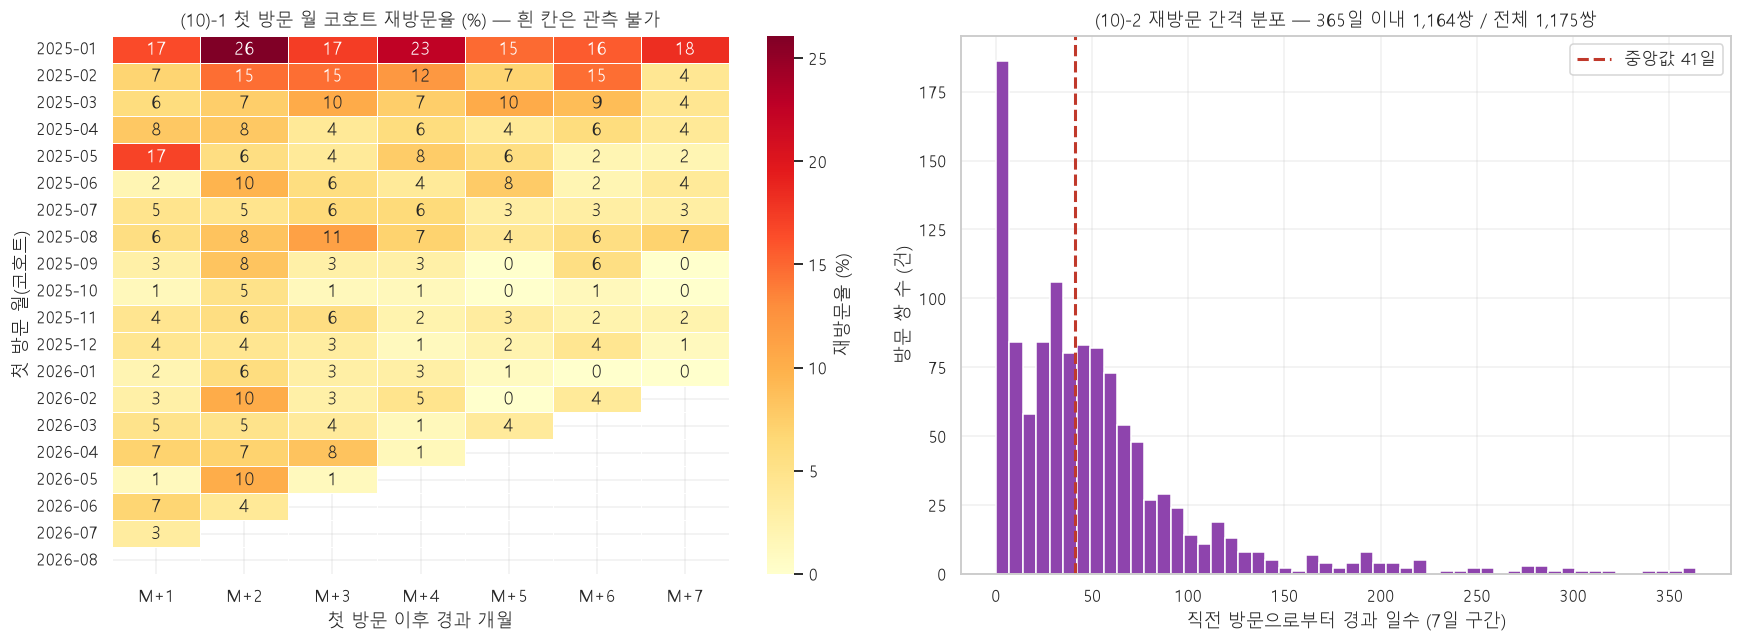

In [45]:
# -- (10) 그래프: 코호트 히트맵 + 간격 히스토그램 --
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(_coh, annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0],
            linewidths=.5, linecolor="white", cbar_kws={"label": "재방문율 (%)"},
            mask=_coh.isna(), vmin=0)
axes[0].set_title("(10)-1 첫 방문 월 코호트 재방문율 (%) — 흰 칸은 관측 불가")
axes[0].set_xlabel("첫 방문 이후 경과 개월"); axes[0].set_ylabel("첫 방문 월(코호트)")

axes[1].hist(_gap[_gap <= 365], bins=np.arange(0, 370, 7), color="#8e44ad", edgecolor="white")
axes[1].axvline(_med, color="#c0392b", ls="--", lw=2, label=f"중앙값 {_med:.0f}일")
axes[1].set_title(f"(10)-2 재방문 간격 분포 — 365일 이내 {int((_gap<=365).sum()):,}쌍 / 전체 {len(PAIRS):,}쌍")
axes[1].set_xlabel("직전 방문으로부터 경과 일수 (7일 구간)"); axes[1].set_ylabel("방문 쌍 수 (건)")
axes[1].legend()
plt.tight_layout(); plt.show()

---
# ⑪ 디자이너 구조

**무엇을 봤나** — 누가 무슨 시술을 하는지, 실제로 몇 시간 일하는지, 손님이 같은 디자이너를 다시 고르는지.

**정의**
* 시술 구성비는 **라인 기준과 대표시술 기준을 둘 다** 낸다(어느 쪽으로 대조하든 맞출 수 있게).
* 가동 시간은 §0-4의 **가정 소요시간**으로 환산한다. 실측이 아니다.
  - **주 지표(라인 기준)**: 한 예약의 모든 시술 라인 소요시간을 더한다. 탈색+염색이면 3.5h + 70m.
  - **보조 지표(대표시술 기준)**: 대표 시술 하나의 소요시간만 센다.
  - 클리닉·스타일링·기타·확인필요는 소요시간 0으로 두었으므로 가동시간에 기여하지 않는다.
* 근무일 수 = **2026년 이용완료 건**의 `use_dt` 고유 날짜 수(디자이너별).
* 가동률 = 하루 평균 가동시간 ÷ **10시간**(영업 10~20시).
* 같은 디자이너 재선택률 = ④에서 만든 인접 방문 쌍에서 `직전 디자이너 == 다음 디자이너` 비율.

In [46]:
# -- (11)-1 디자이너별 시술 구성비 --
_ldone2 = LX[LX.status == "이용완료"]
_dl = pd.crosstab(_ldone2.designer, _ldone2.category)
_dl = _dl[[c for c in PRIORITY if c in _dl.columns]]
_dl_pct = _dl.div(_dl.sum(axis=1), axis=0) * 100
_dl_pct["라인수"] = _dl.sum(axis=1)
_dl_pct = _dl_pct.sort_values("라인수", ascending=False)
tbl(_dl_pct.round(2), "(11)-1a 디자이너별 시술 구성비 (%) — ★라인 기준★ (완료 건)")

_dr = pd.crosstab(DONE.dropna(subset=["rep_cat"]).designer, DONE.dropna(subset=["rep_cat"]).rep_cat)
_dr = _dr[[c for c in PRIORITY if c in _dr.columns]]
_dr_pct = _dr.div(_dr.sum(axis=1), axis=0) * 100
_dr_pct["예약수"] = _dr.sum(axis=1)
_dr_pct = _dr_pct.reindex(_dl_pct.index)
tbl(_dr_pct.round(2), "(11)-1b 디자이너별 시술 구성비 (%) — 대표시술(예약) 기준 (완료 건)")
for d in _dr_pct.index:
    if "탈색" in _dr_pct.columns and pd.notna(_dr_pct.loc[d, "탈색"]):
        rec(f"디자이너 탈색 비중(대표시술) · {d}", f"{_dr_pct.loc[d, '탈색']:.2f}%",
            "완료 예약 대표시술 중 탈색 비율")

**(11)-1a 디자이너별 시술 구성비 (%) — ★라인 기준★ (완료 건)**

category,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,라인수
designer,,,,,,,,,
가온 대표원장,28.43,5.16,17.82,8.64,37.98,0.70,0.0,1.28,2733
나래 디자이너,47.96,0.97,7.88,2.65,39.91,0.18,0.0,0.44,1130
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,31.07,3.39,12.53,10.70,38.90,1.31,0.0,2.09,383
다솜 디자이너,89.83,0.85,5.08,3.39,0.00,0.85,0.0,0.00,118
라온 디자이너,39.56,7.69,24.18,25.27,0.00,1.10,1.1,1.10,91
헤어살롱 본점 (구)헤어공방 미지정전용예약,27.91,11.63,37.21,4.65,9.30,2.33,0.0,6.98,43
마루 디자이너,96.97,0.00,0.00,0.00,0.00,3.03,0.0,0.00,33


**(11)-1b 디자이너별 시술 구성비 (%) — 대표시술(예약) 기준 (완료 건)**

rep_cat,탈색,펌,염색,컷,클리닉,스타일링,기타,확인필요,예약수
designer,,,,,,,,,
가온 대표원장,47.85,8.48,29.51,10.85,1.68,0.69,0.00,0.94,1603
나래 디자이너,83.54,1.40,13.20,0.78,0.78,0.00,0.00,0.31,644
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,54.13,5.96,21.10,11.47,4.13,1.38,0.00,1.83,218
다솜 디자이너,93.81,0.88,4.42,0.00,0.00,0.88,0.00,0.00,113
라온 디자이너,41.86,8.14,25.58,22.09,0.00,1.16,1.16,0.00,86
헤어살롱 본점 (구)헤어공방 미지정전용예약,32.43,13.51,43.24,2.70,0.00,2.70,0.00,5.41,37
마루 디자이너,96.77,0.00,0.00,0.00,0.00,3.23,0.00,0.00,31


In [47]:
# -- (11)-2 2026년 가동 시간 --
BIZ_HOURS_PER_DAY = 10.0
YEAR = 2026

_res_dur_line = LX.groupby("예약번호").dur_h.sum().rename("dur_line")
DONE["dur_line"] = DONE.예약번호.map(_res_dur_line).fillna(0.0)
DONE["dur_rep"]  = DONE.rep_cat.map(DUR_H).fillna(0.0)

_y = DONE[DONE.use_dt.dt.year == YEAR].copy()
_y["date"] = _y.use_dt.dt.normalize()

_daily_d = _y.groupby(["designer", "date"]).agg(일가동_라인=("dur_line", "sum"),
                                                 일가동_대표=("dur_rep", "sum"),
                                                 건수=("예약번호", "size"))
_util = _daily_d.groupby("designer").agg(
    근무일수=("일가동_라인", "size"),
    총가동시간_라인=("일가동_라인", "sum"),
    총가동시간_대표=("일가동_대표", "sum"),
    완료건수=("건수", "sum"),
)
_util["하루평균가동_라인"] = _util.총가동시간_라인 / _util.근무일수
_util["하루평균가동_대표"] = _util.총가동시간_대표 / _util.근무일수
_util["가동률_라인(%)"] = _util.하루평균가동_라인 / BIZ_HOURS_PER_DAY * 100
_util["가동률_대표(%)"] = _util.하루평균가동_대표 / BIZ_HOURS_PER_DAY * 100
_util["8시간 초과일수"]  = _daily_d.groupby("designer").일가동_라인.apply(lambda s: int((s > 8).sum()))
_util["8시간 초과 비율(%)"] = _util["8시간 초과일수"] / _util.근무일수 * 100
_util = _util.sort_values("총가동시간_라인", ascending=False)
tbl(_util.round(2), f"(11)-2 {YEAR}년 디자이너별 가동 — 소요시간 가정값 기반 (10시간 영업 기준)")
print(f"{YEAR}년 완료 건 {len(_y):,}건 · 대상 기간 {_y.use_dt.min():%Y-%m-%d} ~ {_y.use_dt.max():%Y-%m-%d}")
print("주의: 이 숫자는 전적으로 §0-4 소요시간 가정(탈색3.5h/펌2.5h/염색70m/컷40m)에 의존한다.")
for d in _util.index:
    rec(f"디자이너 가동률(2026, 라인기준) · {d}", f"{_util.loc[d, '가동률_라인(%)']:.2f}%",
        f"{YEAR} 완료건 라인 소요시간 합 / 근무일수 / 10h")

**(11)-2 2026년 디자이너별 가동 — 소요시간 가정값 기반 (10시간 영업 기준)**

,근무일수,총가동시간_라인,총가동시간_대표,완료건수,하루평균가동_라인,하루평균가동_대표,가동률_라인(%),가동률_대표(%),8시간 초과일수,8시간 초과 비율(%)
designer,,,,,,,,,,
가온 대표원장,219,1715.33,1673.17,662,7.83,7.64,78.33,76.40,96,43.84
나래 디자이너,140,977.33,965.17,306,6.98,6.89,69.81,68.94,44,31.43
다솜 디자이너,83,380.67,376.83,112,4.59,4.54,45.86,45.40,2,2.41
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,66,215.33,208.50,81,3.26,3.16,32.63,31.59,1,1.52
마루 디자이너,27,112.00,105.00,31,4.15,3.89,41.48,38.89,2,7.41
라온 디자이너,11,24.17,23.50,12,2.20,2.14,21.97,21.36,0,0.00


2026년 완료 건 1,204건 · 대상 기간 2026-01-01 ~ 2026-08-22
주의: 이 숫자는 전적으로 §0-4 소요시간 가정(탈색3.5h/펌2.5h/염색70m/컷40m)에 의존한다.


In [48]:
# -- (11)-3 완료 건수와 객단가 (전체 기간) --
_dstat = (DONE.groupby("designer")
              .agg(완료건수=("예약번호", "size"),
                   객단가중앙값=("paid", "median"),
                   객단가평균=("paid", "mean"),
                   완료매출=("paid", "sum")))
_dstat["전체예약수"] = R.groupby("designer").size()
_dstat["취소율(%)"]  = R.groupby("designer").status.apply(lambda s: (s == "취소").mean() * 100)
_dstat["매출비중(%)"] = _dstat.완료매출 / DONE.paid.sum() * 100
_dstat = _dstat.sort_values("완료건수", ascending=False)
tbl(_dstat.round(2), "(11)-3 디자이너별 완료 건수 · 객단가 · 취소율 (전체 기간)")
for d in _dstat.index:
    rec(f"디자이너 객단가 중앙값 · {d}", won(_dstat.loc[d, "객단가중앙값"]) + "원",
        "완료 건 designer별 paid 중앙값")
    rec(f"디자이너 완료 건수 · {d}", f"{int(_dstat.loc[d, '완료건수']):,}건", "완료 건 designer별 건수")

**(11)-3 디자이너별 완료 건수 · 객단가 · 취소율 (전체 기간)**

,완료건수,객단가중앙값,객단가평균,완료매출,전체예약수,취소율(%),매출비중(%)
designer,,,,,,,
가온 대표원장,1603,100000.0,106299.53,170398150,2529,36.46,55.15
나래 디자이너,644,145000.0,131177.02,84478000,958,32.78,27.34
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,218,100000.0,105286.70,22952500,413,46.97,7.43
다솜 디자이너,113,150000.0,143389.38,16203000,150,23.33,5.24
라온 디자이너,86,87000.0,80732.56,6943000,127,32.28,2.25
헤어살롱 본점 (구)헤어공방 미지정전용예약,37,58000.0,87621.62,3242000,55,32.73,1.05
마루 디자이너,31,150000.0,153516.13,4759000,48,35.42,1.54


In [49]:
# -- (11)-4 재방문 시 같은 디자이너 선택률 --
PAIRS["same_designer"] = PAIRS.designer == PAIRS.prev_designer
_overall_same = PAIRS.same_designer.mean()
_ds = (PAIRS.groupby("prev_designer")
            .agg(전이쌍=("same_designer", "size"), 유지=("same_designer", "sum")))
_ds["유지율(%)"] = _ds.유지 / _ds.전이쌍 * 100
_ds = _ds.sort_values("전이쌍", ascending=False)
tbl(_ds.round(2), "(11)-4 직전 디자이너별 — 다음 방문에서 같은 디자이너를 고른 비율")
print(f"전체 디자이너 유지율 = {_overall_same*100:.2f}%  ({int(PAIRS.same_designer.sum()):,}/{len(PAIRS):,}쌍)")
rec("디자이너 유지율 (전체)", pct(_overall_same), "완료 인접 방문쌍 중 designer 동일 비율")
for d in _ds.index:
    rec(f"디자이너 유지율 · {d}", f"{_ds.loc[d, '유지율(%)']:.2f}%",
        "직전 방문이 해당 디자이너인 쌍 중 다음도 동일")

**(11)-4 직전 디자이너별 — 다음 방문에서 같은 디자이너를 고른 비율**

,전이쌍,유지,유지율(%)
prev_designer,,,
가온 대표원장,738,660,89.43
나래 디자이너,250,212,84.80
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,93,34,36.56
라온 디자이너,45,18,40.00
다솜 디자이너,22,14,63.64
헤어살롱 본점 (구)헤어공방 미지정전용예약,21,7,33.33
마루 디자이너,6,2,33.33


전체 디자이너 유지율 = 80.60%  (947/1,175쌍)


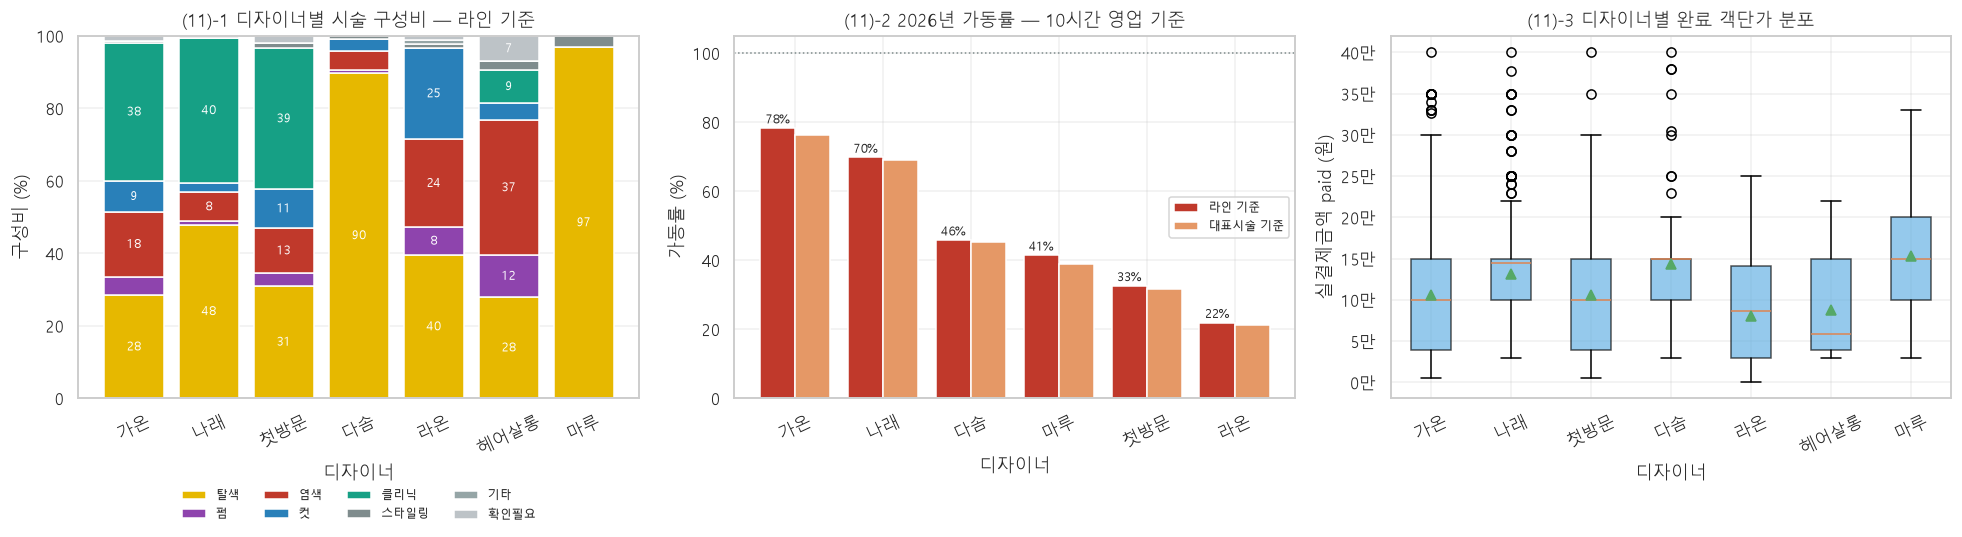

In [50]:
# -- (11) 그래프 --
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

_st = _dl_pct.drop(columns="라인수")
_bottom = np.zeros(len(_st))
_labels = [d.split()[0] for d in _st.index]
for c in _st.columns:
    axes[0].bar(_labels, _st[c], bottom=_bottom, label=c, color=_colors.get(c, None))
    for i, v in enumerate(_st[c]):
        if v >= 6:
            axes[0].text(i, _bottom[i] + v/2, f"{v:.0f}", ha="center", va="center",
                         fontsize=8, color="white")
    _bottom += _st[c].values
axes[0].set_title("(11)-1 디자이너별 시술 구성비 — 라인 기준")
axes[0].set_xlabel("디자이너"); axes[0].set_ylabel("구성비 (%)"); axes[0].set_ylim(0, 100)
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)

_u = _util.sort_values("가동률_라인(%)", ascending=False)
_ul = [d.split()[0] for d in _u.index]
_xx = np.arange(len(_u))
axes[1].bar(_xx - 0.2, _u["가동률_라인(%)"], 0.4, color="#c0392b", label="라인 기준")
axes[1].bar(_xx + 0.2, _u["가동률_대표(%)"], 0.4, color="#e59866", label="대표시술 기준")
for i, v in enumerate(_u["가동률_라인(%)"]):
    axes[1].annotate(f"{v:.0f}%", (i - 0.2, v), textcoords="offset points", xytext=(0, 3),
                     ha="center", fontsize=8)
axes[1].axhline(100, color="#7f8c8d", ls=":", lw=1)
axes[1].set_xticks(_xx); axes[1].set_xticklabels(_ul, rotation=25)
axes[1].set_title(f"(11)-2 {YEAR}년 가동률 — 10시간 영업 기준")
axes[1].set_xlabel("디자이너"); axes[1].set_ylabel("가동률 (%)"); axes[1].legend(fontsize=8)

_dorder = _dstat.index.tolist()
_bd = [DONE.loc[DONE.designer == d, "paid"].values for d in _dorder]
bp = axes[2].boxplot(_bd, tick_labels=[d.split()[0] for d in _dorder],
                     showmeans=True, patch_artist=True)
for patch in bp["boxes"]:
    patch.set_facecolor("#5dade2"); patch.set_alpha(.65)
axes[2].set_title("(11)-3 디자이너별 완료 객단가 분포")
axes[2].set_xlabel("디자이너"); axes[2].set_ylabel("실결제금액 paid (원)")
axes[2].tick_params(axis="x", rotation=25)
axes[2].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{v/10000:.0f}만"))
plt.tight_layout(); plt.show()

---
# ⑪-B 관측 소요시간 — 가정을 데이터로 대조한다

⑪까지의 가동률은 §0-4 의 **가정 A**(탈색 3.5h / 펌 2.5h / 염색 70m / 컷 40m)에 전적으로 의존한다.
여기서는 그 가정을 실제 관측값과 나란히 놓는다. **⑪의 숫자는 하나도 바뀌지 않는다.**

**관측 소요시간이란** — `done_dt - use_dt`, 즉 *예약 시작 → 완료처리 클릭* 까지의 시간이다.
시술 종료 그 자체가 아니다. 완료 2,732건 중 **당일 처리된 945건(34.6%)** 에서만 관측된다.

**이 절에서 답하는 것 3가지**

| | 질문 | 쓰는 값 | 가정 필요? |
|---|---|---|---|
| ⑪-B1 | 가정 A는 얼마나 빗나갔나 | 관측 중앙값 | 없음 |
| **⑪-B2** | **합산 가동률이 왜 100%를 넘나** | **구간 합집합** | **없음 — 직접 측정** |
| ⑪-B2d | **그 점유율은 왜 낮게 나오나** | 하루 건수로 조건화 | 없음 |
| ⑪-B3 | 이 시술은 몇 시까지 시작할 수 있나 | 관측 중앙값 + 마감시각 | 없음 |

**⑪-B2 가 이 절의 핵심이다.** 소요시간 가정이 전혀 필요 없고, `use_dt`/`done_dt` 구간만 쓴다.

### 한계 — 결론을 읽기 전에 먼저 볼 것

* **34.6% 만 관측된다.** 나머지는 익일 오전 일괄 처리라 종료 시각을 알 수 없다.
* **절단 편향**: 시작 시각별 당일처리율이 10~13시 37~40% → 18시 21.8% → 19시 12.8%.
  늦게 시작해 늦게 끝난 건이 빠진다 → **관측값은 하한에 가깝다.**
* **연도 쏠림**: 2025년 28.7% vs 2026년 42.1%.
* 메뉴 37종 중 15종이 `n≤5`. 그래서 아래는 **`n≥10` 메뉴만** 쓴다.
* ⑪-B2 의 표본은 **가벼운 날 쪽으로 편향**돼 있다(전부 당일처리인 날 1.31건/일 vs 나머지 2.42건/일).
  ⑪-B2b 의 점유율을 그대로 읽으면 **정반대 방향으로 틀린다** — "절반이 비어 있다"로 읽히기 때문이다.
  ⑪-B2d 에서 하루 건수로 조건화해 보정하며, **보정값조차 하한**이다(k>=5 클리핑 + 절단 편향).


In [51]:
# -- (11-B)-1 가정 A vs 관측 대조 --
_rows = []
for c in PRIORITY:
    if c not in DUR_OBS_CAT:
        continue
    a, o = DUR_H[c], DUR_OBS_CAT[c]
    _rows.append({
        "대분류": c,
        "가정 A(h)": a,
        "관측 중앙값(h)": o,
        "p25~p75": f"{DUR_OBS_CAT_P25[c]:.2f} ~ {DUR_OBS_CAT_P75[c]:.2f}",
        "n": int(OBS_N_CAT[c]),
        "겹침없음 n": int(OBS_SOLO_N_CAT[c]),
        "겹침없음 중앙값(h)": OBS_SOLO_CAT[c],
        "가정A는 관측의(%)": (a / o * 100) if o > 0 else np.nan,
        "관측/가정A(배)": (o / a) if a > 0 else np.nan,
    })
OBS_CMP = pd.DataFrame(_rows).set_index("대분류")
tbl(OBS_CMP.round(2), "⑪-B1 가정 A vs 관측 소요시간 — 관측은 '예약 시작 → 완료처리' 중앙값")

# 가정 A가 0시간인 카테고리(클리닉·스타일링·확인필요)는 비율이 무의미하므로 제외한다.
_pos = OBS_CMP[OBS_CMP["가정 A(h)"] > 0].sort_values("가정A는 관측의(%)")
OBS_RATIO = OBS_CMP["관측/가정A(배)"].dropna().to_dict()
_lo, _hi = _pos["가정A는 관측의(%)"].min(), _pos["가정A는 관측의(%)"].max()

print(f"가정 A가 전 카테고리에서 일관되게 관측의 {_lo:.0f}~{_hi:.0f}% 다. "
      f"({' / '.join(f'{c} {v:.0f}%' for c, v in _pos['가정A는 관측의(%)'].items())})")
print(f"  한 카테고리만 어긋난 게 아니라 **네 개 전부 같은 방향으로 과소**다. "
      f"가정 A는 시술 시간을 {1/(_hi/100):.2f}~{1/(_lo/100):.2f}배 짧게 잡고 있다.")
print()
_zero = OBS_CMP[OBS_CMP["가정 A(h)"] == 0]
print(f"가정 A가 0h 로 둔 {len(_zero)}종은 비율을 낼 수 없다. 관측값만 적는다: "
      + " / ".join(f"{c} {v:.2f}h(n={int(OBS_N_CAT[c])})" for c, v in _zero["관측 중앙값(h)"].items()))
print("  → 클리닉·스타일링·확인필요를 0h 로 둔 것도 과소지만, 건수가 적어 가동률에 미치는 영향은 작다.")
print()
print("겹침없음 열은 '그날 그 디자이너의 완료 건이 1건뿐' 인 날만 따로 집계한 것이다.")
print("병행 시술이 물리적으로 불가능하므로, 이 값이 본 중앙값과 비슷하면 관측이 병행에 오염되지 않았다는 뜻이다.")
_ok = OBS_CMP[(OBS_CMP["겹침없음 n"] >= 10)]
for c, r in _ok.iterrows():
    print(f"   {c:<5s} 전체 {r['관측 중앙값(h)']:.2f}h(n={int(r['n'])}) vs 겹침없음 {r['겹침없음 중앙값(h)']:.2f}h(n={int(r['겹침없음 n'])}) "
          f"→ 차이 {r['겹침없음 중앙값(h)']-r['관측 중앙값(h)']:+.2f}h")


**⑪-B1 가정 A vs 관측 소요시간 — 관측은 '예약 시작 → 완료처리' 중앙값**

,가정 A(h),관측 중앙값(h),p25~p75,n,겹침없음 n,겹침없음 중앙값(h),가정A는 관측의(%),관측/가정A(배)
대분류,,,,,,,,
탈색,3.50,5.40,4.23 ~ 6.75,701,151,4.88,64.81,1.54
펌,2.50,3.76,3.09 ~ 4.33,20,7,3.81,66.49,1.50
염색,1.17,2.07,1.70 ~ 2.90,171,32,2.07,56.36,1.77
컷,0.67,1.05,0.56 ~ 1.83,41,10,0.54,63.49,1.58
클리닉,0.00,0.74,0.58 ~ 1.18,4,1,0.70,0.00,
스타일링,0.00,0.68,0.58 ~ 0.80,4,3,0.67,0.00,
확인필요,0.00,1.31,0.95 ~ 1.46,4,1,1.57,0.00,


가정 A가 전 카테고리에서 일관되게 관측의 56~66% 다. (염색 56% / 컷 63% / 탈색 65% / 펌 66%)
  한 카테고리만 어긋난 게 아니라 **네 개 전부 같은 방향으로 과소**다. 가정 A는 시술 시간을 1.50~1.77배 짧게 잡고 있다.

가정 A가 0h 로 둔 3종은 비율을 낼 수 없다. 관측값만 적는다: 클리닉 0.74h(n=4) / 스타일링 0.68h(n=4) / 확인필요 1.31h(n=4)
  → 클리닉·스타일링·확인필요를 0h 로 둔 것도 과소지만, 건수가 적어 가동률에 미치는 영향은 작다.

겹침없음 열은 '그날 그 디자이너의 완료 건이 1건뿐' 인 날만 따로 집계한 것이다.
병행 시술이 물리적으로 불가능하므로, 이 값이 본 중앙값과 비슷하면 관측이 병행에 오염되지 않았다는 뜻이다.
   탈색    전체 5.40h(n=701) vs 겹침없음 4.88h(n=151) → 차이 -0.52h
   염색    전체 2.07h(n=171) vs 겹침없음 2.07h(n=32) → 차이 +0.00h
   컷     전체 1.05h(n=41) vs 겹침없음 0.54h(n=10) → 차이 -0.51h


In [52]:
# -- (11-B)-2 ★ 구간 합집합 점유율 — 소요시간 가정이 필요 없는 직접 측정 --
# 합산h : 손님별 (done_dt - use_dt) 를 그냥 더한 값.  겹치는 구간을 두 번 센다.
# 점유h : 같은 구간들의 **합집합** 길이.  겹치면 한 번만 센다. = 실제로 붙잡힌 시간.
# 병행배수 = 합산h / 점유h.  1.0 이면 병행 없음, 2.0 이면 평균 2명을 동시에 본 것.
_A = DONE.copy()
_A["date"]   = _A.use_dt.dt.normalize()
_A["gap_h"]  = (_A.done_dt - _A.use_dt).dt.total_seconds() / 3600
_A["obs_ok"] = (_A.done_dt.dt.normalize() == _A["date"]) & (_A.gap_h > 0)

# 대상은 **그 디자이너-일의 완료 건이 전부 당일처리인 날** 뿐이다.
# 한 건이라도 익일 처리면 그날의 구간에 구멍이 생겨 합집합을 잴 수 없다.
_full = _A.groupby(["designer", "date"]).obs_ok.all()
_A["full_day"] = pd.MultiIndex.from_frame(_A[["designer", "date"]]).map(_full).astype(bool)

def _union_h(iv):
    """[(start, end), ...] 의 합집합 길이(시간). 정렬 후 병합."""
    iv = sorted(iv)
    tot, s, e = 0.0, iv[0][0], iv[0][1]
    for a, b in iv[1:]:
        if a > e:
            tot += (e - s).total_seconds(); s, e = a, b
        else:
            e = max(e, b)
    return (tot + (e - s).total_seconds()) / 3600

_rows = []
for (d, dt_), g in _A[_A.full_day].groupby(["designer", "date"]):
    _rows.append({"designer": d, "date": dt_, "건수": len(g),
                  "합산h": float(g.gap_h.sum()),
                  "점유h": _union_h(list(zip(g.use_dt, g.done_dt)))})
DAY_UNION = pd.DataFrame(_rows)
DAY_UNION["병행배수"] = DAY_UNION.합산h / DAY_UNION.점유h

print(f"완전관측 디자이너-일 {len(DAY_UNION):,}일 · 완료 {int(DAY_UNION.건수.sum()):,}건 "
      f"({DAY_UNION.date.min():%Y-%m-%d} ~ {DAY_UNION.date.max():%Y-%m-%d})")
print()

# ── (1) 하루 예약 수별 ────────────────────────────────────────────────────────
_bins = DAY_UNION.copy()
_bins["구간"] = np.where(_bins.건수 >= 6, "6건+", _bins.건수.astype(str) + "건")
_ord = [f"{i}건" for i in range(1, 6)] + ["6건+"]
BY_N = (_bins.groupby("구간")
             .agg(일수=("건수", "size"), 합산h중앙=("합산h", "median"),
                  점유h중앙=("점유h", "median"), 병행배수중앙=("병행배수", "median"))
             .reindex([o for o in _ord if o in set(_bins.구간)]))
tbl(BY_N.round(2), "⑪-B2a 하루 예약 수별 — 합산h는 계속 커지는데 점유h는 9시간대에서 천장을 친다")
_m2 = BY_N[BY_N.index != "1건"]          # 1건인 날은 정의상 병행배수 1.00 이라 비교에서 뺀다
PARALLEL_MED = float(DAY_UNION[DAY_UNION.건수 >= 2].병행배수.median())
print(f"하루 2건 이상인 날의 병행배수 중앙값 = {PARALLEL_MED:.2f}배")
print()

# ── (2) 디자이너별 — 합산 기준 vs 점유 기준 ───────────────────────────────────
UTIL_CMP = (DAY_UNION.groupby("designer")
                     .agg(일수=("건수", "size"), 하루평균건수=("건수", "mean"),
                          합산h평균=("합산h", "mean"), 점유h평균=("점유h", "mean")))
UTIL_CMP["합산 기준 가동률(%)"] = UTIL_CMP.합산h평균 / 10 * 100
UTIL_CMP["점유율(완전관측 표본, 편향 있음)(%)"] = UTIL_CMP.점유h평균 / 10 * 100
UTIL_CMP["병행배수"] = UTIL_CMP.합산h평균 / UTIL_CMP.점유h평균
UTIL_CMP = UTIL_CMP.sort_values("점유율(완전관측 표본, 편향 있음)(%)", ascending=False)
UTIL_UNION = UTIL_CMP["점유율(완전관측 표본, 편향 있음)(%)"]   # ⚠️ 편향 있음. 보정은 ⑪-B2d
tbl(UTIL_CMP.round(2), "⑪-B2b 디자이너별 — 같은 날짜·같은 데이터에서 합산 기준과 점유 기준 (10시간 영업)")
print("주의: 이 표의 모집단은 '완전관측 디자이너-일' 이다. ⑪-2 의 2026년 전체 가동률과 모집단이 다르므로")
print("      78.33% 같은 숫자와 직접 비교하지 말 것. 여기서 볼 것은 **같은 날에서 두 지표가 벌어지는 폭**이다.")
print("⚠️ 이 표본은 하루 1.3건짜리 가벼운 날만 모은 것이라 점유율이 심하게 낮게 나온다.")
print("   이 값을 '절반이 비어 있다'로 읽으면 안 된다. 편향 보정은 바로 아래 ⑪-B2d 에서 한다.")
print()

# ── (3) 선택 편향의 크기 ──────────────────────────────────────────────────────
_dayn = _A.groupby(["designer", "date"]).agg(n=("예약번호", "size"), full=("full_day", "first"))
BIAS = _dayn.groupby("full").agg(일수=("n", "size"), 하루평균건수=("n", "mean"), 총건수=("n", "sum"))
BIAS.index = BIAS.index.map({True: "전부 당일처리 (관측 대상)", False: "일부라도 익일처리 (제외)"})
tbl(BIAS.round(2), "⑪-B2c 선택 편향 — 관측 대상 날이 원래 한가한 날이다")
_b1 = float(BIAS.loc["전부 당일처리 (관측 대상)", "하루평균건수"])
_b2 = float(BIAS.loc["일부라도 익일처리 (제외)", "하루평균건수"])

# ── (4) 반례 재현 — 관측값을 라인 합산하면 무슨 일이 벌어지나 ────────────────
#     이 계산은 **하지 말라는 것**이다. 주장만 하지 않고 숫자로 보여둔다.
_lo = LX.copy()
_lo["d"] = _lo.menu.map(DUR_OBS_MENU)
_lo["d"] = _lo.d.fillna(_lo.category.map(DUR_OBS_CAT))
_lo.loc[_lo.is_free == 1, "d"] = 0.0                      # 무료 클리닉은 붙어서 나가므로 0
_obs_res = _lo.groupby("예약번호").d.sum()
_y26 = DONE[DONE.use_dt.dt.year == 2026].copy()
_y26["date"] = _y26.use_dt.dt.normalize()
_y26["_d"]   = _y26.예약번호.map(_obs_res).fillna(0.0)
_bu = _y26.groupby(["designer", "date"])._d.sum().groupby("designer").agg(["size", "sum"])
BAD_UTIL = (_bu["sum"] / _bu["size"] / 10 * 100).sort_values(ascending=False)

print("=" * 96)
print("합산 기준 가동률이 100%를 넘는 것은 계산 오류가 아니라 **지표 선택 오류**다.")
print("=" * 96)
print("반례 — 관측 소요시간을 라인별로 더해 2026년 가동률을 내면 이렇게 된다:")
for _d, _v in BAD_UTIL.head(3).items():
    print(f"     {_d:<12s} {_v:6.1f}%   (⑪-2 가정 A 기준으로는 {_util.loc[_d, '가동률_라인(%)']:.2f}%)")
print(f"   하루 10시간 영업에서 {BAD_UTIL.iloc[0]/10:.1f}시간을 일했다는 뜻이 되므로 물리적으로 불가능하다.")
print("   값이 틀린 게 아니라, 겹치는 구간을 두 번 세는 지표를 쓴 것이다.")
print()
print("탈색은 방치 시간이 길어 그 사이 다른 손님을 병행한다. 그래서 손님별 소요시간을 그냥 더하면")
print(f"하루 길이를 넘는다({BY_N.index[-1]}인 날 합산 {BY_N.합산h중앙.iloc[-1]:.2f}h). 실제 점유시간은")
print(f"합집합으로 재야 하고, 2건 이상인 날의 점유h 중앙은 "
      f"{_m2.점유h중앙.min():.2f}~{_m2.점유h중앙.max():.2f}h 구간에서 천장을 친다.")
print(f"  → {_m2.index[0]} → {_m2.index[-1]} 로 갈 때 합산h 중앙은 "
      f"{_m2.합산h중앙.iloc[0]:.2f} → {_m2.합산h중앙.iloc[-1]:.2f}h ({_m2.합산h중앙.iloc[-1]/_m2.합산h중앙.iloc[0]:.2f}배) 인데")
print(f"     점유h 중앙은 {_m2.점유h중앙.iloc[0]:.2f} → {_m2.점유h중앙.iloc[-1]:.2f}h "
      f"({_m2.점유h중앙.iloc[-1]/_m2.점유h중앙.iloc[0]:.2f}배) 로만 움직인다. 나머지는 전부 병행배수로 간다"
      f" ({_m2.병행배수중앙.iloc[0]:.2f} → {_m2.병행배수중앙.iloc[-1]:.2f}배).")
print(f"  ⚠️ 3건 이상인 날은 표본이 얇다 ({', '.join(f'{k} {int(v)}일' for k, v in _m2.일수.items())}).")
print("     방향은 분명하지만 배수 값 자체를 확정하려면 표본이 더 필요하다.")
print()
print("따라서 **캐파 판정에는 합산이 아니라 합집합을 써야 한다.**")
print(f"다만 이 표본은 가벼운 날 쪽으로 편향돼 있다 — 전부 당일처리인 날 {_b1:.2f}건/일 vs 나머지 {_b2:.2f}건/일.")
print(f"바쁜 날의 실제 점유율은 위 표보다 높다. 위 값은 **하한**으로 읽을 것.")


완전관측 디자이너-일 270일 · 완료 355건 (2025-01-03 ~ 2026-08-21)



**⑪-B2a 하루 예약 수별 — 합산h는 계속 커지는데 점유h는 9시간대에서 천장을 친다**

,일수,합산h중앙,점유h중앙,병행배수중앙
구간,,,,
1건,205,4.26,4.26,1.00
2건,51,9.54,6.97,1.39
3건,9,14.10,9.27,1.74
4건,4,26.03,9.98,2.57
5건,1,26.63,9.16,2.91


하루 2건 이상인 날의 병행배수 중앙값 = 1.43배



**⑪-B2b 디자이너별 — 같은 날짜·같은 데이터에서 합산 기준과 점유 기준 (10시간 영업)**

,일수,하루평균건수,합산h평균,점유h평균,합산 기준 가동률(%),"점유율(완전관측 표본, 편향 있음)(%)",병행배수
designer,,,,,,,
나래 디자이너,65,1.34,7.63,6.22,76.26,62.17,1.23
마루 디자이너,17,1.06,5.47,5.26,54.66,52.63,1.04
가온 대표원장,70,1.64,6.92,4.95,69.24,49.45,1.40
다솜 디자이너,51,1.24,5.42,4.76,54.22,47.60,1.14
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,42,1.02,3.77,3.73,37.65,37.32,1.01
라온 디자이너,18,1.22,3.69,3.44,36.92,34.44,1.07
헤어살롱 본점 (구)헤어공방 미지정전용예약,7,1.00,2.17,2.17,21.71,21.71,1.00


주의: 이 표의 모집단은 '완전관측 디자이너-일' 이다. ⑪-2 의 2026년 전체 가동률과 모집단이 다르므로
      78.33% 같은 숫자와 직접 비교하지 말 것. 여기서 볼 것은 **같은 날에서 두 지표가 벌어지는 폭**이다.
⚠️ 이 표본은 하루 1.3건짜리 가벼운 날만 모은 것이라 점유율이 심하게 낮게 나온다.
   이 값을 '절반이 비어 있다'로 읽으면 안 된다. 편향 보정은 바로 아래 ⑪-B2d 에서 한다.



**⑪-B2c 선택 편향 — 관측 대상 날이 원래 한가한 날이다**

,일수,하루평균건수,총건수
full,,,
일부라도 익일처리 (제외),982,2.42,2377
전부 당일처리 (관측 대상),270,1.31,355


합산 기준 가동률이 100%를 넘는 것은 계산 오류가 아니라 **지표 선택 오류**다.
반례 — 관측 소요시간을 라인별로 더해 2026년 가동률을 내면 이렇게 된다:
     가온 대표원장       128.4%   (⑪-2 가정 A 기준으로는 78.33%)
     나래 디자이너       111.6%   (⑪-2 가정 A 기준으로는 69.81%)
     다솜 디자이너        72.3%   (⑪-2 가정 A 기준으로는 45.86%)
   하루 10시간 영업에서 12.8시간을 일했다는 뜻이 되므로 물리적으로 불가능하다.
   값이 틀린 게 아니라, 겹치는 구간을 두 번 세는 지표를 쓴 것이다.

탈색은 방치 시간이 길어 그 사이 다른 손님을 병행한다. 그래서 손님별 소요시간을 그냥 더하면
하루 길이를 넘는다(5건인 날 합산 26.63h). 실제 점유시간은
합집합으로 재야 하고, 2건 이상인 날의 점유h 중앙은 6.97~9.98h 구간에서 천장을 친다.
  → 2건 → 5건 로 갈 때 합산h 중앙은 9.54 → 26.63h (2.79배) 인데
     점유h 중앙은 6.97 → 9.16h (1.31배) 로만 움직인다. 나머지는 전부 병행배수로 간다 (1.39 → 2.91배).
  ⚠️ 3건 이상인 날은 표본이 얇다 (2건 51일, 3건 9일, 4건 4일, 5건 1일).
     방향은 분명하지만 배수 값 자체를 확정하려면 표본이 더 필요하다.

따라서 **캐파 판정에는 합산이 아니라 합집합을 써야 한다.**
다만 이 표본은 가벼운 날 쪽으로 편향돼 있다 — 전부 당일처리인 날 1.31건/일 vs 나머지 2.42건/일.
바쁜 날의 실제 점유율은 위 표보다 높다. 위 값은 **하한**으로 읽을 것.


In [53]:
# -- (11-B)-2d 편향 보정 — 하루 건수로 조건화한 점유율 --
# ⑪-B2b 의 점유율은 '완전관측 디자이너-일' 에서만 잰 값이라 심하게 낮다.
# 그 표본은 하루 1.31건인데 전체 평균은 2.42건, 가온는 2.93건이다.
# 편향의 원인은 단 하나 — '완전관측 여부' 가 하루 건수와 상관있다는 것이다.
# 그러므로 **하루 건수로 조건화하면** 그 상관이 끊긴다.
#
#     보정 점유h = Σ_k  P(k) x curve[min(k, KMAX)]
#       curve[k] : 완전관측 디자이너-일 중 하루 k건인 날의 점유h 중앙값 (⑪-B2a 곡선)
#       P(k)     : 그 디자이너의 **실제** 하루 건수 분포 (완전관측 여부와 무관, 완료 전체)
#
# ⚠️ k >= KMAX 는 표본이 없어 curve[KMAX] 로 클리핑한다. 6건 이상인 날의 실제 점유는
#    그보다 클 것이므로 이 클리핑은 **과소추정 방향**이다. 즉 보정값도 여전히 하한이다.
OCC_KMAX = 5
DAY_UNION["k"] = DAY_UNION.건수.clip(upper=OCC_KMAX)
OCC_CURVE = DAY_UNION.groupby("k").점유h.median()
_cv = pd.concat([DAY_UNION.groupby("k").size().rename("일수"),
                 OCC_CURVE.rename("점유h 중앙")], axis=1)
_cv.index.name = "하루 건수 k"
tbl(_cv.round(2), f"⑪-B2d-1 건수별 점유h 곡선 curve[k] — k>={OCC_KMAX} 는 {OCC_KMAX} 로 클리핑(과소 방향)")

# 실제 하루 건수 분포 — 완전관측 여부를 보지 않는다. 이게 보정의 핵심이다.
_dayn = (DONE.assign(date=DONE.use_dt.dt.normalize())
             .groupby(["designer", "date"]).size().rename("n").reset_index())
_dayn["k"] = _dayn.n.clip(upper=OCC_KMAX)
_P = _dayn.groupby(["designer", "k"]).size().unstack(fill_value=0)
_P = _P.div(_P.sum(axis=1), axis=0)
UTIL_ADJ = (_P * OCC_CURVE.reindex(_P.columns).values).sum(axis=1) / 10 * 100

OCC_CMP = pd.DataFrame({
    "근무일수": _dayn.groupby("designer").size(),
    "하루 평균 건수": _dayn.groupby("designer").n.mean(),
    "관측표본 하루건수": DAY_UNION.groupby("designer").건수.mean(),
    "점유율(완전관측 표본, 편향 있음)(%)": UTIL_UNION,
    "점유율(건수 조건화 보정)(%)": UTIL_ADJ,
})
OCC_CMP["보정폭(%p)"] = (OCC_CMP["점유율(건수 조건화 보정)(%)"]
                        - OCC_CMP["점유율(완전관측 표본, 편향 있음)(%)"])
OCC_CMP = OCC_CMP.sort_values("점유율(건수 조건화 보정)(%)", ascending=False)
tbl(OCC_CMP.round(2),
    "⑪-B2d-2 점유율 — 편향값과 보정값을 나란히. **두 값의 차이 자체가 편향의 크기다**")

print("보정폭이 큰 디자이너일수록 관측 표본이 그의 실제 근무일을 덜 대표한다는 뜻이다.")
for _d, _r in OCC_CMP.iterrows():
    print(f"   {_d[:20]:<22s} 실제 {_r['하루 평균 건수']:.2f}건/일 vs 관측표본 {_r['관측표본 하루건수']:.2f}건/일 "
          f"→ {_r['점유율(완전관측 표본, 편향 있음)(%)']:.1f}% → {_r['점유율(건수 조건화 보정)(%)']:.1f}% "
          f"({_r['보정폭(%p)']:+.1f}%p)")
print()

# ── 평균보다 분포가 중요하다 ──────────────────────────────────────────────────
_TOP = OCC_CMP["근무일수"].idxmax()                    # 근무일이 가장 많은 디자이너
_j   = _dayn[_dayn.designer == _TOP]
DIST = pd.concat([_j.n.value_counts().sort_index().rename("일수"),
                  (_j.n.value_counts(normalize=True).sort_index() * 100).rename("비중(%)")], axis=1)
DIST.index.name = "하루 완료 건수"
DIST["이 건수 이상(%)"]  = DIST["비중(%)"][::-1].cumsum()[::-1]
DIST["그날 점유h(curve)"] = [OCC_CURVE[min(int(k), OCC_KMAX)] for k in DIST.index]
DIST["그날 점유율(%)"]    = DIST["그날 점유h(curve)"] / 10 * 100
tbl(DIST.round(2), f"⑪-B2d-3 {_TOP} 하루 완료 건수 분포 (근무 {len(_j)}일) — 평균 하나로 요약하면 놓치는 것")

# ── 민감도 — curve 의 얇은 칸(k=3·4·5 가 각 9·4·1일)에 결과가 끌려다니는가 ──────
_c3p = float(DAY_UNION[DAY_UNION.건수 >= 3].점유h.median())     # k>=3 을 한 칸으로 묶음
_cA  = OCC_CURVE.copy()
for _k in [k for k in OCC_CURVE.index if k >= 3]:
    _cA[_k] = _c3p
_cB  = DAY_UNION.groupby("k").점유h.mean()                       # 중앙값 대신 평균
SENS = pd.DataFrame({
    "기본 (칸별 중앙값)": UTIL_ADJ,
    f"k>=3 통합 ({_c3p:.2f}h, n={int((DAY_UNION.건수>=3).sum())}일)":
        (_P * _cA.reindex(_P.columns).values).sum(axis=1) / 10 * 100,
    "평균 사용": (_P * _cB.reindex(_P.columns).values).sum(axis=1) / 10 * 100,
}).sort_values("기본 (칸별 중앙값)", ascending=False)
tbl(SENS.round(1), "⑪-B2d-4 민감도 — curve 를 어떻게 잡아도 보정값은 거의 안 움직인다")
print(f"세 방식의 최대 차이 {float((SENS.max(axis=1) - SENS.min(axis=1)).max()):.1f}%p. "
      f"보정 결과는 curve 의 얇은 칸에 좌우되지 않는다.")
print()

_ge4  = float((_j.n >= 4).mean() * 100)
_ge5  = float((_j.n >= 5).mean() * 100)
_o4o5 = [float(OCC_CURVE[k]) for k in (4, 5) if k in OCC_CURVE.index]
print("=" * 96)
print(f"{_TOP} 는 근무일의 {_ge4:.1f}% 가 하루 4건 이상이다. "
      f"k>=3 인 날의 점유 중앙은 {_c3p:.2f}시간 (n={int((DAY_UNION.건수>=3).sum())}일).")
print(f"즉 **3일에 1일은 영업시간 10시간의 {_c3p/10*100:.0f}% 안팎이 차 있다.**")
print(f"   (칸별로 보면 3건 {OCC_CURVE[3]:.2f}h / 4건 {OCC_CURVE[4]:.2f}h / 5건 {OCC_CURVE[5]:.2f}h 지만 "
      f"각 {int((DAY_UNION.건수==3).sum())}·{int((DAY_UNION.건수==4).sum())}·{int((DAY_UNION.건수==5).sum())}일이라 "
      f"칸별 값은 읽지 말 것. 묶은 {_c3p:.2f}h 를 쓴다.)")
print(f'"평균 {UTIL_ADJ[_TOP]:.1f}%" 보다 이 분포가 실제 운영 상황에 가깝다.')
print(f"(5건 이상도 {_ge5:.1f}% 다.)")
print("게다가 관측 소요시간 자체가 절단 편향으로 하한이므로, 실제 점유율은 이보다 높다.")
print("=" * 96)
print()
print(f"⚠️ ⑪-B2b 의 {UTIL_UNION[_TOP]:.1f}% 를 '{_TOP} 에게 절반이 비어 있다' 로 읽으면 정반대로 틀린다.")
print(f"   그 값은 하루 {OCC_CMP.loc[_TOP,'관측표본 하루건수']:.2f}건짜리 가벼운 날만 모은 표본에서 나왔다.")
print(f"   실제 건수 분포({OCC_CMP.loc[_TOP,'하루 평균 건수']:.2f}건/일)로 조건화하면 {UTIL_ADJ[_TOP]:.1f}% 이고, 그것도 하한이다.")


**⑪-B2d-1 건수별 점유h 곡선 curve[k] — k>=5 는 5 로 클리핑(과소 방향)**

,일수,점유h 중앙
하루 건수 k,,
1,205,4.26
2,51,6.97
3,9,9.27
4,4,9.98
5,1,9.16


**⑪-B2d-2 점유율 — 편향값과 보정값을 나란히. **두 값의 차이 자체가 편향의 크기다****

,근무일수,하루 평균 건수,관측표본 하루건수,"점유율(완전관측 표본, 편향 있음)(%)",점유율(건수 조건화 보정)(%),보정폭(%p)
designer,,,,,,
가온 대표원장,547,2.93,1.64,49.45,77.77,28.32
나래 디자이너,325,1.98,1.34,62.17,65.17,3.00
다솜 디자이너,84,1.35,1.24,47.60,51.64,4.04
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,170,1.28,1.02,37.32,49.78,12.46
라온 디자이너,69,1.25,1.22,34.44,48.83,14.40
헤어살롱 본점 (구)헤어공방 미지정전용예약,30,1.23,1.00,21.71,48.81,27.10
마루 디자이너,27,1.15,1.06,52.63,46.49,-6.14


보정폭이 큰 디자이너일수록 관측 표본이 그의 실제 근무일을 덜 대표한다는 뜻이다.
   가온 대표원장                실제 2.93건/일 vs 관측표본 1.64건/일 → 49.5% → 77.8% (+28.3%p)
   나래 디자이너                실제 1.98건/일 vs 관측표본 1.34건/일 → 62.2% → 65.2% (+3.0%p)
   다솜 디자이너                실제 1.35건/일 vs 관측표본 1.24건/일 → 47.6% → 51.6% (+4.0%p)
   첫방문 50%할인 헤어살롱 본점 (구   실제 1.28건/일 vs 관측표본 1.02건/일 → 37.3% → 49.8% (+12.5%p)
   라온 디자이너                실제 1.25건/일 vs 관측표본 1.22건/일 → 34.4% → 48.8% (+14.4%p)
   헤어살롱 본점 (구)헤어공방 미지정전   실제 1.23건/일 vs 관측표본 1.00건/일 → 21.7% → 48.8% (+27.1%p)
   마루 디자이너                실제 1.15건/일 vs 관측표본 1.06건/일 → 52.6% → 46.5% (-6.1%p)



**⑪-B2d-3 가온 대표원장 하루 완료 건수 분포 (근무 547일) — 평균 하나로 요약하면 놓치는 것**

,일수,비중(%),이 건수 이상(%),그날 점유h(curve),그날 점유율(%)
하루 완료 건수,,,,,
1,114,20.84,100.00,4.26,42.63
2,129,23.58,79.16,6.97,69.71
3,123,22.49,55.58,9.27,92.69
4,86,15.72,33.09,9.98,99.82
5,64,11.70,17.37,9.16,91.60
6,20,3.66,5.67,9.16,91.60
7,10,1.83,2.01,9.16,91.60
8,1,0.18,0.18,9.16,91.60


**⑪-B2d-4 민감도 — curve 를 어떻게 잡아도 보정값은 거의 안 움직인다**

,기본 (칸별 중앙값),"k>=3 통합 (9.42h, n=14일)",평균 사용
designer,,,
가온 대표원장,77.8,77.7,74.5
나래 디자이너,65.2,65.1,62.1
다솜 디자이너,51.6,51.6,49.8
첫방문 50%할인 헤어살롱 본점 (구)헤어공방 미지정전용예약,49.8,49.8,48.1
라온 디자이너,48.8,48.8,47.3
헤어살롱 본점 (구)헤어공방 미지정전용예약,48.8,48.9,47.2
마루 디자이너,46.5,46.5,45.2


세 방식의 최대 차이 3.2%p. 보정 결과는 curve 의 얇은 칸에 좌우되지 않는다.

가온 대표원장 는 근무일의 33.1% 가 하루 4건 이상이다. k>=3 인 날의 점유 중앙은 9.42시간 (n=14일).
즉 **3일에 1일은 영업시간 10시간의 94% 안팎이 차 있다.**
   (칸별로 보면 3건 9.27h / 4건 9.98h / 5건 9.16h 지만 각 9·4·1일이라 칸별 값은 읽지 말 것. 묶은 9.42h 를 쓴다.)
"평균 77.8%" 보다 이 분포가 실제 운영 상황에 가깝다.
(5건 이상도 17.4% 다.)
게다가 관측 소요시간 자체가 절단 편향으로 하한이므로, 실제 점유율은 이보다 높다.

⚠️ ⑪-B2b 의 49.5% 를 '가온 대표원장 에게 절반이 비어 있다' 로 읽으면 정반대로 틀린다.
   그 값은 하루 1.64건짜리 가벼운 날만 모은 표본에서 나왔다.
   실제 건수 분포(2.93건/일)로 조건화하면 77.8% 이고, 그것도 하한이다.


In [54]:
# -- (11-B)-3 마감 역산 — 이 시술은 몇 시까지 시작할 수 있나 --
# 합산이 필요 없는 용도라 관측값을 그대로 써도 안전하다.
# 마감: 평일 20:30 / 주말 20:00 (원페이지 소개자료 기준)
CLOSE = {"평일": 20.5, "주말": 20.0}

def _hm(x):
    """소수 시간 → HH:MM. 음수면 '시작 불가'."""
    if pd.isna(x):     return ""
    if x < 10.0:       return f"{int(x):02d}:{int(round((x-int(x))*60)):02d} (개점 전)" if x >= 0 else "시작 불가"
    h = int(x); m = int(round((x - h) * 60))
    if m == 60: h, m = h + 1, 0
    return f"{h:02d}:{m:02d}"

_rows = []
for c in PRIORITY:
    if c in DUR_OBS_CAT:
        _rows.append({"구분": "카테고리", "이름": c, "n": int(OBS_N_CAT[c]),
                      "중앙값(h)": DUR_OBS_CAT[c], "p75(h)": DUR_OBS_CAT_P75[c]})
for m_ in sorted(DUR_OBS_MENU, key=lambda k: -DUR_OBS_MENU[k]):
    _rows.append({"구분": "메뉴", "이름": m_, "n": int(_sdm_m.loc[m_, "n"]),
                  "중앙값(h)": DUR_OBS_MENU[m_], "p75(h)": DUR_OBS_MENU_P75[m_]})
LASTSTART = pd.DataFrame(_rows)
for lab, cl in CLOSE.items():
    LASTSTART[f"{lab} 중앙값 기준"] = (cl - LASTSTART["중앙값(h)"]).map(_hm)
    LASTSTART[f"{lab} p75 기준"]    = (cl - LASTSTART["p75(h)"]).map(_hm)
LASTSTART = LASTSTART.sort_values(["구분", "중앙값(h)"], ascending=[True, False]).reset_index(drop=True)
tbl(LASTSTART.assign(이름=LASTSTART.이름.map(mdisp)), "⑪-B3a 최종 시작 가능 시각 — 이 시각을 넘겨 시작하면 마감 전에 못 끝낸다 (평일 20:30 / 주말 20:00)")

# ── 실제 시작 시각 분포와 대조 ────────────────────────────────────────────────
_menu_med = pd.Series(DUR_OBS_MENU)
_act = DONE.hour.value_counts().sort_index()
_rows = []
for h in range(10, 21):
    _ok = int((h + _menu_med <= CLOSE["평일"]).sum())
    _rows.append({"시작 시각": f"{h}시",
                  "시작 가능 메뉴(종)": _ok,
                  "가능 비율(%)": _ok / len(_menu_med) * 100,
                  "실제 시작 건수": int(_act.get(h, 0)),
                  "실제 비중(%)": int(_act.get(h, 0)) / len(DONE) * 100})
SLOTFIT = pd.DataFrame(_rows).set_index("시작 시각")
tbl(SLOTFIT.round(1), f"⑪-B3b 시각대별 — 평일 20:30 마감 기준으로 그 시각에 시작 가능한 메뉴 종수 (n>={OBS_MIN_N} 메뉴 {len(_menu_med)}종)")

_early = SLOTFIT.loc[["10시", "11시", "12시", "13시"], "실제 시작 건수"].sum()
_full_h = [h for h in range(10, 21) if (h + _menu_med <= CLOSE["평일"]).all()]
_none_h = [h for h in range(10, 21) if not (h + _menu_med <= CLOSE["평일"]).any()]
print(f"완료 {len(DONE):,}건 중 10~13시 시작이 {_early:,}건 ({_early/len(DONE)*100:.1f}%) 로 몰려 있다.")
print(f"  전 메뉴를 시작할 수 있는 시각: {', '.join(f'{h}시' for h in _full_h) if _full_h else '없음'}")
print(f"  어떤 메뉴도 시작할 수 없는 시각: {', '.join(f'{h}시' for h in _none_h) if _none_h else '없음'}")
print()
_long = _menu_med[_menu_med >= 5].sort_values(ascending=False)
print(f"5시간 이상 걸리는 메뉴 {len(_long)}종은 평일 기준 {_hm(CLOSE['평일'] - _long.max())} ~ {_hm(CLOSE['평일'] - _long.min())} 이후 시작 불가:")
for m_, v in _long.items():
    print(f"     {mdisp(m_):<24s} {v:>5.2f}h → 평일 {_hm(CLOSE['평일']-v)} / 주말 {_hm(CLOSE['주말']-v)}")
print()
print("→ 오전 집중은 수요 쏠림이 아니라 **제약**이다. 탈색류는 오후에 시작하면 마감 전에 못 끝낸다.")
print("   저녁 슬롯을 채우려면 저녁에 시작 가능한 시술(염색·컷·클리닉)을 따로 태워야 한다.")
print("   단, 관측값은 하한이므로 실제 마지막 시작 시각은 위 표보다 **더 이르다.**")


**⑪-B3a 최종 시작 가능 시각 — 이 시각을 넘겨 시작하면 마감 전에 못 끝낸다 (평일 20:30 / 주말 20:00)**

,구분,이름,n,중앙값(h),p75(h),평일 중앙값 기준,평일 p75 기준,주말 중앙값 기준,주말 p75 기준
0,메뉴,무한탈색이벤트,123,6.89,7.83,13:37,12:40,13:07,12:10
1,메뉴,수험생탈색,24,6.78,8.12,13:43,12:23,13:13,11:53
2,메뉴,수험생탈색이벤트,49,6.58,7.65,13:55,12:51,13:25,12:21
3,메뉴,개강 무한탈색이벤트,10,6.21,7.04,14:17,13:28,13:47,12:58
4,메뉴,블랙빼기,38,6.07,8.23,14:26,12:16,13:56,11:46
5,메뉴,무한탈색+원하는컬러,18,5.99,6.96,14:31,13:32,14:01,13:02
6,메뉴,탈색이벤트,13,5.28,6.82,15:13,13:41,14:43,13:11
7,메뉴,뿌리탈색이벤트,330,4.88,5.80,15:37,14:42,15:07,14:12
8,메뉴,뿌리탈색,21,4.33,5.20,16:10,15:18,15:40,14:48
9,메뉴,베타뿌리염색,50,2.05,2.70,18:27,17:48,17:57,17:18


**⑪-B3b 시각대별 — 평일 20:30 마감 기준으로 그 시각에 시작 가능한 메뉴 종수 (n>=10 메뉴 13종)**

,시작 가능 메뉴(종),가능 비율(%),실제 시작 건수,실제 비중(%)
시작 시각,,,,
10시,13,100.0,295,10.8
11시,13,100.0,421,15.4
12시,13,100.0,388,14.2
13시,13,100.0,337,12.3
14시,10,76.9,325,11.9
15시,7,53.8,295,10.8
16시,5,38.5,191,7.0
17시,4,30.8,198,7.2
18시,4,30.8,193,7.1


완료 2,732건 중 10~13시 시작이 1,441건 (52.7%) 로 몰려 있다.
  전 메뉴를 시작할 수 있는 시각: 10시, 11시, 12시, 13시
  어떤 메뉴도 시작할 수 없는 시각: 20시

5시간 이상 걸리는 메뉴 7종은 평일 기준 13:37 ~ 15:13 이후 시작 불가:
     무한탈색이벤트                   6.89h → 평일 13:37 / 주말 13:07
     수험생탈색                     6.78h → 평일 13:43 / 주말 13:13
     수험생탈색이벤트                  6.58h → 평일 13:55 / 주말 13:25
     개강 무한탈색이벤트                6.21h → 평일 14:17 / 주말 13:47
     블랙빼기                      6.07h → 평일 14:26 / 주말 13:56
     무한탈색+원하는컬러                5.99h → 평일 14:31 / 주말 14:01
     탈색이벤트                     5.28h → 평일 15:13 / 주말 14:43

→ 오전 집중은 수요 쏠림이 아니라 **제약**이다. 탈색류는 오후에 시작하면 마감 전에 못 끝낸다.
   저녁 슬롯을 채우려면 저녁에 시작 가능한 시술(염색·컷·클리닉)을 따로 태워야 한다.
   단, 관측값은 하한이므로 실제 마지막 시작 시각은 위 표보다 **더 이르다.**


---
# ⑫ 매장 직접 예약 누락 점검

**무엇을 봤나** — 네이버에 아예 없는 전화·워크인 예약이 몇 건이고, 상태 처리가 어떻게 돼 있는지,
그리고 그 손님들이 이미 네이버 고객으로 잡혀 있는 사람들인지.

**정의**
* `hands_all` 의 `is_naver == False` 행 = 메모의 `예약시간` 필드에 `[네이버…]` 표기가 없는 행 = 전화·워크인.
  (`build.py` 에서 `H["is_naver"] = H["예약시간"].str.contains("네이버")` 로 만들어진다.)
* **`reservations` 와 붙이지 않는다.** 이 섹션만 `hands_all` 을 단독으로 본다.
* "방문완료 처리 안 됨" = `상태 != "방문완료"`. `상태 == "미방문"` 비율도 따로 낸다.
* 고객명 겹침은 핸즈 `고객` 컬럼(실명)으로 본다. 공란은 제외. **cust_key 가 아니라 실명 문자열 비교**다
  (매장직접 행에는 전화번호가 없어 cust_key 를 만들 수 없다).

In [55]:
# -- (12)-1 매장직접(워크인) 건수와 상태 분포 --
WALK = H[~H.is_naver].copy()
NAV  = H[H.is_naver].copy()
print(f"hands_all {len(H):,}행 = 네이버유래 {len(NAV):,} + 매장직접 {len(WALK):,}")

_ws = WALK.상태.value_counts().rename("건수").to_frame()
_ws["비중(%)"] = _ws.건수 / len(WALK) * 100
tbl(_ws.round(2), f"(12)-1 매장직접 예약 {len(WALK):,}건의 상태 분포")

_not_done = (WALK.상태 != "방문완료").mean()
_no_visit = (WALK.상태 == "미방문").mean()
print(f"방문완료 처리 안 됨: {int((WALK.상태 != '방문완료').sum()):,}건 / {len(WALK):,} = {_not_done*100:.2f}%")
print(f"그중 '미방문' 상태:  {int((WALK.상태 == '미방문').sum()):,}건 / {len(WALK):,} = {_no_visit*100:.2f}%")
print("주의: 이건 실제 노쇼가 아니라 방문완료 처리를 안 한 것으로 봐야 한다(프로젝트 규약 3). 노쇼율에 넣지 말 것.")
rec("워크인(매장직접) 건수", f"{len(WALK):,}건", "hands_all is_naver==False")
rec("워크인 미방문 비율(상태=='미방문')", pct(_no_visit), "매장직접 행 중 상태=='미방문'")
rec("워크인 방문완료 처리 안 됨 비율", pct(_not_done), "매장직접 행 중 상태!='방문완료'")

hands_all 3,643행 = 네이버유래 3,207 + 매장직접 436


**(12)-1 매장직접 예약 436건의 상태 분포**

,건수,비중(%)
상태,,
미방문,426,97.71
방문완료,8,1.83
예약중,2,0.46


방문완료 처리 안 됨: 428건 / 436 = 98.17%
그중 '미방문' 상태:  426건 / 436 = 97.71%
주의: 이건 실제 노쇼가 아니라 방문완료 처리를 안 한 것으로 봐야 한다(프로젝트 규약 3). 노쇼율에 넣지 말 것.


'98.17%'

In [56]:
# -- (12)-2 월별 추이 --
_wm = WALK.groupby("ym").size().rename("매장직접 건수").to_frame()
_wm["네이버유래 건수"] = NAV.groupby("ym").size()
_wm["매장직접 비중(%)"] = _wm["매장직접 건수"] / (_wm["매장직접 건수"] + _wm["네이버유래 건수"]) * 100
_wm = _wm.fillna(0)
tbl(_wm.round(2), "(12)-2 월별 매장직접 vs 네이버유래 (hands_all 기준)")

**(12)-2 월별 매장직접 vs 네이버유래 (hands_all 기준)**

,매장직접 건수,네이버유래 건수,매장직접 비중(%)
ym,,,
2025-01,6,3.0,66.67
2025-02,6,0.0,0.00
2025-03,3,0.0,0.00
2025-04,1,0.0,0.00
2025-05,3,0.0,0.00
2025-06,14,31.0,31.11
2025-07,22,172.0,11.34
2025-08,26,200.0,11.50
2025-09,34,127.0,21.12


In [57]:
# -- (12)-3 고객명 겹침 --
def _names(df):
    s = df.고객.fillna("").astype(str).str.strip()
    return set(s[s != ""])

_wn, _nn = _names(WALK), _names(NAV)
_ov = _wn & _nn
_t3 = pd.DataFrame([
    {"구분": "매장직접 행에 실명이 있는 고유 인원", "인원": len(_wn)},
    {"구분": "핸즈 네이버행에 실명이 있는 고유 인원", "인원": len(_nn)},
    {"구분": "★ 두 쪽에 모두 등장하는 인원 (이미 네이버 고객)", "인원": len(_ov)},
    {"구분": "매장직접에만 등장하는 인원", "인원": len(_wn - _nn)},
])
_t3["매장직접 실명 인원 대비(%)"] = _t3.인원 / len(_wn) * 100
tbl(_t3.round(2), "(12)-3 매장직접 vs 네이버 고객명 겹침 — 실명 문자열 비교")

_ov_rows = int(WALK.고객.fillna("").astype(str).str.strip().isin(_ov).sum())
_blank   = int((WALK.고객.fillna("").astype(str).str.strip() == "").sum())
print(f"매장직접 {len(WALK):,}행 중 고객명 공란 {_blank}행 (겹침 판정 불가)")
print(f"매장직접 행 중 이름이 네이버 쪽에도 있는 행: {_ov_rows:,}행 "
      f"({_ov_rows/len(WALK)*100:.2f}% of {len(WALK):,})")
print("주의: 동명이인이면 과대집계된다. 매장직접 행에는 전화번호가 없어 cust_key 대조가 불가능하다.")
rec("워크인 고객명 ∩ 네이버 고객명 인원", f"{len(_ov):,}명",
    "hands_all 실명 문자열 교집합 (매장직접 실명 " + f"{len(_wn)}명 기준)")

**(12)-3 매장직접 vs 네이버 고객명 겹침 — 실명 문자열 비교**

,구분,인원,매장직접 실명 인원 대비(%)
0,매장직접 행에 실명이 있는 고유 인원,107,100.00
1,핸즈 네이버행에 실명이 있는 고유 인원,575,537.38
2,★ 두 쪽에 모두 등장하는 인원 (이미 네이버 고객),39,36.45
3,매장직접에만 등장하는 인원,68,63.55


매장직접 436행 중 고객명 공란 28행 (겹침 판정 불가)
매장직접 행 중 이름이 네이버 쪽에도 있는 행: 68행 (15.60% of 436)
주의: 동명이인이면 과대집계된다. 매장직접 행에는 전화번호가 없어 cust_key 대조가 불가능하다.


'39명'

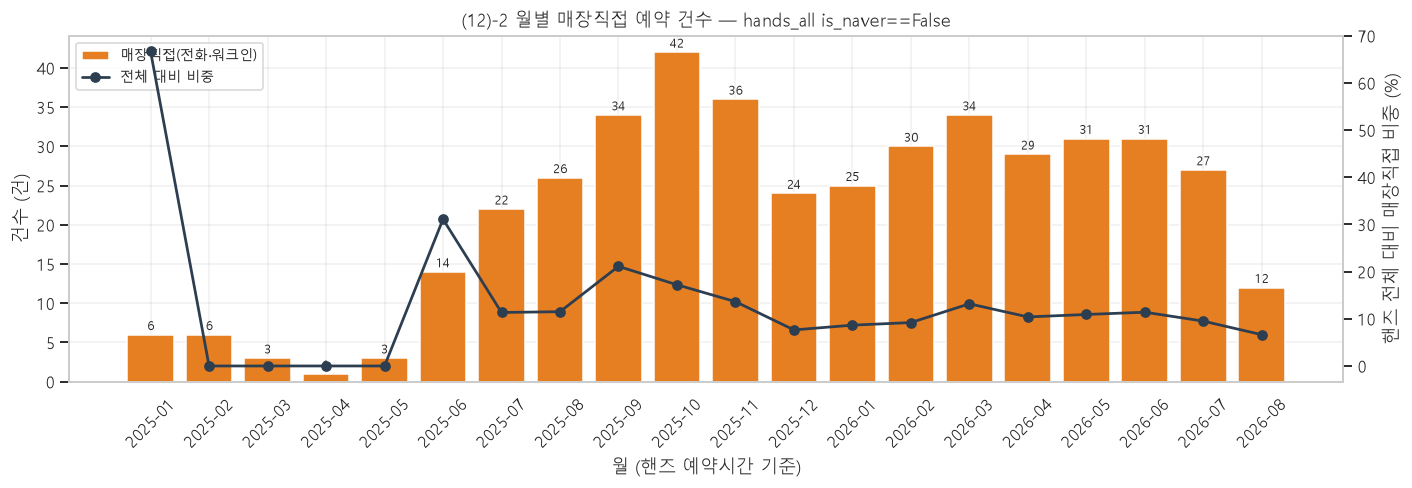

In [58]:
# -- (12) 그래프: 월별 추이 --
fig, ax = plt.subplots(figsize=(13, 4.6))
_x = _wm.index.astype(str)
ax.bar(_x, _wm["매장직접 건수"], color="#e67e22", label="매장직접(전화·워크인)")
for i, v in enumerate(_wm["매장직접 건수"]):
    ax.annotate(f"{int(v)}", (i, v), textcoords="offset points", xytext=(0, 3),
                ha="center", fontsize=8)
ax.set_title("(12)-2 월별 매장직접 예약 건수 — hands_all is_naver==False")
ax.set_xlabel("월 (핸즈 예약시간 기준)"); ax.set_ylabel("건수 (건)")
ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(_x, _wm["매장직접 비중(%)"], color="#2c3e50", marker="o", lw=1.8, label="전체 대비 비중")
ax2.set_ylabel("핸즈 전체 대비 매장직접 비중 (%)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

---
# 대조표

위 분석에서 나온 핵심 수치를 한 표로 모았다. **항목 / 값 / 산출 근거** 3컬럼이며
값은 반올림 정리 없이 계산 결과 그대로다(표시 자릿수만 고정).

In [59]:
# -- 최종 대조표 --
_extra = [
    ("분석 기간", f"{R.use_dt.min():%Y-%m-%d} ~ {R.use_dt.max():%Y-%m-%d}", "reservations use_dt min/max"),
    ("상태 분포", " / ".join(f"{k} {v:,}" for k, v in R.status.value_counts().items()),
     "reservations status value_counts"),
    ("메뉴 라인 수 (원본)", f"{len(L):,}행", "menu_lines 전체"),
    ("메뉴 라인 수 (비시술 제외)", f"{len(LX):,}행", "menu_lines 에서 category=='비시술' 제외"),
    ("대표시술 미부여 예약", f"{int(R.rep_cat.isna().sum()):,}건", "시술 라인이 없거나 비시술뿐인 예약"),
    ("카테고리 매핑 누락 메뉴", f"{len(_missing)}종", "menu_lines.menu − menu_category.csv.menu"),
]
for it, v, b in _extra:
    RESULTS.append({"항목": it, "값": v, "산출 근거": b})

# ── ⑪-B 관측 소요시간 — 기존 #1~#151 뒤에 붙는다 ─────────────────────────────
# 위 _extra 까지가 기존 151행이다. 여기서부터 #152. 기존 항목명·순서를 재사용하지 말 것.
for _c in PRIORITY:
    if _c in DUR_OBS_CAT:
        rec(f"관측 소요시간 · {_c}(중앙값)", f"{DUR_OBS_CAT[_c]:.2f}h",
            f"done_dt-use_dt 당일처리 {int(OBS_N_CAT[_c]):,}건 · rep_cat 기준 중앙값")
_top = "뿌리탈색이벤트"
rec(f"관측 소요시간 · {_top}(중앙값)", f"{DUR_OBS_MENU[_top]:.2f}h",
    f"최다 판매 메뉴 · 유료메뉴 1종 예약 {int(_sdm_m.loc[_top,'n']):,}건의 중앙값")
rec("관측 표본 건수", f"{OBS_N_TOTAL:,}건 (완료 {len(DONE):,}건의 {OBS_N_TOTAL/len(DONE)*100:.1f}%)",
    "이용완료 & done_dt 당일 & gap>0")
rec("관측 매칭 커버리지",
    f"메뉴 {OBS_COV['메뉴']:,} / 카테고리 {OBS_COV['카테고리']:,} / 미매칭 {OBS_COV['미매칭']:,}",
    "완료 예약에 관측 소요시간을 부여한 경로별 건수")
rec("병행배수 중앙값(하루 2건 이상)", f"{PARALLEL_MED:.2f}배",
    "완전관측 디자이너-일의 (구간 합산h / 구간 합집합 점유h) 중앙값")
for _d in UTIL_UNION.index:
    rec(f"점유 기준 가동률(합집합) · {_d}", f"{UTIL_UNION[_d]:.2f}%",
        "완전관측 디자이너-일의 구간 합집합 평균 / 10h")
for _c, _v in OBS_RATIO.items():
    rec(f"가정A 대비 관측 배율 · {_c}", f"{_v:.2f}배",
        f"관측 중앙값 {DUR_OBS_CAT[_c]:.2f}h / 가정 A {DUR_H[_c]:.2f}h")

for _d in UTIL_ADJ.sort_values(ascending=False).index:
    rec(f"점유 기준 가동률(보정) · {_d}", f"{UTIL_ADJ[_d]:.2f}%",
        "하루 건수로 조건화한 보정 — Σ P(k)·curve[k] / 10h (⑪-B2d). 여전히 하한")

COMPARE = pd.DataFrame(RESULTS)[["항목", "값", "산출 근거"]]
COMPARE.index = range(1, len(COMPARE) + 1)
COMPARE.index.name = "#"

with pd.option_context("display.max_rows", None, "display.max_colwidth", 90):
    display(COMPARE)

print(f"\n대조표 {len(COMPARE)}행")
_out = Path("compare_table.csv")
COMPARE.to_csv(_out, encoding="utf-8-sig")
print(f"CSV 저장: {_out}")

,항목,값,산출 근거
#,,,
1,완료 총매출,"308,975,650원",reservations status==이용완료 의 paid 합
2,객단가 중앙값,"100,000원",reservations status==이용완료 의 paid 중앙값
3,객단가 평균,"113,095원",reservations status==이용완료 의 paid 평균
4,객단가 중앙값 · 탈색,"150,000원",완료 건 중 rep_cat=탈색 의 paid 중앙값
5,객단가 중앙값 · 펌,"145,000원",완료 건 중 rep_cat=펌 의 paid 중앙값
6,객단가 중앙값 · 염색,"39,000원",완료 건 중 rep_cat=염색 의 paid 중앙값
7,객단가 중앙값 · 컷,"29,000원",완료 건 중 rep_cat=컷 의 paid 중앙값
8,객단가 중앙값 · 클리닉,"39,000원",완료 건 중 rep_cat=클리닉 의 paid 중앙값
9,객단가 중앙값 · 스타일링,"32,000원",완료 건 중 rep_cat=스타일링 의 paid 중앙값



대조표 180행
CSV 저장: compare_table.csv
